# COE305 Machine Learning — Practical Project (Fall 2026–2027)

| Student | Student ID |
|---|---|
| Mohammed Bendardf | 229912053 |
| Abdalraouf Alkabir | 2309015482 |

**Deadline:** 20 November 2026, 17:00 (Istanbul, UTC+3)

Tasks: (1) Cross-validation, (2) Feature selection, (3) PCA feature extraction — Spambase; (4) K-Means clustering — Wholesale Customers; (5) Decision trees and ensembles — Spambase.

**Protocol used everywhere**
* Python only: scikit-learn, XGBoost, pandas, NumPy, Matplotlib. No hosted/AutoML service.
* Classification: ONE stratified train/test split (`test_size=0.2`, `random_state=42`) created once by `get_split` (setup cell) and reused in Tasks 1, 2, 3 and 5. The test set is used only for final evaluation; every choice of model, `k`, number of components or hyper-parameter is made with stratified CV on the training set.
* Scaling, feature selection and PCA live inside `sklearn.pipeline.Pipeline` objects, so in CV they are refit inside each training fold and at test time they are fitted on the training set only.
* Seeds: `random_state=42` for every estimator / splitter, `np.random.seed(42)`.
* Figures go to `figures/` (PNG, 150 dpi), tables to `tables/` (CSV). Each key figure/table is followed by a markdown interpretation.

In [1]:
import os, re, sys, time, random, functools, warnings
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path

# Package versions that produced the reported numbers (the result-relevant pins from requirements.txt)
PINS = {"numpy": "2.1.3", "pandas": "2.2.3", "scikit-learn": "1.5.2", "xgboost": "2.1.3",
        "matplotlib": "3.9.2", "scipy": "1.18.1", "joblib": "1.6.0"}


def installed_version(dist):
    try:
        return version(dist)
    except PackageNotFoundError:
        return None


def check_pins(installed=installed_version):
    """Print one warning line with the %pip command if an installed version differs from its pin."""
    differ = [f"{dist}=={pin}" for dist, pin in PINS.items() if installed(dist) != pin]
    if differ:
        print(f"Version warning: installed packages differ from the pinned ones; run  %pip install {' '.join(differ)}  "
              "and restart the kernel (Python 3.12 or 3.13 needed for the reported numbers).")


check_pins()

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display
import sklearn, xgboost
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

SEED = 42
ROOT = Path.cwd()                                     # the folder holding this notebook
DATA, FIG, TAB = ROOT / "data", ROOT / "figures", ROOT / "tables"
SPEND = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]


def set_seeds(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)


def get_split(X, y):
    """The ONE stratified train/test split used for every classification task."""
    return train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)


def skf(k=5):
    return StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED)


def clf_metrics(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0)}


def save_fig(fig, name):
    FIG.mkdir(exist_ok=True)
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")


def save_table(df, name, index=False):
    TAB.mkdir(exist_ok=True)
    df.to_csv(TAB / f"{name}.csv", index=index)
    return df


def adaboost_kwargs(sklearn_version=sklearn.__version__):
    """AdaBoost runs SAMME: scikit-learn < 1.6 needs algorithm="SAMME"; 1.6+ uses it by default and 1.8 removed the option."""
    major, minor = (int(part) for part in re.match(r"(\d+)\.(\d+)", sklearn_version).groups())
    return {"algorithm": "SAMME"} if (major, minor) < (1, 6) else {}


set_seeds(SEED)              # np.random.seed(42), random.seed(42), PYTHONHASHSEED
warnings.filterwarnings("ignore", category=FutureWarning)
# two known, harmless library warnings (see "Challenges"): scikit-learn 1.5 passes a deprecated `iprint` option to
# SciPy's L-BFGS, and GridSearchCV's masked result arrays warn when a grid contains max_depth=None
warnings.filterwarnings("ignore", message="Unknown solver options")
warnings.filterwarnings("ignore", message="invalid value encountered in cast")
os.environ["PYTHONWARNINGS"] = "ignore:Unknown solver options,ignore:invalid value encountered in cast"  # same, in joblib workers
N_JOBS = -1                  # parallel CV; results are still deterministic (seeded estimators/splitters)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE), "figure.dpi": 100,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8985",
    "axes.titleweight": "bold", "axes.titlesize": 11, "lines.linewidth": 2,
    "legend.frameon": False, "savefig.facecolor": "white"})
SEQ = LinearSegmentedColormap.from_list("seq", ["#f0f6fe", "#86b6ef", "#2a78d6", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#eb6834"])
GRAY = "#52514e"
KEY = {}                     # key numbers, collected for the summary table / reproducibility check

print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| sklearn", sklearn.__version__, "| xgboost", xgboost.__version__, "| matplotlib", matplotlib.__version__)

python 3.12.13 | numpy 2.1.3 | pandas 2.2.3 | sklearn 1.5.2 | xgboost 2.1.3 | matplotlib 3.9.2


## 0. Data and the single train/test split (Spambase)

Spambase (UCI #94) has 4,601 e-mails, 57 numeric features (48 word frequencies, 6 character frequencies, 3 capital-run-length statistics) and the binary label `spam`. The next cell loads `data/spambase.csv` and `data/wholesale.csv`. A missing file is downloaded from the UCI repository (OpenML as a fallback), checked against the SHA-256 hash of the committed CSV and saved to `data/`. Each download attempt is limited to 3 minutes.

In [2]:
import hashlib, http.client, io, socket, ssl, tempfile, threading, urllib.error, urllib.parse, urllib.request, zipfile
from sklearn.datasets import fetch_openml

# Data: data/<name>.csv -> UCI zip over HTTPS -> OpenML. Every frame is put in the committed CSV form and must match the
# SHA-256 of the committed file; a download is saved to data/ only if the file is still missing.
SHA256 = {"spambase": "294f6669272928152a8f5cf9aec31bfd902eb06a05b8bc87baf0110a95e8ee83",
          "wholesale": "d0213b7d856bc7f98f2f52a86bedb5cb57d5b8e19959605e75bd4532d4ee0896"}
UCI = {"spambase": "https://archive.ics.uci.edu/static/public/94/spambase.zip",
       "wholesale": "https://archive.ics.uci.edu/static/public/292/wholesale+customers.zip"}
MANUAL = {"spambase": f"download {UCI['spambase']} and save spambase.data as data/spambase.csv with a header row "
                      "(the 57 names in spambase.names, then spam)",
          "wholesale": f"download {UCI['wholesale']} and save its CSV file as data/wholesale.csv"}
TIMEOUT = 180                # seconds per download attempt
try:
    import certifi
    TLS = ssl.create_default_context(cafile=certifi.where())
except ImportError:
    TLS = ssl.create_default_context()


class _HTTPSWithTimeout(urllib.request.HTTPSHandler):
    """HTTPS with the TLS context above; every connection gets a TIMEOUT-second socket timeout, also one that
    fetch_openml opens after its attempt's time limit. An attempt given up at its limit opens no new connection
    (fetch_openml retries its metadata requests 3 times, whatever n_retries says)."""
    def https_open(self, req):
        if getattr(threading.current_thread(), "given_up", False):
            raise ConnectionAbortedError("attempt given up at its time limit")
        req.timeout = TIMEOUT
        return super().https_open(req)


urllib.request.install_opener(urllib.request.build_opener(_HTTPSWithTimeout(context=TLS)))  # UCI and OpenML
# fetch_openml warns before its own retries; each source's outcome is in the one-line summary instead. Set for the whole
# session, so an attempt still running after its time limit (see _within_limit) prints nothing into a later cell either.
warnings.filterwarnings("ignore", module=r"sklearn\.datasets\._openml")


class HashMismatch(ValueError):
    """The data differs from the committed CSV."""


class DataUnavailable(RuntimeError):
    """No source gave the expected data; Jupyter shows only this one-line message."""
    def _render_traceback_(self):
        return [str(self)]


def _check_elapsed(start):
    if time.perf_counter() - start > TIMEOUT:
        raise TimeoutError(f"no complete reply within {TIMEOUT} s")


def _within_limit(call, *args):
    """call(*args) in a daemon thread: the attempt ends after TIMEOUT seconds in total, also while a server sends slowly
    or fetch_openml waits to retry. An attempt still running then is left to finish on its own: it opens no new HTTPS
    connection, so it ends at most one socket timeout plus 1 s (fetch_openml's wait before a retry) after its server
    goes silent; its result and error are never used, it writes no file (only the thread that runs the cell writes to
    data/; fetch_openml runs with cache=False) and it prints nothing (warnings filter above)."""
    start, outcome = time.perf_counter(), {}

    def attempt():
        try:
            outcome["value"] = call(*args)
        except BaseException as err:     # raised again below, in the thread that runs the cell
            outcome["error"] = err

    worker = threading.Thread(target=attempt, daemon=True)
    worker.given_up = False
    worker.start()
    worker.join(TIMEOUT)
    if worker.is_alive():
        worker.given_up = True           # read by _HTTPSWithTimeout in the attempt's thread
        raise TimeoutError(f"no complete reply within {TIMEOUT} s")
    if "error" in outcome:
        raise outcome["error"]
    _check_elapsed(start)
    return outcome["value"]


def _read_reply(url):
    start = time.perf_counter()
    chunks = []
    with urllib.request.urlopen(url, timeout=TIMEOUT) as reply:   # the socket timeout holds until the body is read
        while chunk := reply.read1(1 << 16):                      # what has arrived, so a slow reply is checked often
            chunks.append(chunk)
            _check_elapsed(start)
    _check_elapsed(start)
    return b"".join(chunks)


def _download(url):
    return _within_limit(_read_reply, url)


def _zip_member(blob, suffix):
    archive = zipfile.ZipFile(io.BytesIO(blob))
    name = next((n for n in archive.namelist() if n.endswith(suffix)), None)
    if name is None:
        raise KeyError(f"no *{suffix} in the zip")
    return archive.read(name)


def _uci_spambase():
    blob = _download(UCI["spambase"])
    names = [ln.split(":")[0].strip() for ln in _zip_member(blob, "spambase.names").decode("utf-8").splitlines()
             if ":" in ln and "continuous" in ln and not ln.startswith("|")]
    return pd.read_csv(io.BytesIO(_zip_member(blob, "spambase.data")), header=None, names=names + ["spam"])


def _uci_wholesale():
    return pd.read_csv(io.BytesIO(_zip_member(_download(UCI["wholesale"]), ".csv")))


def _fetch_openml_frame(data_id, parser):     # cache=False: nothing is written, so data/openml/ is never created
    return fetch_openml(data_id=data_id, as_frame=True, data_home=str(DATA), cache=False, n_retries=1,
                        parser=parser).frame


def _openml(data_id, parser):
    previous = socket.getdefaulttimeout()
    socket.setdefaulttimeout(TIMEOUT)            # for every socket fetch_openml opens during the attempt
    try:
        return _within_limit(_fetch_openml_frame, data_id, parser)
    except TypeError as err:          # an ARFF parser that fails on this file in some scikit-learn/pandas versions
        raise ValueError("the OpenML file could not be parsed") from err
    finally:
        socket.setdefaulttimeout(previous)


def _openml_spambase():      # OpenML 44 = UCI Spambase; '%3B'-style names for char_freq_<symbol>, label 'class'
    # liac-arff: the pandas parser fails on this file with scikit-learn 1.9 + pandas 3
    return _openml(44, "liac-arff").rename(columns=lambda c: "spam" if c == "class" else urllib.parse.unquote(c))


def _openml_wholesale():     # OpenML 1511 = UCI Wholesale customers; V1 repeats Region, V2-V7 are the six spend columns
    # pandas parser: liac-arff would read the integer columns as floats
    return _openml(1511, "pandas")[["Channel", "Region"] + [f"V{i}" for i in range(2, 8)]].set_axis(["Channel", "Region"] + SPEND, axis=1)


SOURCES = {"spambase": [("UCI", _uci_spambase), ("OpenML", _openml_spambase)],
           "wholesale": [("UCI", _uci_wholesale), ("OpenML", _openml_wholesale)]}


def normalised(df, name):
    """The frame in committed CSV form (CSV round trip) and its CSV text; HashMismatch if it is not the expected data."""
    df = pd.read_csv(io.StringIO(df.to_csv(index=False)))
    text = df.to_csv(index=False, lineterminator="\n")
    if hashlib.sha256(text.encode("utf-8")).hexdigest() != SHA256[name]:
        raise HashMismatch(name)
    return df, text


def _reason(err):
    """A short phrase for a failed source."""
    if isinstance(err, FileNotFoundError):
        return "no local copy"
    if isinstance(err, HashMismatch):
        return "SHA-256 differs from the expected data"
    if isinstance(err, urllib.error.HTTPError):
        return f"HTTP {err.code}"
    cause = err.reason if isinstance(err, urllib.error.URLError) else err
    if isinstance(cause, ssl.SSLError):
        return "TLS error"
    if isinstance(cause, TimeoutError):
        return "timed out"
    if isinstance(err, (urllib.error.URLError, ConnectionError, http.client.HTTPException)):
        return "network error"
    if isinstance(err, OSError):
        return "file error"
    return "unexpected content"


def _save_new(path, text):
    """Write text via a temp file + rename if path is still missing; returns what happened."""
    if path.exists():
        return f"{path.name} kept as it was"
    try:
        path.parent.mkdir(exist_ok=True)
        fd, tmp = tempfile.mkstemp(dir=path.parent, suffix=".tmp")
        try:
            with os.fdopen(fd, "w", encoding="utf-8", newline="") as f:
                f.write(text)
            os.replace(tmp, path)    # a file created after the exists() check would be replaced (one run at a time)
        finally:
            if os.path.exists(tmp):
                os.unlink(tmp)
    except OSError as err:
        return f"could not save data/{path.name} ({err.strerror or type(err).__name__})"
    return f"saved data/{path.name}"


def load_data(name):
    """data/<name>.csv if it holds the expected data, else the UCI zip, else OpenML (both checked by SHA-256)."""
    path = DATA / f"{name}.csv"
    failed = []
    for label, read in [("local file", lambda: pd.read_csv(path))] + SOURCES[name]:
        try:
            df, text = normalised(read(), name)
        # OSError covers FileNotFoundError, urllib.error.URLError, TimeoutError (socket.timeout) and ssl.SSLError
        except (OSError, http.client.HTTPException, zipfile.BadZipFile, ValueError, KeyError) as err:
            failed.append(f"{label}: {_reason(err)}")
            continue
        if failed:
            print(f"{name}: loaded from {label}, SHA-256 verified; {_save_new(path, text)} ({'; '.join(failed)})")
        return df
    raise DataUnavailable(f"Could not load the {name} data ({'; '.join(failed)}). Check the internet connection and run "
                          f"this cell again, or {MANUAL[name]}.")


CHAR_NAMES = {";": "semicolon", "(": "paren", "[": "bracket", "!": "excl", "$": "dollar", "#": "hash"}


def load_spambase():
    """Spambase features + label. The six char_freq_<symbol> columns are renamed
    (e.g. char_freq_[ -> char_freq_bracket) because XGBoost rejects '[', ']' and '<' in names."""
    df = load_data("spambase")
    df.columns = [f"char_freq_{CHAR_NAMES[c[-1]]}" if c.startswith("char_freq_") and c[-1] in CHAR_NAMES else c
                  for c in df.columns]
    return df.drop(columns="spam"), df["spam"].astype(int)


def load_wholesale():
    return load_data("wholesale")

In [3]:
X, y = load_spambase()
X_train, X_test, y_train, y_test = get_split(X, y)      # the ONE split for Tasks 1, 2, 3, 5
split = pd.DataFrame({"set": ["full", "train", "test"],
                      "rows": [len(y), len(y_train), len(y_test)],
                      "spam_rate": [y.mean(), y_train.mean(), y_test.mean()]})
save_table(split, "t0_split_summary")
display(split.round(4))
print("features:", X.shape[1], "| missing values:", int(X.isna().sum().sum()))
# Spambase: exact duplicates, train/test overlap and word-feature sparsity
print(f"exact duplicate rows (all {X.shape[1]} features and the label equal; every copy after the first; all {len(y):,} e-mails):",
      int(X.assign(label=y).duplicated().sum()))
print(f"test e-mails with an exact copy in the training set (all {X.shape[1]} features and the label equal; "
      f"{len(y_test):,} test vs {len(y_train):,} training e-mails):",
      len(X_test.assign(label=y_test).merge(X_train.assign(label=y_train).drop_duplicates())), "of", f"{len(y_test):,}")
word_zero = X.filter(regex="^word_freq_").eq(0).mean()      # per word feature: share of e-mails in which it is 0
print(f"word features zero in >= 90% of all {len(y):,} e-mails: {int(word_zero.ge(0.9).sum())} of {word_zero.size}"
      f" | median zero share of the {word_zero.size}: {word_zero.median():.0%} | zero share of 3d / table / parts: "
      + " / ".join(f"{word_zero[f'word_freq_{w}']:.0%}" for w in ("3d", "table", "parts")))

,set,rows,spam_rate
0,full,4601,0.3940
1,train,3680,0.3940
2,test,921,0.3941


features: 57 | missing values: 0
exact duplicate rows (all 57 features and the label equal; every copy after the first; all 4,601 e-mails): 391
test e-mails with an exact copy in the training set (all 57 features and the label equal; 921 test vs 3,680 training e-mails): 104 of 921
word features zero in >= 90% of all 4,601 e-mails: 19 of 48 | median zero share of the 48: 86% | zero share of 3d / table / parts: 99% / 99% / 98%


**Interpretation (Table `t0_split_summary`).** The stratified split gives 3,680 training and 921 test e-mails, and the spam rate is 39.4% in the full data, the training set and the test set alike, so stratification worked. The classes are mildly imbalanced (about 61/39). A classifier that always predicts "ham" would score 60.6% accuracy, which is the floor every model below must beat. Because of this imbalance we report precision, recall and F1 for the spam class next to accuracy. There are no missing values.

---
# Task 1 — Cross-Validation (Spambase)
### 1.1 Decision Tree baseline on the train/test split
Classifier: `DecisionTreeClassifier(random_state=42)` with default settings (fully grown tree).

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate, cross_val_score, RepeatedStratifiedKFold

def dt(**kw):
    return DecisionTreeClassifier(random_state=SEED, **kw)

dt_base = dt().fit(X_train, y_train)
t1_base = pd.DataFrame([{"set": "train", **clf_metrics(y_train, dt_base.predict(X_train))},
                        {"set": "test",  **clf_metrics(y_test,  dt_base.predict(X_test))}])
save_table(t1_base, "t1_baseline")
display(t1_base.round(4))
print("tree depth:", dt_base.get_depth(), "| leaves:", dt_base.get_n_leaves())
KEY["T1 baseline DT test accuracy"] = t1_base.loc[1, "accuracy"]

,set,accuracy,precision,recall,f1
0,train,0.9997,1.0000,0.9993,0.9997
1,test,0.9110,0.8828,0.8926,0.8877


tree depth: 32 | leaves: 237


**Interpretation (Table `t1_baseline`).** The unrestricted tree grows to depth 32 with 237 leaves and almost memorises the training set (train accuracy 0.9997, F1 0.9997). On the test set it drops to accuracy 0.9110, precision 0.8828, recall 0.8926 and F1 0.8877. The 9-point train–test gap is classic over-fitting of a fully grown tree: its leaves describe individual training e-mails, not general patterns. Precision and recall are close, so the errors are spread roughly evenly between false alarms and missed spam. Training accuracy is therefore useless as a performance estimate here, which motivates the cross-validation below.

### 1.2–1.3 Stratified K-Fold CV with K = 3, 5, 10 (training set only)
For each K we run `StratifiedKFold(K, shuffle=True, random_state=42)` on the training set and record accuracy and F1 per fold. Runtime is the median of 3 timed repetitions (single process, `n_jobs=1`, so the times are comparable).
As an extra check on the *variability of the estimate itself* we also repeat each K-fold CV with 10 different shuffles (`RepeatedStratifiedKFold`, seeded) and report the standard deviation of the 10 CV means.

,K,mean_accuracy,std_accuracy,mean_f1,std_f1,time_s,train_rows_per_fold,repeated_cv_mean_acc,std_of_cv_mean_over_10_repeats
0,3,0.9054,0.0036,0.8804,0.0051,0.1540,2453,0.9051,0.0045
1,5,0.9136,0.0109,0.8910,0.0134,0.3209,2944,0.9101,0.0034
2,10,0.9117,0.0107,0.8884,0.0136,1.0029,3312,0.9111,0.0021


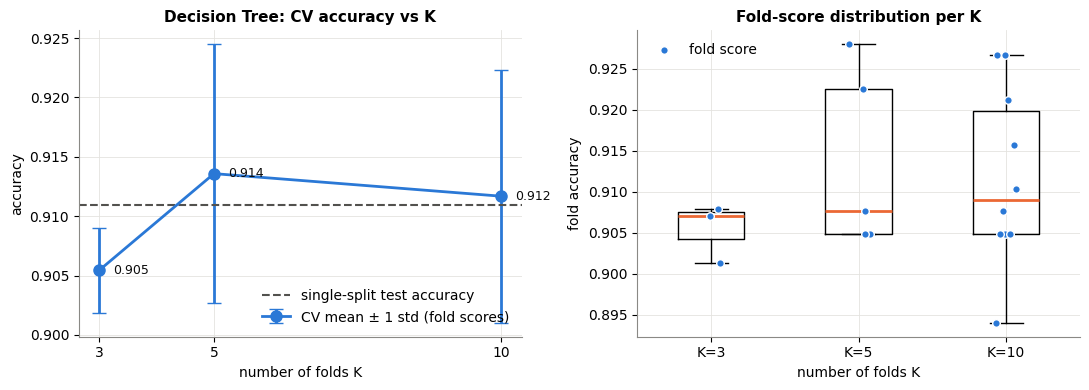

In [5]:
rows, fold_rows = [], []
for K in [3, 5, 10]:
    times = []
    for _ in range(3):
        t0 = time.perf_counter()
        cv = cross_validate(dt(), X_train, y_train, cv=skf(K), scoring=["accuracy", "f1"], n_jobs=1)
        times.append(time.perf_counter() - t0)
    rep = cross_val_score(dt(), X_train, y_train, scoring="accuracy", n_jobs=N_JOBS,
                          cv=RepeatedStratifiedKFold(n_splits=K, n_repeats=10, random_state=SEED))
    rep_means = rep.reshape(10, K).mean(axis=1)          # one CV estimate per repetition
    rows.append({"K": K,
                 "mean_accuracy": cv["test_accuracy"].mean(), "std_accuracy": cv["test_accuracy"].std(ddof=1),
                 "mean_f1": cv["test_f1"].mean(), "std_f1": cv["test_f1"].std(ddof=1),
                 "time_s": np.median(times), "train_rows_per_fold": int(round(len(y_train) * (K - 1) / K)),
                 "repeated_cv_mean_acc": rep_means.mean(), "std_of_cv_mean_over_10_repeats": rep_means.std(ddof=1)})
    fold_rows += [{"K": K, "fold": i + 1, "accuracy": a, "f1": f}
                  for i, (a, f) in enumerate(zip(cv["test_accuracy"], cv["test_f1"]))]
t1_cv = save_table(pd.DataFrame(rows), "t1_cv_comparison")
t1_folds = save_table(pd.DataFrame(fold_rows), "t1_fold_scores")
display(t1_cv.round(4))
for K in [3, 5, 10]:
    KEY[f"T1 CV K={K} mean accuracy"] = t1_cv.loc[t1_cv.K == K, "mean_accuracy"].item()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.errorbar(t1_cv.K, t1_cv.mean_accuracy, yerr=t1_cv.std_accuracy, marker="o", ms=8, capsize=5,
            color=PALETTE[0], label="CV mean ± 1 std (fold scores)")
ax.axhline(t1_base.loc[1, "accuracy"], ls="--", color=GRAY, lw=1.5, label="single-split test accuracy")
for _, r in t1_cv.iterrows():
    ax.annotate(f"{r.mean_accuracy:.3f}", (r.K, r.mean_accuracy), textcoords="offset points", xytext=(10, 0),
                va="center", fontsize=9, color="#0b0b0b")
ax.set(xticks=[3, 5, 10], xlabel="number of folds K", ylabel="accuracy",
       title="Decision Tree: CV accuracy vs K")
ax.legend(loc="lower right")
ax = axes[1]
data = [t1_folds.loc[t1_folds.K == K, "accuracy"].values for K in [3, 5, 10]]
ax.boxplot(data, widths=0.45, medianprops=dict(color=PALETTE[1], lw=2))
rng = np.random.default_rng(SEED)
for i, d in enumerate(data, start=1):
    ax.scatter(i + rng.uniform(-0.08, 0.08, len(d)), d, s=30, color=PALETTE[0], zorder=3,
               edgecolor="white", linewidth=1, label="fold score" if i == 1 else None)
ax.set_xticks([1, 2, 3], ["K=3", "K=5", "K=10"])
ax.set(xlabel="number of folds K", ylabel="fold accuracy", title="Fold-score distribution per K")
ax.legend(loc="upper left")
fig.tight_layout(); save_fig(fig, "t1_cv_accuracy_vs_k"); plt.show()

**Interpretation (Tables `t1_cv_comparison` and `t1_fold_scores` (per-fold values), Figure `t1_cv_accuracy_vs_k`).**
* **Mean estimates.** K=3 gives 0.9054 ± 0.0036, K=5 gives 0.9136 ± 0.0109 and K=10 gives 0.9117 ± 0.0107 (F1: 0.880, 0.891, 0.888). K=3 is clearly the most pessimistic. K=5 and K=10 agree to within 0.002.
* **Fold std (left error bars, right boxplot).** The spread of individual fold scores is smallest for K=3 (3 folds of about 1,227 e-mails) and about three times larger for K=5/10 (the K=3 value rests on only 3 folds, so it is itself imprecise). Smaller validation folds (736 and 368 e-mails) make each fold score noisier. One K=10 fold scores as low as 0.894 and two as high as 0.927.
* **Variability of the estimate itself** (extra repeated-CV columns). Over 10 different shuffles the std of the CV *mean* falls from 0.0045 (K=3) to 0.0034 (K=5) to 0.0021 (K=10). So larger K gives a more stable estimate even though its individual folds are noisier. The repeated means (0.905, 0.910, 0.911) also show that the single K=5 run (0.9136) was slightly lucky.
* **Runtime** grows with K: about 0.15 s, 0.32 s and 1.00 s. K=10 fits ten trees, each on 90% of the data. Wall-clock times depend on the machine and its load (up to about 4.5× between runs of this notebook) and are not results; only the ordering is stable. On the same machine they are the only numbers that change beyond floating-point rounding.
* The single-split test accuracy (dashed line, 0.9110) falls inside the K=5 and K=10 intervals, just above the K=3 interval (0.9018–0.9090), and is almost identical to the K=10 estimate.

### 1.4 Discussion
* **Bias.** With K folds each model trains on (K−1)/K of the 3,680 training rows: 2,453 rows for K=3, 2,944 for K=5 and 3,312 for K=10. A tree trained on less data is slightly worse, so small K gives a *pessimistically biased* estimate. That is exactly what we see: K=3 is about 0.006–0.008 below K=5/10, and the bias shrinks as K grows.
* **Variance.** Two things must be kept apart. The std *across folds* is about three times larger for K=5/10 (≈0.011) than for K=3 (0.0036), because smaller validation folds give noisier individual scores. The variance *of the CV mean* (how much the estimate changes if the data were shuffled differently) shrinks with K (0.0045 → 0.0021), because the estimate averages more fold scores and each model is trained on more data, so the individual models vary less. The growing overlap of the training sets works in the opposite direction (it makes the fold scores more correlated); for very large K (leave-one-out) it can dominate and increase the variance of the mean again. Up to K=10 we do not see that here.
* **Runtime** grows with K (K model fits on ever-larger training sets). For a fast decision tree even K=10 takes only about 1.0 s. For the ensembles in Task 5 we use K=5 as the compromise between bias, stability and the cost of hundreds of grid-search fits.
* **CV vs single split.** The single split gives one number (0.9110) from 921 test e-mails, and its binomial standard error is about √(0.91·0.09/921) ≈ 0.0094. That is as large as the fold std, and with one split we cannot measure it. CV uses every training row for validation exactly once and returns both a mean and a spread. Here both approaches agree (0.911 vs 0.912–0.914 for K=5/10), which confirms that the split is representative. Only CV, though, tells us the uncertainty, and only CV lets us *select* models without touching the test set.

---
# Task 2 — Feature Selection (Spambase)
Classifier for all selection methods: the same `DecisionTreeClassifier(random_state=42)` as in Task 1, so the all-feature baseline is **reused from Task 1** (CV K=5 mean accuracy on the training set, and the Task 1 test metrics).

Three selection methods, each placed as the first step of a `Pipeline` so that it is refit on every CV training fold:
1. **Filter — mutual information**: `SelectKBest(mutual_info_classif)` (MI estimator seeded with `random_state=42`).
2. **Wrapper — RFE**: `RFE(DecisionTreeClassifier, step=1)`, which removes the least important feature one at a time.
3. **Embedded — tree importances**: `SelectFromModel(RandomForestClassifier(200 trees), max_features=k, threshold=-inf)`, i.e. top-k RF importances.

k ∈ {5, 10, 15, 20, 30, 40, 57} is chosen by 5-fold stratified CV on the training set (`GridSearchCV`); the test set is scored once, with the chosen k.

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import SelectKBest, mutual_info_classif, RFE, SelectFromModel
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

mi_score = functools.partial(mutual_info_classif, random_state=SEED)
K_GRID = [5, 10, 15, 20, 30, 40, 57]
FS = {
    "MI (SelectKBest)": (SelectKBest(mi_score), "fs__k"),
    "RFE (Decision Tree)": (RFE(dt(), step=1), "fs__n_features_to_select"),
    "SelectFromModel (RF importance)": (SelectFromModel(RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1),
                                                        threshold=-np.inf), "fs__max_features"),
}
t2_search, curve_rows = {}, []
t0 = time.perf_counter()
for name, (sel, pname) in FS.items():
    pipe = Pipeline([("fs", clone(sel)), ("clf", dt())])
    gs = GridSearchCV(pipe, {pname: K_GRID}, cv=skf(5), scoring="accuracy", n_jobs=N_JOBS).fit(X_train, y_train)
    t2_search[name] = gs
    for k, m, s in zip(K_GRID, gs.cv_results_["mean_test_score"], gs.cv_results_["std_test_score"]):
        curve_rows.append({"method": name, "k": k, "cv_mean_acc": m, "cv_std_acc": s})
print(f"search time {time.perf_counter() - t0:.1f}s")
t2_curve = save_table(pd.DataFrame(curve_rows), "t2_cv_accuracy_vs_k")
display(t2_curve.pivot(index="k", columns="method", values="cv_mean_acc").round(4))
base_cv5 = t1_cv.loc[t1_cv.K == 5, "mean_accuracy"].item()           # reused from Task 1 (baseline line in the plot)

search time 34.3s


method,MI (SelectKBest),RFE (Decision Tree),SelectFromModel (RF importance)
k,,,
5,0.8576,0.8736,0.8774
10,0.8832,0.9033,0.8986
15,0.9114,0.9141,0.9130
20,0.9171,0.9155,0.9182
30,0.9149,0.9155,0.9168
40,0.9136,0.9177,0.9166
57,0.9136,0.9136,0.9136


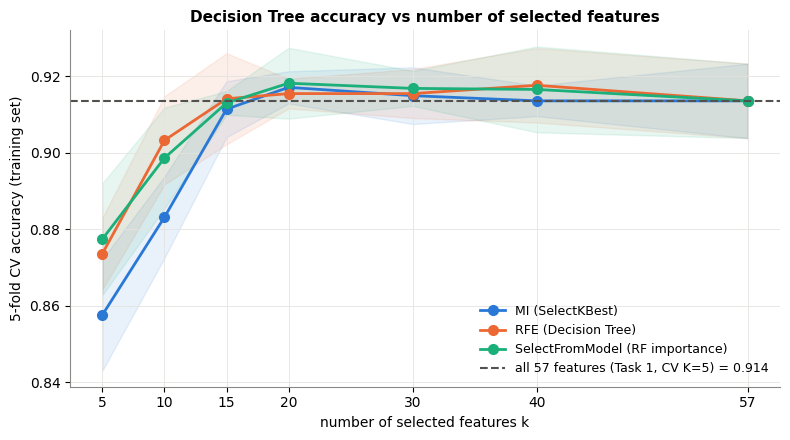

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, name in enumerate(FS):
    d = t2_curve[t2_curve.method == name]
    ax.plot(d.k, d.cv_mean_acc, marker="o", ms=7, color=PALETTE[i], label=name)
    ax.fill_between(d.k, d.cv_mean_acc - d.cv_std_acc, d.cv_mean_acc + d.cv_std_acc, color=PALETTE[i], alpha=0.10)
ax.axhline(base_cv5, ls="--", color=GRAY, lw=1.5, label=f"all 57 features (Task 1, CV K=5) = {base_cv5:.3f}")
ax.set(xlabel="number of selected features k", ylabel="5-fold CV accuracy (training set)", xticks=K_GRID,
       title="Decision Tree accuracy vs number of selected features")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout(); save_fig(fig, "t2_accuracy_vs_k"); plt.show()

**Interpretation (Figure `t2_accuracy_vs_k`, Table `t2_cv_accuracy_vs_k`).** All three curves have the same shape. With 5–10 features the tree is clearly worse than the baseline (MI 0.858 at k=5, RF-importance 0.877, RFE 0.874), which is *under-fitting* from missing information. At k=15 all three are close to the baseline (0.9114–0.9141 vs 0.9136, within ±1 std). Between k=20 and k=40 they sit at or slightly above it (0.9136–0.9182). At k=57 every curve collapses onto the baseline exactly, as it must, because then all features are kept. The shaded ±1 std bands overlap the baseline line for every k ≥ 15, so the plateau is flat within noise. At small k, MI is the weakest method: being univariate, it misses features that are only useful in combination. The two model-based methods (RFE, RF importance) degrade more gracefully.

In [8]:
rows = [{"method": "All features (Task 1 baseline, reused)", "k": 57, "cv_mean_acc": base_cv5,
         **clf_metrics(y_test, dt_base.predict(X_test))}]
for name, gs in t2_search.items():
    rows.append({"method": name, "k": list(gs.best_params_.values())[0], "cv_mean_acc": gs.best_score_,
                 **clf_metrics(y_test, gs.predict(X_test))})
t2_test = save_table(pd.DataFrame(rows), "t2_test_results")
display(t2_test.round(4))
for _, r in t2_test.iterrows():
    KEY[f"T2 {r.method} test accuracy (k={r.k})"] = r.accuracy

,method,k,cv_mean_acc,accuracy,precision,recall,f1
0,"All features (Task 1 baseline, reused)",57,0.9136,0.9110,0.8828,0.8926,0.8877
1,MI (SelectKBest),20,0.9171,0.9099,0.8933,0.8760,0.8846
2,RFE (Decision Tree),40,0.9177,0.9164,0.8907,0.8981,0.8944
3,SelectFromModel (RF importance),20,0.9182,0.9229,0.9056,0.8981,0.9018


**Interpretation (Table `t2_test_results`).** The CV-selected sizes are k=20 for MI, k=40 for RFE and k=20 for the RF-importance selector. All three reach a slightly higher CV accuracy than the all-feature tree: 0.9171, 0.9177 and 0.9182 vs 0.9136. On the test set, the RF-importance selector with 20 features is the best tree (accuracy 0.9229, F1 0.9018, +1.2 points over the baseline). RFE with 40 features is +0.5 points. MI with 20 features is essentially unchanged (−0.1 points). The CV gains (+0.004 to +0.005) are smaller than the CV fold std (0.004–0.010), so we read them as "same accuracy with far fewer features" rather than as a significant improvement. The +1.2-point test gain of SelectFromModel is about one test standard error.

### 2.1 Selected features and overlap
Each selector is fitted on the full training set. The overlap is reported twice: at each method's **CV-selected k** (the features the final models actually use) and, to compare like with like, at a common k = 15.

In [9]:
def selected_features(name, k):
    sel, pname = FS[name]
    p = Pipeline([("fs", clone(sel)), ("clf", dt())]).set_params(**{pname: k}).fit(X_train, y_train)
    return list(X_train.columns[p.named_steps["fs"].get_support()])

K_COMMON = 15
common = {n: selected_features(n, K_COMMON) for n in FS}
best = {n: list(X_train.columns[gs.best_estimator_.named_steps["fs"].get_support()]) for n, gs in t2_search.items()}
sel_tab = pd.DataFrame([{"method": n, "k": K_COMMON, "which": "common k", "features": ", ".join(common[n])} for n in FS] +
                       [{"method": n, "k": len(best[n]), "which": "CV-selected k", "features": ", ".join(best[n])} for n in FS])
save_table(sel_tab, "t2_selected_features")
names = list(FS)
ov = pd.DataFrame(index=names, columns=names, dtype=object)
for a in names:
    for b in names:
        inter = len(set(common[a]) & set(common[b])); union = len(set(common[a]) | set(common[b]))
        ov.loc[a, b] = f"{inter} (J={inter/union:.2f})"
save_table(ov.reset_index().rename(columns={"index": "method"}), "t2_overlap_k15")
pd.set_option("display.max_colwidth", None)
display(sel_tab)
print("Overlap at k=15: shared features (Jaccard index)"); display(ov)
in_all = sorted(set.intersection(*[set(v) for v in common.values()]))
print(f"{len(in_all)} features chosen by all three methods at k=15:", in_all)

# overlap of the features the final (CV-selected) selectors actually use
ov_cv = pd.DataFrame(index=names, columns=names, dtype=object)
for a in names:
    for b in names:
        inter = len(set(best[a]) & set(best[b])); union = len(set(best[a]) | set(best[b]))
        ov_cv.loc[a, b] = f"{inter} (J={inter/union:.2f})"
save_table(ov_cv.reset_index().rename(columns={"index": "method"}), "t2_overlap_cv_k")
print("Overlap at each method's CV-selected k:", {n: len(best[n]) for n in names}); display(ov_cv)
in_all_cv = sorted(set.intersection(*[set(v) for v in best.values()]))
print(f"{len(in_all_cv)} features used by all three final selectors:", in_all_cv)
for n in names:
    only = sorted(set(best[n]) - set().union(*[set(best[m]) for m in names if m != n]))
    print(f"only {n}:", only)

,method,k,which,features
0,MI (SelectKBest),15,common k,"word_freq_our, word_freq_remove, word_freq_free, word_freq_business, word_freq_you, word_freq_your, word_freq_000, word_freq_money, word_freq_hp, word_freq_george, char_freq_excl, char_freq_dollar, capital_run_length_average, capital_run_length_longest, capital_run_length_total"
1,RFE (Decision Tree),15,common k,"word_freq_our, word_freq_remove, word_freq_free, word_freq_business, word_freq_you, word_freq_your, word_freq_money, word_freq_hp, word_freq_george, word_freq_edu, char_freq_excl, char_freq_dollar, capital_run_length_average, capital_run_length_longest, capital_run_length_total"
2,SelectFromModel (RF importance),15,common k,"word_freq_our, word_freq_remove, word_freq_free, word_freq_you, word_freq_your, word_freq_000, word_freq_money, word_freq_hp, word_freq_hpl, word_freq_george, char_freq_excl, char_freq_dollar, capital_run_length_average, capital_run_length_longest, capital_run_length_total"
3,MI (SelectKBest),20,CV-selected k,"word_freq_address, word_freq_all, word_freq_our, word_freq_remove, word_freq_internet, word_freq_free, word_freq_business, word_freq_you, word_freq_your, word_freq_000, word_freq_money, word_freq_hp, word_freq_hpl, word_freq_george, char_freq_paren, char_freq_excl, char_freq_dollar, capital_run_length_average, capital_run_length_longest, capital_run_length_total"
4,RFE (Decision Tree),40,CV-selected k,"word_freq_make, word_freq_all, word_freq_3d, word_freq_our, word_freq_over, word_freq_remove, word_freq_internet, word_freq_mail, word_freq_receive, word_freq_will, word_freq_report, word_freq_free, word_freq_business, word_freq_email, word_freq_you, word_freq_credit, word_freq_your, word_freq_font, word_freq_money, word_freq_hp, word_freq_hpl, word_freq_george, word_freq_650, word_freq_lab, word_freq_data, word_freq_technology, word_freq_1999, word_freq_direct, word_freq_meeting, word_freq_original, word_freq_re, word_freq_edu, char_freq_semicolon, char_freq_paren, char_freq_excl, char_freq_dollar, char_freq_hash, capital_run_length_average, capital_run_length_longest, capital_run_length_total"
5,SelectFromModel (RF importance),20,CV-selected k,"word_freq_our, word_freq_remove, word_freq_internet, word_freq_free, word_freq_business, word_freq_you, word_freq_your, word_freq_000, word_freq_money, word_freq_hp, word_freq_hpl, word_freq_george, word_freq_1999, word_freq_edu, char_freq_paren, char_freq_excl, char_freq_dollar, capital_run_length_average, capital_run_length_longest, capital_run_length_total"


Overlap at k=15: shared features (Jaccard index)


,MI (SelectKBest),RFE (Decision Tree),SelectFromModel (RF importance)
MI (SelectKBest),15 (J=1.00),14 (J=0.88),14 (J=0.88)
RFE (Decision Tree),14 (J=0.88),15 (J=1.00),13 (J=0.76)
SelectFromModel (RF importance),14 (J=0.88),13 (J=0.76),15 (J=1.00)


13 features chosen by all three methods at k=15: ['capital_run_length_average', 'capital_run_length_longest', 'capital_run_length_total', 'char_freq_dollar', 'char_freq_excl', 'word_freq_free', 'word_freq_george', 'word_freq_hp', 'word_freq_money', 'word_freq_our', 'word_freq_remove', 'word_freq_you', 'word_freq_your']
Overlap at each method's CV-selected k: {'MI (SelectKBest)': 20, 'RFE (Decision Tree)': 40, 'SelectFromModel (RF importance)': 20}


,MI (SelectKBest),RFE (Decision Tree),SelectFromModel (RF importance)
MI (SelectKBest),20 (J=1.00),18 (J=0.43),18 (J=0.82)
RFE (Decision Tree),18 (J=0.43),40 (J=1.00),19 (J=0.46)
SelectFromModel (RF importance),18 (J=0.82),19 (J=0.46),20 (J=1.00)


17 features used by all three final selectors: ['capital_run_length_average', 'capital_run_length_longest', 'capital_run_length_total', 'char_freq_dollar', 'char_freq_excl', 'char_freq_paren', 'word_freq_business', 'word_freq_free', 'word_freq_george', 'word_freq_hp', 'word_freq_hpl', 'word_freq_internet', 'word_freq_money', 'word_freq_our', 'word_freq_remove', 'word_freq_you', 'word_freq_your']
only MI (SelectKBest): ['word_freq_address']
only RFE (Decision Tree): ['char_freq_hash', 'char_freq_semicolon', 'word_freq_3d', 'word_freq_650', 'word_freq_credit', 'word_freq_data', 'word_freq_direct', 'word_freq_email', 'word_freq_font', 'word_freq_lab', 'word_freq_mail', 'word_freq_make', 'word_freq_meeting', 'word_freq_original', 'word_freq_over', 'word_freq_re', 'word_freq_receive', 'word_freq_report', 'word_freq_technology', 'word_freq_will']
only SelectFromModel (RF importance): []


**Interpretation (Tables `t2_selected_features`, `t2_overlap_cv_k`, `t2_overlap_k15`).**
* **Features the final models use (CV-selected k).** MI (k=20) and RF importance (k=20) share **18 of their 20 features** (Jaccard 0.82). RFE keeps 40 features and contains 18 of MI's 20 and 19 of RF's 20 (Jaccard 0.43–0.46, low only because its set is twice as large). **17 features are used by all three final selectors:** the three capital-run statistics, `!`, `$`, `(`, and the words *free, remove, money, business, internet, our, you, your* plus the ham markers *hp, hpl, george*. MI alone adds *address*; RF importance adds nothing the others lack; RFE's extra 20 are weak, mostly-zero words (*3d, font, meeting, report, …*), which explains why its curve is flat between k=20 and 40.
* **At a common k=15** the methods agree even more: 13 or 14 of 15 features are shared by each pair (Jaccard 0.76–0.88), and 13 are chosen by all three. The methods differ only at the margin (MI picks `000`/`business`, RFE `edu`, RF `hpl`).
* These are the classic spam markers (shouting in capitals, "$$$", "free", "remove me from the list") plus two strong *ham* markers: the corpus was collected at HP Labs and George is the donor's first name, so *hp* and *george* are dataset-specific signals. A filter, a wrapper and an embedded method agreeing on this core shows that the signal sits in a small group of strong features.

,feature,mutual_information,rf_importance
0,char_freq_excl,0.1991,0.1127
1,char_freq_dollar,0.2048,0.1117
2,word_freq_remove,0.1415,0.0756
3,word_freq_free,0.1480,0.0682
4,capital_run_length_average,0.1692,0.0610
5,capital_run_length_longest,0.1930,0.0550
6,word_freq_your,0.1764,0.0495
7,capital_run_length_total,0.1302,0.0466
8,word_freq_hp,0.1232,0.0466
9,word_freq_money,0.1216,0.0355


MI top 5: ['char_freq_dollar', 'char_freq_excl', 'capital_run_length_longest', 'word_freq_your', 'capital_run_length_average']
correlation (training set) of the capital-run features in the MI top 5: 0.483


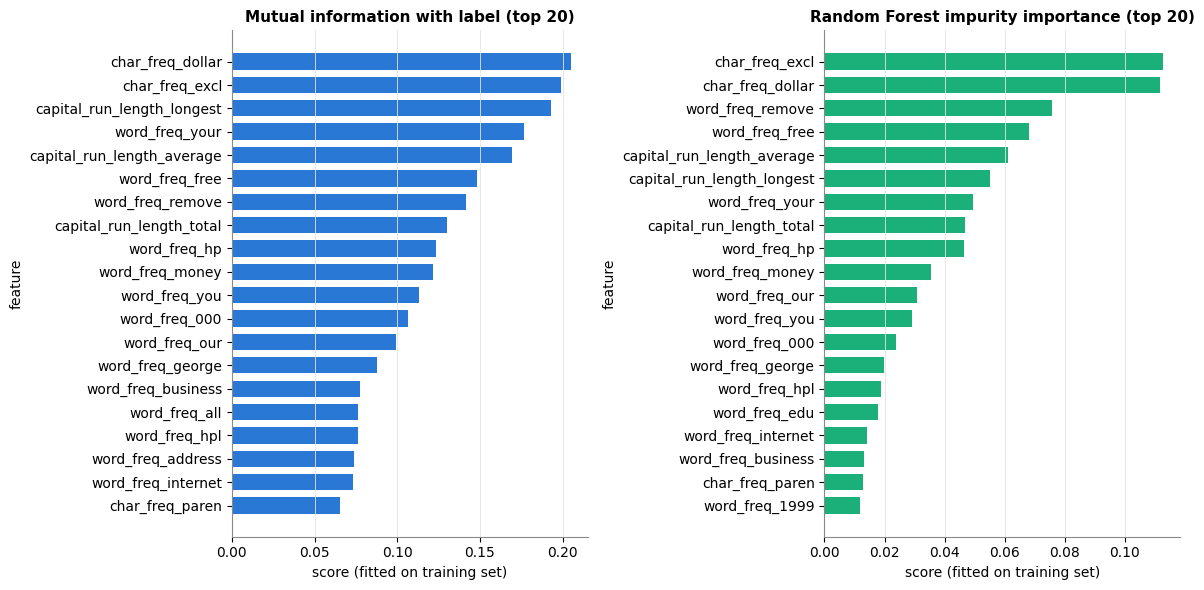

In [10]:
mi_vals = pd.Series(mi_score(X_train, y_train), index=X_train.columns).sort_values(ascending=False)
rf_imp = pd.Series(RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=N_JOBS)
                   .fit(X_train, y_train).feature_importances_, index=X_train.columns).sort_values(ascending=False)
t2_scores = save_table(pd.DataFrame({"feature": X_train.columns, "mutual_information": mi_vals[X_train.columns].values,
                                     "rf_importance": rf_imp[X_train.columns].values}), "t2_feature_scores")
display(t2_scores.sort_values("rf_importance", ascending=False).head(20).round(4).reset_index(drop=True))
cap_top = [f for f in mi_vals.index[:5] if f.startswith("capital")]
print("MI top 5:", list(mi_vals.index[:5]))
print("correlation (training set) of the capital-run features in the MI top 5:", X_train[cap_top].corr().round(3).values[0, 1])
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, s, title, c in [(axes[0], mi_vals, "Mutual information with label (top 20)", PALETTE[0]),
                        (axes[1], rf_imp, "Random Forest impurity importance (top 20)", PALETTE[2])]:
    top = s.head(20)[::-1]
    ax.barh(top.index, top.values, color=c, height=0.7)
    ax.set(title=title, xlabel="score (fitted on training set)", ylabel="feature")
    ax.grid(axis="y", visible=False)
fig.tight_layout(); save_fig(fig, "t2_feature_scores"); plt.show()

**Interpretation (Figure `t2_feature_scores`, Table `t2_feature_scores`).** Both scores, computed on the training set only, put the same features at the top: `char_freq_$`, `char_freq_!`, the capital-run-length features, *your, free, remove, hp, money*. Ten of the top-10 features are the same in both rankings, only in a different order. Both scores fall off steeply. Beyond the 20th feature, MI is at most 0.059 nats (vs 0.20 for the top feature) and RF importance at most 1.1% (vs 7.6% for *remove*, which is only 3rd). Many word features carry nearly no information: *3d, table, parts* are zero in 99%, 99% and 98% of all 4,601 e-mails (printed in Section 0), and *parts* has MI 0.0002. This explains why about 20 features suffice. The scores differ in kind: MI is univariate and model-free, while RF importance is multivariate and also credits features that only help in interaction with others.

### 2.4 Why performance improved, declined or stayed similar
* **Small k (5–10): performance declined.** Removing informative features under-fits. The tree cannot separate spam that lacks the few top words. MI suffers most because it scores each feature on its own. Its top 5 contains two correlated capital-run-length statistics (r = 0.48, printed above Figure `t2_feature_scores`) but not *remove* and *free*, which RF importance ranks 3rd and 4th because they work well together with the other features. Its top-5 therefore holds less complementary information.
* **Medium k (15–40): performance stayed similar or improved slightly.** The 20–40 weakest features are mostly zeros. A fully grown decision tree uses them deep in the tree to split tiny groups of training e-mails, which adds variance without adding generalisable signal. Removing them acts as mild regularisation, which gives the small CV gains (+0.004 to +0.005) and the +0.5/+1.2-point test gains of RFE and RF importance. The gain is small because a decision tree already performs *implicit* feature selection: it only splits on features that reduce impurity.
* **Method differences.** The RF-importance selector worked best because its ranking comes from 200 trees on bootstrap samples, so it is stable and accounts for interactions. RFE uses a single tree's importances, which are noisier, and it picked k=40. MI is cheapest but ignores interactions and redundancy, and it ended up level with the baseline on the test set.
* **k=57** reproduces the baseline exactly (sanity check). **Practical conclusion:** about 20 of 57 features give the same or slightly better accuracy with a smaller, faster and more interpretable model.

---
# Task 3 — Feature Extraction with PCA (Spambase)
### 3.1–3.2 Explained variance (StandardScaler → PCA, fitted on the training set only)

components for 90% variance: 43 | for 95%: 48 | PC1 alone: 0.118


,n_components,cumulative_explained_variance
0,2,0.1756
1,5,0.2660
2,10,0.3869
3,20,0.5768
4,30,0.7391
5,43,0.9068
6,48,0.9549
7,57,1.0000


component,PC1,PC2,PC3
rank,,,
1,word_freq_857,word_freq_your,capital_run_length_longest
2,word_freq_415,word_freq_000,capital_run_length_total
3,word_freq_direct,capital_run_length_longest,char_freq_paren
4,word_freq_technology,char_freq_dollar,capital_run_length_average
5,word_freq_telnet,word_freq_order,word_freq_you
6,word_freq_labs,capital_run_length_total,char_freq_semicolon
7,word_freq_650,word_freq_receive,word_freq_1999
8,word_freq_85,word_freq_addresses,word_freq_your


component,PC1,PC2,PC3
rank,,,
1,0.350,0.285,0.467
2,0.350,0.243,0.379
3,0.324,0.242,0.325
4,0.317,0.232,0.296
5,0.312,0.232,-0.241
6,0.311,0.226,0.210
7,0.275,0.221,0.199
8,0.263,0.216,-0.197


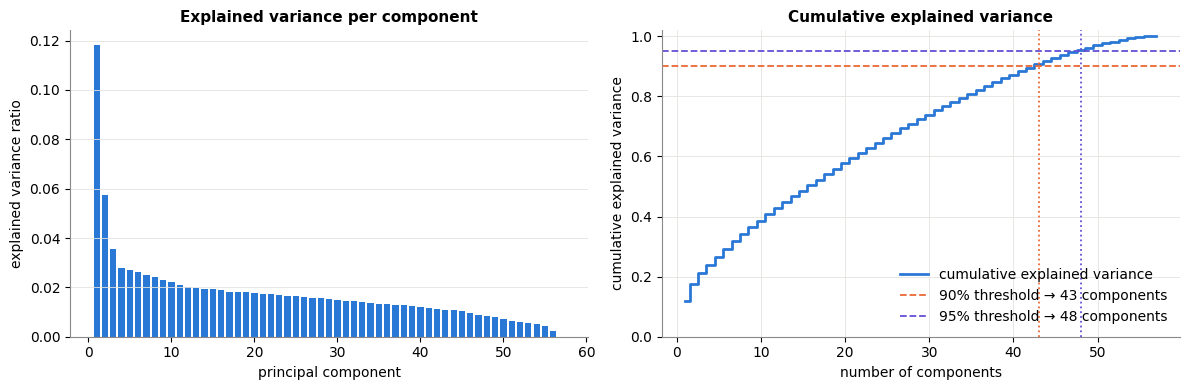

In [11]:
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

pca_fit = Pipeline([("sc", StandardScaler()), ("pca", PCA(random_state=SEED))]).fit(X_train)   # training rows only
evr = pca_fit.named_steps["pca"].explained_variance_ratio_
cum = np.cumsum(evr)
n90, n95 = int(np.argmax(cum >= 0.90) + 1), int(np.argmax(cum >= 0.95) + 1)
print(f"components for 90% variance: {n90} | for 95%: {n95} | PC1 alone: {evr[0]:.3f}")
N_GRID = sorted({2, 5, 10, 20, 30, n90, n95, 57})
t3_var = save_table(pd.DataFrame({"n_components": N_GRID, "cumulative_explained_variance": [cum[n - 1] for n in N_GRID]}),
                    "t3_cumulative_variance")
display(t3_var.round(4))
KEY["T3 components for 90% variance"] = n90; KEY["T3 components for 95% variance"] = n95
load = pd.DataFrame(pca_fit.named_steps["pca"].components_[:3].T, index=X_train.columns, columns=["PC1", "PC2", "PC3"])
rows = []
for pc in load:
    top = load[pc].reindex(load[pc].abs().sort_values(ascending=False).index)[:8]
    rows += [{"component": pc, "rank": r + 1, "feature": f, "loading": v} for r, (f, v) in enumerate(top.items())]
t3_load = save_table(pd.DataFrame(rows), "t3_pca_loadings")
display(t3_load.pivot(index="rank", columns="component", values="feature"))
display(t3_load.pivot(index="rank", columns="component", values="loading").round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
comp = np.arange(1, len(evr) + 1)
axes[0].bar(comp, evr, color=PALETTE[0], width=0.75)
axes[0].set(xlabel="principal component", ylabel="explained variance ratio", title="Explained variance per component")
axes[0].grid(axis="x", visible=False)
axes[1].step(comp, cum, where="mid", color=PALETTE[0], label="cumulative explained variance")
for thr, n, c in [(0.90, n90, PALETTE[1]), (0.95, n95, PALETTE[6])]:
    axes[1].axhline(thr, ls="--", lw=1.3, color=c, label=f"{thr:.0%} threshold → {n} components")
    axes[1].axvline(n, ls=":", lw=1.3, color=c)
axes[1].set(xlabel="number of components", ylabel="cumulative explained variance", ylim=(0, 1.02),
            title="Cumulative explained variance")
axes[1].legend(loc="lower right")
fig.tight_layout(); save_fig(fig, "t3_explained_variance"); plt.show()

**Interpretation (Figure `t3_explained_variance`, Tables `t3_cumulative_variance`, `t3_pca_loadings`).** After standardisation the variance is spread very evenly. PC1 explains only 11.8%, two components 17.6%, ten components 38.7% and thirty 73.9%. Reaching **90% needs 43 components and 95% needs 48** of 57. The per-component bars decay slowly, with no sharp "elbow". This means the Spambase features are mostly weakly correlated (each word frequency is its own sparse signal), so PCA cannot compress them much: a variance-preserving reduction removes only 9–14 dimensions. The few correlated groups are what PCA merges into the first components. PC1's largest loadings (0.26–0.35, Table `t3_pca_loadings`) are *857, 415, direct, technology, telnet, labs, 650, 85*: words that co-occur in HP-internal e-mails (phone numbers, addresses, lab names). PC2 collects spam vocabulary (*your, 000, $, order, receive*, long capital runs). PC3 is dominated by the capital-run-length statistics.

### 3.3 Three set-ups with the same classifier
Classifier for all three: **Logistic Regression** (`LogisticRegression(max_iter=5000, random_state=42)`, L2, C=1). We chose it because PCA is a linear transform and logistic regression is a linear model that needs standardised inputs, so the effect of the representation shows up directly. (Decision trees are scale-invariant and are already used in Tasks 1, 2 and 5; a Decision Tree check is added as an extra below.)
* (a) original features: `StandardScaler → LR`
* (b) PCA: `StandardScaler → PCA(n) → LR`, n chosen by 5-fold CV from {2, 5, 10, 20, 30, n90, n95, 57}
* (c) feature selection then PCA: `SelectKBest(MI, k) → StandardScaler → PCA(n) → LR`, (k, n) chosen by CV from k ∈ {20, 30, 40} and **every n of the (b) grid with n ≤ k, plus n = k** (n ∈ {2, 5, 10, 20, 30, 40}), so (c) has the same component choices as (b) up to its input size; n = k means selection without compression. The MI scorer is reused from Task 2.

In [12]:
def lr():
    return LogisticRegression(max_iter=5000, random_state=SEED)

pipe_a = Pipeline([("sc", StandardScaler()), ("clf", lr())])
cv_a = cross_val_score(pipe_a, X_train, y_train, cv=skf(5), scoring="accuracy", n_jobs=N_JOBS)
pipe_a.fit(X_train, y_train)
gs_b = GridSearchCV(Pipeline([("sc", StandardScaler()), ("pca", PCA(random_state=SEED)), ("clf", lr())]),
                    {"pca__n_components": N_GRID}, cv=skf(5), scoring="accuracy", n_jobs=N_JOBS).fit(X_train, y_train)
gs_c = GridSearchCV(Pipeline([("fs", SelectKBest(mi_score)), ("sc", StandardScaler()), ("pca", PCA(random_state=SEED)), ("clf", lr())]),
                    [{"fs__k": [k], "pca__n_components": sorted({n for n in N_GRID if n <= k} | {k})} for k in [20, 30, 40]],
                    cv=skf(5), scoring="accuracy", n_jobs=N_JOBS).fit(X_train, y_train)
# extra: same comparison (a) vs (b) with the Task 1 Decision Tree
cv_dt_a = cross_val_score(dt(), X_train, y_train, cv=skf(5), n_jobs=N_JOBS)
gs_dt_b = GridSearchCV(Pipeline([("sc", StandardScaler()), ("pca", PCA(random_state=SEED)), ("clf", dt())]),
                       {"pca__n_components": N_GRID}, cv=skf(5), scoring="accuracy", n_jobs=N_JOBS).fit(X_train, y_train)

nb_, kc, nc = gs_b.best_params_["pca__n_components"], gs_c.best_params_["fs__k"], gs_c.best_params_["pca__n_components"]
rows = [
    {"setup": "(a) original features", "classifier": "LogReg", "inputs": 57, "dims_to_classifier": 57,
     "cv_mean_acc": cv_a.mean(), "cv_std_acc": cv_a.std(ddof=1), **clf_metrics(y_test, pipe_a.predict(X_test))},
    {"setup": "(b) PCA", "classifier": "LogReg", "inputs": 57, "dims_to_classifier": nb_,
     "cv_mean_acc": gs_b.best_score_, "cv_std_acc": gs_b.cv_results_["std_test_score"][gs_b.best_index_], **clf_metrics(y_test, gs_b.predict(X_test))},
    {"setup": f"(b') PCA, 95% variance rule (n={n95})", "classifier": "LogReg", "inputs": 57, "dims_to_classifier": n95,
     "cv_mean_acc": gs_b.cv_results_["mean_test_score"][N_GRID.index(n95)], "cv_std_acc": gs_b.cv_results_["std_test_score"][N_GRID.index(n95)],
     **clf_metrics(y_test, clone(gs_b.best_estimator_).set_params(pca__n_components=n95).fit(X_train, y_train).predict(X_test))},
    {"setup": "(c) MI selection → PCA", "classifier": "LogReg", "inputs": kc, "dims_to_classifier": nc,
     "cv_mean_acc": gs_c.best_score_, "cv_std_acc": gs_c.cv_results_["std_test_score"][gs_c.best_index_], **clf_metrics(y_test, gs_c.predict(X_test))},
    {"setup": "extra: (a) original features", "classifier": "DecisionTree (Task 1)", "inputs": 57, "dims_to_classifier": 57,
     "cv_mean_acc": cv_dt_a.mean(), "cv_std_acc": cv_dt_a.std(ddof=1), **clf_metrics(y_test, dt_base.predict(X_test))},
    {"setup": "extra: (b) PCA", "classifier": "DecisionTree (Task 1)", "inputs": 57, "dims_to_classifier": gs_dt_b.best_params_["pca__n_components"],
     "cv_mean_acc": gs_dt_b.best_score_, "cv_std_acc": gs_dt_b.cv_results_["std_test_score"][gs_dt_b.best_index_], **clf_metrics(y_test, gs_dt_b.predict(X_test))},
]
t3_cmp = save_table(pd.DataFrame(rows), "t3_setup_comparison")
display(t3_cmp.round(4))
for _, r in t3_cmp.iterrows():
    KEY[f"T3 {r.setup} [{r.classifier}] test accuracy"] = r.accuracy

t3_ncurve = save_table(pd.DataFrame({"n_components": N_GRID, "cumulative_variance": [cum[n - 1] for n in N_GRID],
                                     "cv_mean_acc_logreg": gs_b.cv_results_["mean_test_score"],
                                     "cv_std_acc_logreg": gs_b.cv_results_["std_test_score"],
                                     "cv_mean_acc_dtree": gs_dt_b.cv_results_["mean_test_score"]}), "t3_cv_accuracy_vs_components")
display(t3_ncurve.round(4))
t3_c = save_table(pd.DataFrame(gs_c.cv_results_)[["param_fs__k", "param_pca__n_components", "mean_test_score", "std_test_score"]]
                  .rename(columns={"param_fs__k": "k", "param_pca__n_components": "n_components"}), "t3_fs_pca_grid")
display(t3_c.round(4))

,setup,classifier,inputs,dims_to_classifier,cv_mean_acc,cv_std_acc,accuracy,precision,recall,f1
0,(a) original features,LogReg,57,57,0.9228,0.0121,0.9294,0.9209,0.8981,0.9093
1,(b) PCA,LogReg,57,57,0.9231,0.0112,0.9294,0.9209,0.8981,0.9093
2,"(b') PCA, 95% variance rule (n=48)",LogReg,57,48,0.9220,0.0072,0.9273,0.9205,0.8926,0.9063
3,(c) MI selection → PCA,LogReg,40,40,0.9155,0.0075,0.9262,0.9226,0.8871,0.9045
4,extra: (a) original features,DecisionTree (Task 1),57,57,0.9136,0.0109,0.9110,0.8828,0.8926,0.8877
5,extra: (b) PCA,DecisionTree (Task 1),57,30,0.8921,0.0156,0.8817,0.8508,0.8485,0.8497


,n_components,cumulative_variance,cv_mean_acc_logreg,cv_std_acc_logreg,cv_mean_acc_dtree
0,2,0.1756,0.8707,0.0105,0.8427
1,5,0.2660,0.8753,0.0090,0.8848
2,10,0.3869,0.9022,0.0089,0.8804
3,20,0.5768,0.9057,0.0063,0.8859
4,30,0.7391,0.9090,0.0103,0.8921
5,43,0.9068,0.9171,0.0052,0.8821
6,48,0.9549,0.9220,0.0072,0.8851
7,57,1.0000,0.9231,0.0112,0.8837


,k,n_components,mean_test_score,std_test_score
0,20,2,0.8562,0.0091
1,20,5,0.8696,0.0069
2,20,10,0.8834,0.0129
3,20,20,0.8957,0.0106
4,30,2,0.8658,0.0120
5,30,5,0.8769,0.0138
6,30,10,0.8870,0.0082
7,30,20,0.8940,0.0093
8,30,30,0.9098,0.0115
9,40,2,0.8739,0.0111


**Interpretation (Tables `t3_setup_comparison`, `t3_cv_accuracy_vs_components`, `t3_fs_pca_grid`).**
* **(a) Original features.** Logistic regression reaches CV 0.9228 and test accuracy 0.9294 (F1 0.9093). It is the best of the three set-ups.
* **(b) PCA.** CV picks **n = 57, i.e. no reduction**, with CV 0.9231. The test result is *identical* to (a). This is expected: with all components PCA is only an orthogonal rotation of the standardised data, and L2-regularised logistic regression is rotation-invariant (‖w‖² does not change under rotation), so the predictions are the same. With the 95%-variance rule (n = 48, fixed from training variance alone) accuracy drops slightly to CV 0.9220 and test 0.9273. With 20 components it is 0.906, and with 2 it is 0.871.
* **(c) MI selection → PCA.** With the same component choices as (b) up to its input size (all n ≤ k, plus n = k), CV picks **k = 40 features → 40 components**, i.e. selection *without* any compression (CV 0.9155, test 0.9262). Like (b), CV avoids compressing: along every row of `t3_fs_pca_grid` accuracy rises with n, and every compressed (c) setting is worse (best compressed: 40 → 30 components, CV 0.9114). The chosen (c) model is effectively MI selection of 40 features plus logistic regression, and it is 0.3 points below (a) on the test set: dropping 17 features costs a little, and compressing on top of that costs more.
* **Extra: Decision Tree.** PCA hurts the tree far more: CV 0.9136 → 0.8921 and test 0.9110 → 0.8817 (best n = 30). Trees split one axis at a time. On the original sparse word frequencies a split like "*free* > 0" is very informative. After PCA every component mixes all 57 words, so such clean axis-aligned rules disappear.

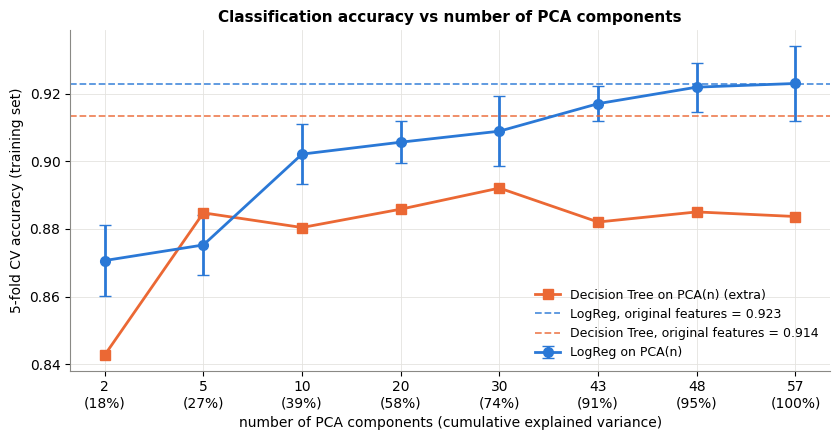

In [13]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.errorbar(range(len(N_GRID)), t3_ncurve.cv_mean_acc_logreg, yerr=t3_ncurve.cv_std_acc_logreg, marker="o", ms=7,
            capsize=4, color=PALETTE[0], label="LogReg on PCA(n)")
ax.plot(range(len(N_GRID)), t3_ncurve.cv_mean_acc_dtree, marker="s", ms=7, color=PALETTE[1], label="Decision Tree on PCA(n) (extra)")
ax.axhline(cv_a.mean(), ls="--", color=PALETTE[0], lw=1.3, alpha=0.8, label=f"LogReg, original features = {cv_a.mean():.3f}")
ax.axhline(cv_dt_a.mean(), ls="--", color=PALETTE[1], lw=1.3, alpha=0.8, label=f"Decision Tree, original features = {cv_dt_a.mean():.3f}")
ax.set_xticks(range(len(N_GRID)), [f"{n}\n({cum[n-1]:.0%})" for n in N_GRID])
ax.set(xlabel="number of PCA components (cumulative explained variance)", ylabel="5-fold CV accuracy (training set)",
       title="Classification accuracy vs number of PCA components")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout(); save_fig(fig, "t3_accuracy_vs_components"); plt.show()

**Interpretation (Figure `t3_accuracy_vs_components`).** For logistic regression, accuracy rises almost monotonically with the number of components. It climbs quickly up to 10 components (0.902), then slowly, and reaches the original-feature line only at 48–57 components. No PCA size *beats* the original features, so dimensionality reduction buys compactness, not accuracy. The Decision Tree (orange) behaves differently. It is already at 0.885 with 5 components, peaks at 30 (0.892) and gets *worse* again with 43–57 components even though those keep more variance. It stays at least 2 points below the tree on the original features at every n (7 points at n = 2). The x-axis labels show the cumulative variance: 74% variance (30 PCs) is the tree's best point, while 100% variance is not.

### 3.4 Does retaining high variance guarantee better classification?
Direct test: train the same LR on *disjoint blocks* of principal components. If variance were the same thing as class information, the top-variance block would dominate and the low-variance blocks would be useless.

In [14]:
def pc_block(lo, hi):
    return FunctionTransformer(lambda Z, lo=lo, hi=hi: Z[:, lo:hi])

rows = []
for label, (lo, hi) in {"PC1–10 (highest variance)": (0, 10), "PC11–20": (10, 20),
                        "PC21–30": (20, 30), "PC31–57 (lowest variance)": (30, 57)}.items():
    pipe = Pipeline([("sc", StandardScaler()), ("pca", PCA(random_state=SEED)), ("blk", pc_block(lo, hi)), ("clf", lr())])
    s = cross_val_score(pipe, X_train, y_train, cv=skf(5), n_jobs=N_JOBS)
    rows.append({"component_block": label, "n_components": hi - lo, "variance_share": evr[lo:hi].sum(),
                 "cv_mean_acc": s.mean(), "cv_std_acc": s.std(ddof=1)})
t3_blocks = save_table(pd.DataFrame(rows), "t3_variance_vs_accuracy_blocks")
display(t3_blocks.round(4))

,component_block,n_components,variance_share,cv_mean_acc,cv_std_acc
0,PC1–10 (highest variance),10,0.3869,0.9022,0.0099
1,PC11–20,10,0.1900,0.6193,0.0115
2,PC21–30,10,0.1623,0.6103,0.0095
3,PC31–57 (lowest variance),27,0.2609,0.6288,0.0104


**Interpretation (Table `t3_variance_vs_accuracy_blocks`) and discussion.**
* The top-variance block PC1–10 (38.7% of variance) alone gives 0.902 CV accuracy, so in Spambase the leading directions do carry most of the class signal. The groups of co-occurring spam/ham words create both high variance and class separation.
* The *non-monotone* part is telling. PC31–57 hold **more** variance (26.1%) than PC11–20 (19.0%), partly because the block is larger (27 components vs 10), and give slightly **higher** accuracy (0.629 vs 0.619). Yet every block after the first is barely above the 0.606 majority-class baseline. Variance share and usefulness are not proportional.
* Adding the last 14 components (only 9% of the variance, 43 → 57 PCs) still raises LR accuracy from 0.917 to 0.923. Low-variance directions can contain discriminative information. PCA discards it because PCA is **unsupervised**: it ranks directions by spread, never by how well they separate spam from ham.
* For the decision tree, keeping more variance made accuracy *worse* (peak at 74% variance), and every PCA representation was worse than no PCA.

**Conclusion.** Retaining high variance does **not** guarantee better classification. On this dataset PCA reduced the dimension from 57 to 43–48 at the cost of 0.1–0.6 points for a linear model and about 3 points for a tree. It did not improve any classifier. Supervised feature selection (Task 2) was the better way to reduce dimensions here, because it keeps original, interpretable features chosen for their relation to the label.

---
# Task 4 — K-Means Clustering (Wholesale Customers)
Only the six annual-spending features are used. `Channel` and `Region` are dropped before any fitting; `Channel` is looked at only once, **after** clustering, as a post-hoc sanity check.
Clustering is unsupervised and there is no test set here, so fitting the scaler/PCA on all 440 rows is not leakage.

,feature,count,mean,std,min,25%,50%,75%,max,skew,skew_after_log1p
0,Fresh,440.0,12000.30,12647.33,3.0,3127.75,8504.0,16933.75,112151.0,2.56,-1.58
1,Milk,440.0,5796.27,7380.38,55.0,1533.00,3627.0,7190.25,73498.0,4.05,-0.22
2,Grocery,440.0,7951.28,9503.16,3.0,2153.00,4755.5,10655.75,92780.0,3.59,-0.67
3,Frozen,440.0,3071.93,4854.67,25.0,742.25,1526.0,3554.25,60869.0,5.91,-0.35
4,Detergents_Paper,440.0,2881.49,4767.85,3.0,256.75,816.5,3922.00,40827.0,3.63,-0.24
5,Delicassen,440.0,1524.87,2820.11,3.0,408.25,965.5,1820.25,47943.0,11.15,-1.09


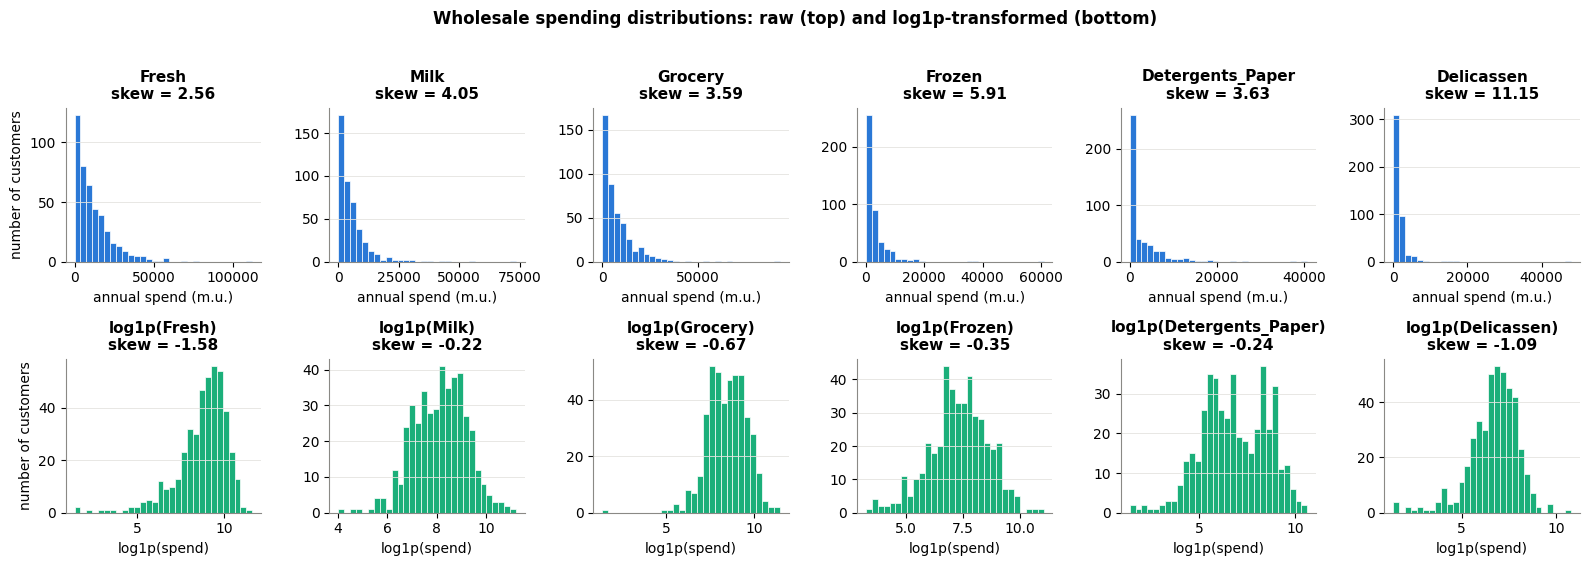

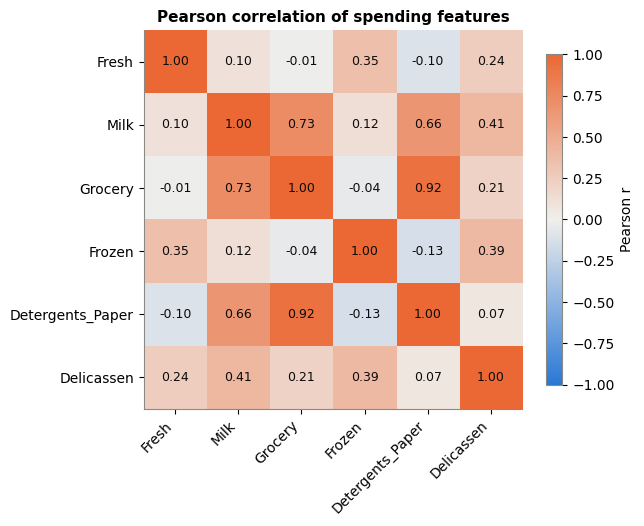

In [15]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

W = load_wholesale()
Xw = W[SPEND].copy()            # Channel and Region are NOT part of Xw
desc = Xw.describe().T
desc["skew"] = Xw.skew()
desc["skew_after_log1p"] = np.log1p(Xw).skew()
t4_desc = save_table(desc.reset_index().rename(columns={"index": "feature"}), "t4_summary_statistics")
display(t4_desc.round(2))

fig, axes = plt.subplots(2, 6, figsize=(16, 5.5))
for j, f in enumerate(SPEND):
    axes[0, j].hist(Xw[f], bins=30, color=PALETTE[0], edgecolor="white", linewidth=0.5)
    axes[0, j].set(title=f"{f}\nskew = {Xw[f].skew():.2f}", xlabel="annual spend (m.u.)")
    axes[1, j].hist(np.log1p(Xw[f]), bins=30, color=PALETTE[2], edgecolor="white", linewidth=0.5)
    axes[1, j].set(title=f"log1p({f})\nskew = {np.log1p(Xw[f]).skew():.2f}", xlabel="log1p(spend)")
    for i in range(2):
        axes[i, j].grid(axis="x", visible=False)
axes[0, 0].set_ylabel("number of customers"); axes[1, 0].set_ylabel("number of customers")
fig.suptitle("Wholesale spending distributions: raw (top) and log1p-transformed (bottom)", fontweight="bold", y=1.02)
fig.tight_layout(); save_fig(fig, "t4_distributions"); plt.show()

corr = Xw.corr()
save_table(corr.reset_index().rename(columns={"index": "feature"}), "t4_correlation")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(6), SPEND, rotation=45, ha="right"); ax.set_yticks(range(6), SPEND)
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9, color="#0b0b0b")
ax.grid(False); ax.set_title("Pearson correlation of spending features")
fig.colorbar(im, ax=ax, label="Pearson r", shrink=0.8)
fig.tight_layout(); save_fig(fig, "t4_correlation"); plt.show()

**Interpretation (Tables `t4_summary_statistics`, `t4_correlation`, Figures `t4_distributions`, `t4_correlation`).**
* All six spending features are strongly **right-skewed**: skew is 2.6 for Fresh, 3.6–4.1 for Milk, Grocery and Detergents_Paper, 5.9 for Frozen and 11.2 for Delicassen. Means are far above medians (Fresh 12,000 vs 8,504; Delicassen 1,525 vs 966). A handful of customers spend 10–50× the median (maximum Delicassen 47,943, about 16.5 std above the mean).
* The scales differ widely: the std of Fresh (12,647) is 4.5× that of Delicassen. Fresh alone carries 44.6% of the total raw variance (Table `t4_raw_variance_share`).
* `log1p` makes the distributions roughly symmetric (|skew| 0.2–0.7 for four features). It over-corrects Fresh (−1.6) and Delicassen (−1.1) into a left tail, because a few customers spend almost nothing (minimum 3).
* Correlations: **Grocery–Detergents_Paper r = 0.92**, Milk–Grocery 0.73 and Milk–Detergents_Paper 0.66 form a "retail basket" block. Fresh and Frozen are nearly independent of it. For K-Means this means the retail block is counted almost three times in the Euclidean distance, while the outliers dominate the squared distances.

### 4.1 K-Means (k=3) on raw vs standardized vs log1p-standardized features
Silhouette is reported both in each variant's own feature space and, for a common yardstick, in the standardized 6-feature space. ARI compares each partition with the standardized one.

In [16]:
def km(k):
    return KMeans(n_clusters=k, n_init=10, random_state=SEED)

Z_std = StandardScaler().fit_transform(Xw)
Z_log = StandardScaler().fit_transform(np.log1p(Xw))
spaces = {"raw": Xw.values.astype(float), "standardized": Z_std, "log1p + standardized (extra)": Z_log}
lab3 = {n: km(3).fit_predict(Z) for n, Z in spaces.items()}
rows = []
for n, Z in spaces.items():
    sizes = np.bincount(lab3[n])
    rows.append({"features": n, "cluster_sizes": "/".join(map(str, sorted(sizes, reverse=True))),
                 "silhouette_own_space": silhouette_score(Z, lab3[n]),
                 "silhouette_in_standardized_space": silhouette_score(Z_std, lab3[n]),
                 "ARI_vs_standardized": adjusted_rand_score(lab3["standardized"], lab3[n])})
t4_k3 = save_table(pd.DataFrame(rows), "t4_k3_raw_vs_scaled")
display(t4_k3.round(3))
var_share = save_table(pd.DataFrame({"feature": SPEND, "raw_variance_share": (Xw.var() / Xw.var().sum()).values}), "t4_raw_variance_share")
display(var_share.round(3))
raw_cent = pd.DataFrame(km(3).fit(spaces["raw"]).cluster_centers_, columns=SPEND).round(0)
print("raw-feature centroids (k=3):"); display(raw_cent)

,features,cluster_sizes,silhouette_own_space,silhouette_in_standardized_space,ARI_vs_standardized
0,raw,330/60/50,0.478,0.411,0.494
1,standardized,393/45/2,0.548,0.548,1.000
2,log1p + standardized (extra),213/147/80,0.259,0.142,0.084


,feature,raw_variance_share
0,Fresh,0.446
1,Milk,0.152
2,Grocery,0.252
3,Frozen,0.066
4,Detergents_Paper,0.063
5,Delicassen,0.022


raw-feature centroids (k=3):


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,8253.0,3825.0,5280.0,2573.0,1773.0,1137.0
1,35941.0,6044.0,6289.0,6714.0,1040.0,3049.0
2,8000.0,18511.0,27574.0,1997.0,12407.0,2252.0


**Interpretation (Tables `t4_k3_raw_vs_scaled`, `t4_raw_variance_share`, raw centroids).**
* **Raw features** (330/60/50). K-Means minimises squared Euclidean distance, so it is driven by the features with the largest numbers. The raw centroids differ mostly in Fresh (8,253 / 35,941 / 8,000) and Grocery (5,280 / 6,289 / 27,574): one "big-Fresh" cluster and one "big-Grocery" cluster. Delicassen, Frozen and Detergents_Paper barely matter.
* **Standardized features** (393/45/2). Every feature gets equal weight. The partition changes substantially (ARI vs raw = 0.49). It becomes 393 typical customers, 45 heavy Milk/Grocery/Detergents buyers, and a *2-customer* cluster of the most extreme spenders (huge Fresh, Frozen and Delicassen). With z-scores those two points are so far away that they earn a centroid of their own. The silhouettes in each partition's own space (0.478 raw, 0.548 standardized) are measured in different spaces and are not directly comparable; in the same standardized space the raw partition scores 0.411 and the standardized one 0.548.
* **log1p + standardized (extra).** This gives balanced clusters (213/147/80) but a much lower silhouette (0.259) and an almost unrelated partition (ARI 0.08). The log removes the outliers' leverage, but after that the data form one continuous cloud without well-separated groups.
* **Conclusion:** the clustering depends strongly on the representation. Scaling is necessary to stop Fresh and Grocery, the largest-scale features, from dominating, and log1p changes the result completely.

### 4.2 K-Means for k = 2…10 on the standardized features (n_init=10)
The log1p-standardized silhouette is plotted as an extra experiment.

,k,inertia,silhouette,smallest_cluster,largest_cluster,inertia_log1p_extra,silhouette_log1p_extra,inertia_drop_pct
0,2,1956.124,0.547,51,389,1844.064,0.290,NaN
1,3,1608.431,0.548,2,393,1553.421,0.259,17.8
2,4,1317.838,0.348,5,315,1386.863,0.188,18.1
3,5,1058.771,0.369,1,270,1266.149,0.192,19.7
4,6,915.741,0.378,1,280,1174.759,0.201,13.5
5,7,825.400,0.334,1,258,1086.359,0.196,9.9
6,8,737.386,0.320,1,219,1028.486,0.185,10.7
7,9,661.450,0.309,1,198,973.141,0.197,10.3
8,10,605.915,0.311,1,184,931.998,0.191,8.4


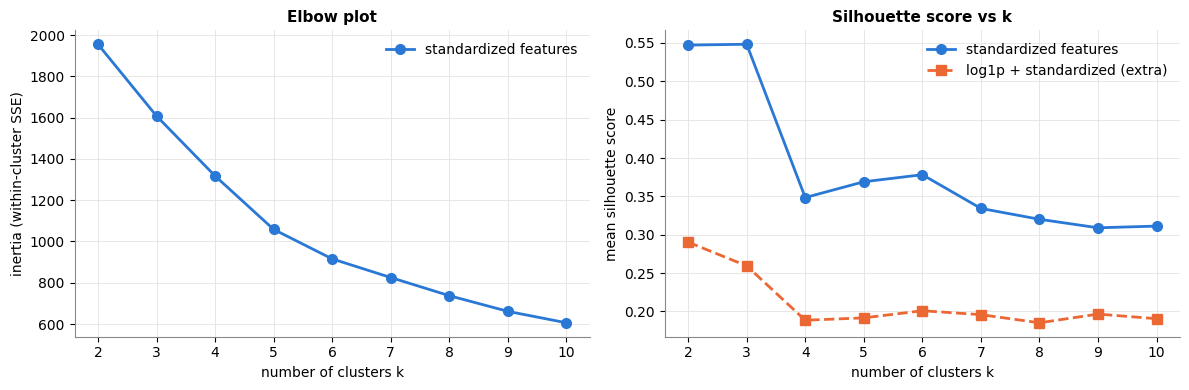

In [17]:
rows = []
for k in range(2, 11):
    m = km(k).fit(Z_std); ml = km(k).fit(Z_log)
    sz = np.bincount(m.labels_)
    rows.append({"k": k, "inertia": m.inertia_, "silhouette": silhouette_score(Z_std, m.labels_),
                 "smallest_cluster": sz.min(), "largest_cluster": sz.max(),
                 "inertia_log1p_extra": ml.inertia_, "silhouette_log1p_extra": silhouette_score(Z_log, ml.labels_)})
t4_sweep = pd.DataFrame(rows)
t4_sweep["inertia_drop_pct"] = (-t4_sweep.inertia.pct_change() * 100).round(1)
save_table(t4_sweep, "t4_k_sweep")
display(t4_sweep.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(t4_sweep.k, t4_sweep.inertia, marker="o", ms=7, color=PALETTE[0], label="standardized features")
axes[0].set(xlabel="number of clusters k", ylabel="inertia (within-cluster SSE)", title="Elbow plot", xticks=range(2, 11))
axes[0].legend()
axes[1].plot(t4_sweep.k, t4_sweep.silhouette, marker="o", ms=7, color=PALETTE[0], label="standardized features")
axes[1].plot(t4_sweep.k, t4_sweep.silhouette_log1p_extra, marker="s", ms=7, ls="--", color=PALETTE[1], label="log1p + standardized (extra)")
axes[1].set(xlabel="number of clusters k", ylabel="mean silhouette score", title="Silhouette score vs k", xticks=range(2, 11))
axes[1].legend()
fig.tight_layout(); save_fig(fig, "t4_elbow_silhouette"); plt.show()

**Interpretation (Figure `t4_elbow_silhouette`, Table `t4_k_sweep`).**
* **Elbow.** Inertia falls smoothly: −17.8%, −18.1% and −19.7% from k=2→3→4→5, then −13.5%, −9.9%, −10.7%, −10.3% and −8.4%. There is no sharp elbow. The curve flattens after k≈5–6, which is a weak elbow at best.
* **Silhouette.** k=2 (0.547) and k=3 (0.548) are clearly the best and practically tied. The score then drops sharply to 0.348 at k=4 and stays at 0.31–0.38 for k=4…10, with a local bump at k=6 (0.378).
* **Cluster sizes.** For every k ≥ 5 the smallest cluster contains **one** customer, and at k=3 and k=4 it holds only 2 and 5. Beyond k=2, at least half of the extra clusters at each k hold under 5% of customers (at k=3 and k=4 all of them); these isolate outliers rather than find segments.
* **log1p (extra).** The silhouette is lower at every k (max 0.290 at k=2), which confirms that the log-transformed data have no strongly separated groups.

### 4.3 Choice of the final k
**Chosen k = 2.** The evidence and rule:
1. The silhouette identifies k ∈ {2, 3} as the only strong candidates (0.547 and 0.548). Every k ≥ 4 scores at most 0.378 (k=6), at least 0.169 below k=2.
2. The difference between k=2 and k=3 is **0.001**, far below anything meaningful. The deciding factor is what the third cluster is: at k=3 it contains **2 customers** (0.5% of the data). That is an outlier flag, not a customer segment, and apart from it the k=3 partition differs from k=2 only in a few retail-tail customers who move to the dense cluster. We therefore applied the rule in the next cell: take the k with silhouette within 0.01 of the best whose smallest cluster has at least 5% of the customers. Only k=2 qualifies (smallest cluster 51 = 11.6%). **Honest note:** this rule was written *after* our first draft had chosen k=3 and we saw its 2-customer cluster (see Challenges), so it is a post-hoc rule and the 5% threshold is a judgement call. To check that k=2 is not just an artefact of that rule, 4.7 removes the outlier problem directly and repeats the choice.
3. **Alternatives considered and rejected.** *k=3*: tied silhouette, but its extra cluster is two outliers (shown in the right panel of the next figure). *k=5–6*: the region where the elbow curve flattens and where silhouette has a local bump (0.378 at k=6). Rejected because silhouette is 0.17–0.18 lower and the solutions contain one-customer clusters. *log1p + scaled clustering*: balanced, but its best silhouette is only 0.29, so its groups are not well separated.

candidates within 0.01 of best silhouette:


,k,silhouette,smallest_cluster,largest_cluster
0,2,0.5472,51,389
1,3,0.5483,2,393


CHOSEN_K = 2 | alternative shown = 3


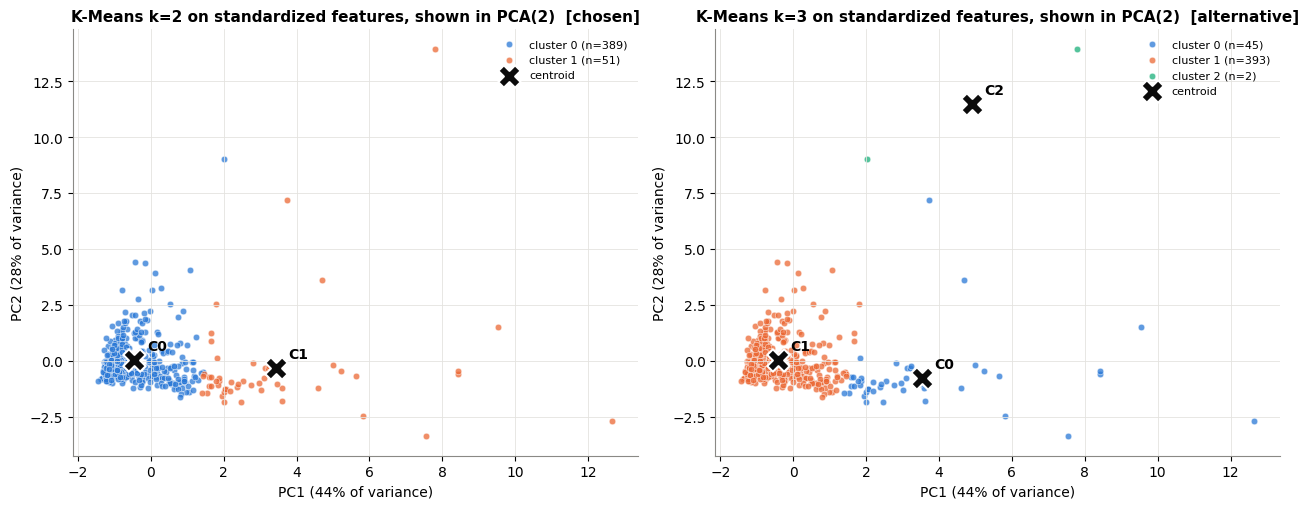

In [18]:
# Selection rule (formulated after the first draft, see 4.3 and Challenges): among k whose silhouette is within 0.01 of the best,
# keep only partitions whose smallest cluster holds >= 5% of customers (a cluster of 1-5 shops is an
# outlier flag, not a segment); pick the highest silhouette among those, ties -> smaller k.
best_sil = t4_sweep.silhouette.max()
ok = t4_sweep[(t4_sweep.silhouette >= best_sil - 0.01) & (t4_sweep.smallest_cluster >= 0.05 * len(Xw))]
CHOSEN_K = int(ok.sort_values(["silhouette", "k"], ascending=[False, True]).k.iloc[0])
ALT_K = int(t4_sweep.loc[t4_sweep.silhouette.idxmax(), "k"]) if CHOSEN_K != t4_sweep.loc[t4_sweep.silhouette.idxmax(), "k"] else 3
print("candidates within 0.01 of best silhouette:"); display(t4_sweep[t4_sweep.silhouette >= best_sil - 0.01][["k", "silhouette", "smallest_cluster", "largest_cluster"]].round(4))
print("CHOSEN_K =", CHOSEN_K, "| alternative shown =", ALT_K)
KEY["T4 chosen k"] = CHOSEN_K
KEY["T4 silhouette at chosen k (standardized)"] = t4_sweep.loc[t4_sweep.k == CHOSEN_K, "silhouette"].item()

pca2 = PCA(n_components=2, random_state=SEED).fit(Z_std)
P = pca2.transform(Z_std)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, k in zip(axes, [CHOSEN_K, ALT_K]):
    m = km(k).fit(Z_std)
    C = pca2.transform(m.cluster_centers_)
    for c in range(k):
        msk = m.labels_ == c
        ax.scatter(P[msk, 0], P[msk, 1], s=22, alpha=0.75, color=PALETTE[c], edgecolor="white", linewidth=0.4,
                   label=f"cluster {c} (n={msk.sum()})")
    ax.scatter(C[:, 0], C[:, 1], marker="X", s=260, color="#0b0b0b", edgecolor="white", linewidth=1.5, zorder=5, label="centroid")
    for c in range(k):
        ax.annotate(f"C{c}", C[c], textcoords="offset points", xytext=(9, 7), fontsize=10, fontweight="bold")
    ax.set(xlabel=f"PC1 ({pca2.explained_variance_ratio_[0]:.0%} of variance)",
           ylabel=f"PC2 ({pca2.explained_variance_ratio_[1]:.0%} of variance)",
           title=f"K-Means k={k} on standardized features, shown in PCA(2)" + ("  [chosen]" if k == CHOSEN_K else "  [alternative]"))
    ax.legend(fontsize=8, loc="upper right")
fig.tight_layout(); save_fig(fig, "t4_pca_clusters"); plt.show()

**Interpretation (Figure `t4_pca_clusters`).** PC1 (44%) and PC2 (28%) together show 72% of the standardized variance. **k=2 (left):** the two clusters are separated along PC1, which loads mainly on Milk, Grocery and Detergents_Paper. Cluster 0 (389 customers) is the dense cloud near the origin. Cluster 1 (51) is the elongated tail of heavy retail-basket buyers to the right. Its centroid (✕ C1) sits at PC1 ≈ 3.5, far from the dense cloud, while C0 sits inside it. The boundary is not a gap but a cut through a continuous tail, which is why the silhouette is only about 0.55 and not higher. **k=3 (right):** the split is *almost* the same. The two extreme points at the top (PC2 ≈ 9 and 14: very large Fresh/Frozen/Delicassen spenders) receive their own centroid C2, which lies in empty space between them; one of them came from each k=2 cluster. A few retail-tail customers move to the large cluster (389/51 becomes 393/45/2). The third cluster at k=3 is therefore an outlier group, and adding it also shifts the retail boundary slightly.

### 4.5 Clustering on (a) original, (b) selected, (c) PCA features — at the chosen k
**Selection rule for (b) (correlation-based, stated before looking at the clusters):** while some pair of features has |Pearson r| > 0.7, drop the member of the most-correlated pair that has the larger mean |r| with the other remaining features. This removes redundant information that would otherwise be counted twice in the Euclidean distance.
(c) uses PCA on the standardized features with 2 components and with the number needed for ≥ 80% variance.

In [19]:
acorr = Xw.corr().abs()
selected, dropped = list(SPEND), []
while True:
    c = acorr.loc[selected, selected].where(~np.eye(len(selected), dtype=bool))
    if c.max().max() <= 0.7:
        break
    i, j = c.stack().idxmax()
    drop = i if c[i].mean() >= c[j].mean() else j
    selected.remove(drop); dropped.append(drop)
print("dropped:", dropped, "| kept:", selected)

pca_full_w = PCA(random_state=SEED).fit(Z_std)
n80 = int(np.argmax(np.cumsum(pca_full_w.explained_variance_ratio_) >= 0.80) + 1)
variants = {"(a) original 6 features (standardized)": Z_std,
            f"(b) selected {len(selected)} features (standardized)": StandardScaler().fit_transform(Xw[selected]),
            "(c) PCA, 2 components": PCA(n_components=2, random_state=SEED).fit_transform(Z_std),
            f"(c) PCA, {n80} components (≥80% var)": PCA(n_components=n80, random_state=SEED).fit_transform(Z_std),
            "extra: log1p + standardized": Z_log}
ref = km(CHOSEN_K).fit_predict(Z_std)
rows, VAR_LABELS = [], {}
for n, Z in variants.items():
    lab = km(CHOSEN_K).fit_predict(Z); VAR_LABELS[n] = lab
    sz = np.bincount(lab, minlength=CHOSEN_K); p = sz / sz.sum()
    rows.append({"features": n, "dims": Z.shape[1], "silhouette_own_space": silhouette_score(Z, lab),
                 "silhouette_in_standardized_6D": silhouette_score(Z_std, lab),
                 "cluster_sizes": "/".join(map(str, sorted(sz, reverse=True))),
                 "balance_min_over_max": sz.min() / sz.max(),
                 "size_entropy_normalized": float(-(p * np.log(p)).sum() / np.log(CHOSEN_K)),
                 "ARI_vs_(a)": adjusted_rand_score(ref, lab)})
t4_space = save_table(pd.DataFrame(rows), "t4_feature_space_comparison")
display(t4_space.round(3))

dropped: ['Grocery'] | kept: ['Fresh', 'Milk', 'Frozen', 'Detergents_Paper', 'Delicassen']


,features,dims,silhouette_own_space,silhouette_in_standardized_6D,cluster_sizes,balance_min_over_max,size_entropy_normalized,ARI_vs_(a)
0,(a) original 6 features (standardized),6,0.547,0.547,389/51,0.131,0.517,1.000
1,(b) selected 5 features (standardized),5,0.722,0.725,424/16,0.038,0.225,0.374
2,"(c) PCA, 2 components",2,0.636,0.563,395/45,0.114,0.476,0.914
3,"(c) PCA, 3 components (≥80% var)",3,0.578,0.547,389/51,0.131,0.517,1.000
4,extra: log1p + standardized,6,0.290,0.261,252/188,0.746,0.985,0.131


**Interpretation (Table `t4_feature_space_comparison`).** The rule dropped **Grocery** (r = 0.92 with Detergents_Paper, and the larger mean |r| of that pair), which left Fresh, Milk, Frozen, Detergents_Paper and Delicassen.
* **(a) original 6 standardized features.** Sizes 389/51, silhouette 0.547, balance (min/max) 0.13, normalised size entropy 0.52.
* **(b) selected 5 features.** The silhouette jumps to 0.722 (0.725 even when measured in the 6-D space), but the partition becomes 424/16. Balance falls to 0.04 and agreement with (a) drops to ARI 0.37. Grocery is one of two near-duplicate retail features (r = 0.92 with Detergents_Paper), so removing it weakened the "retail" axis, and the outlier directions (Fresh, Frozen, Delicassen) now dominate. K-Means then splits off a 16-customer group of extreme spenders. A higher silhouette here means "outliers are far away", not "better segments", so this variant is less useful even though its score is higher.
* **(c) PCA, 2 components.** Almost the same partition as (a) (ARI 0.91, sizes 395/45). The silhouette in its own 2-D space is higher (0.636) because the dropped 28% of variance was mostly within-cluster noise. Measured in the common 6-D space it is 0.563, a little better than (a). **PCA with 3 components (≥80% variance)** gives exactly the partition of (a) (ARI 1.00). The cluster structure lives in the first PCs.
* **Extra log1p.** The most balanced result (252/188, entropy 0.98) but the weakest separation (silhouette 0.29) and a different partition (ARI 0.13).
* Silhouette values computed in *different* spaces are not directly comparable, which is why we also report every partition's silhouette in the common standardized 6-D space and its size balance.

### 4.6 Cluster profiles (unscaled per-cluster means), final model = chosen k on standardized features

,cluster,n_customers,share_%,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,total_spend
0,0,389,88.0,12157.0,4028.0,5403.0,3066.0,1668.0,1257.0,27579.0
1,1,51,12.0,10803.0,19282.0,27390.0,3117.0,12140.0,3569.0,76301.0


per-cluster medians:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
cluster,,,,,,
0,8861.0,3195.0,3823.0,1517.0,621.0,894.0
1,5550.0,14881.0,22294.0,1668.0,9959.0,1543.0


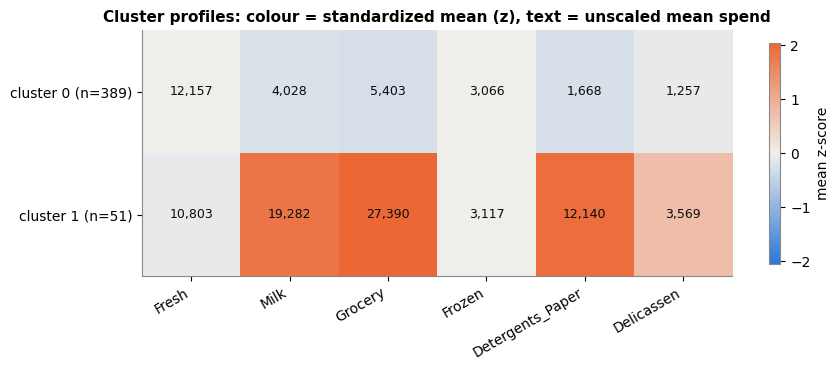

Channel (post-hoc),Horeca,Retail
cluster,,
0,293,96
1,5,46


In [20]:
final = km(CHOSEN_K).fit(Z_std)
labels = final.labels_
prof = Xw.groupby(labels).mean()
prof.insert(0, "n_customers", np.bincount(labels))
prof.insert(1, "share_%", (100 * np.bincount(labels) / len(labels)).round(1))
prof["total_spend"] = Xw.sum(axis=1).groupby(labels).mean()
prof.index.name = "cluster"
t4_prof = save_table(prof.round(0).reset_index(), "t4_cluster_profiles")
display(t4_prof)
med = Xw.groupby(labels).median(); med.index.name = "cluster"
save_table(med.reset_index(), "t4_cluster_medians"); print("per-cluster medians:"); display(med.round(0))

zmeans = pd.DataFrame(Z_std, columns=SPEND).groupby(labels).mean()
fig, ax = plt.subplots(figsize=(9, 0.9 * CHOSEN_K + 2))
lim = np.abs(zmeans.values).max()
im = ax.imshow(zmeans.values, cmap=DIV, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(6), SPEND, rotation=30, ha="right")
ax.set_yticks(range(CHOSEN_K), [f"cluster {c} (n={n})" for c, n in enumerate(np.bincount(labels))])
for i in range(CHOSEN_K):
    for j, f in enumerate(SPEND):
        ax.text(j, i, f"{prof.loc[i, f]:,.0f}", ha="center", va="center", fontsize=9, color="#0b0b0b")
ax.grid(False)
ax.set_title("Cluster profiles: colour = standardized mean (z), text = unscaled mean spend")
fig.colorbar(im, ax=ax, label="mean z-score", shrink=0.9)
fig.tight_layout(); save_fig(fig, "t4_cluster_profile_heatmap"); plt.show()

# post-hoc only: Channel was NOT used for fitting
ct = pd.crosstab(pd.Series(labels, name="cluster"), W["Channel"].map({1: "Horeca", 2: "Retail"}).rename("Channel (post-hoc)"))
save_table(ct.reset_index(), "t4_channel_crosstab_posthoc"); display(ct)

**Interpretation (Tables `t4_cluster_profiles`, `t4_cluster_medians`, `t4_channel_crosstab_posthoc`, Figure `t4_cluster_profile_heatmap`).**
* **Cluster 0: "Fresh-oriented / Horeca & small shops" (389 customers, 88%).** Average annual spend is 27,579 m.u. The largest category is Fresh (mean 12,157; median 8,861). Milk (4,028), Grocery (5,403) and especially Detergents_Paper (1,668) are low: z-scores are slightly below 0 on the retail block and around 0 on Fresh and Frozen.
* **Cluster 1: "Large retail / grocery-basket buyers" (51 customers, 12%).** Average spend is 76,301 m.u. (2.8× cluster 0). Grocery averages 27,390 (5× cluster 0), Milk 19,282 (4.8×), Detergents_Paper 12,140 (7.3×) and Delicassen 3,569 (2.8×), while Fresh and Frozen are about the same as cluster 0. The medians tell the same story (Grocery 22,294 vs 3,823), so the profile is not driven by a few outliers.
* **Post-hoc check (Channel was never used for fitting).** 46 of the 51 customers in cluster 1 (90%) are *Retail*. Cluster 0 is 75% *Horeca* (hotel/restaurant/café) but also contains 96 smaller retailers. The unsupervised clusters therefore recover a real business distinction: retailers buy packaged groceries, milk and household paper for resale, while Horeca buys mostly fresh produce. The match is not perfect: the smaller retailers in cluster 0 still buy a retail mix, but in volumes closer to the Horeca customers' than to cluster 1's.

### 4.6 (cont.) Difficulties and the effect of scaling / dimensionality reduction
* **Skew and outliers.** The difficulty is that spending is heavy-tailed. K-Means uses squared Euclidean distance and assumes compact, similarly sized, roughly spherical clusters. Here there is one dense cloud plus a long tail, so outliers pull centroids and, for k ≥ 3, get clusters of their own (2 customers at k=3, singletons for k ≥ 5).
* **Scaling changed the clusters completely.** On raw data Fresh (45% of the variance) and Grocery decided everything. After standardisation every category counts, and the main split became "retail basket vs rest" (ARI raw vs standardized only 0.49 at k=3).
* **The log transform** removed the outliers' influence and gave balanced clusters, but revealed that without the tail there is little cluster structure (best silhouette 0.29). It answers a different question: segments by *relative* spending pattern rather than by volume.
* **Dimensionality reduction.** PCA to 2–3 components kept the partition (ARI 0.91–1.00) and made it easy to visualise, while the correlation-based feature selection changed it substantially, because removing one member of a correlated block re-weights the distance.
* **No ground truth.** Silhouette rewards isolating outliers, so the "best" score is not automatically the most useful segmentation. We combined it with cluster-size balance and profile interpretability to choose k=2. k=2 should still be read as a *soft*, moderately stable split (bootstrap ARI 0.56, Section X4), even though it survives capping the outliers (4.7).

### 4.7 Robustness check: K-Means after capping the extreme spenders
Sections 4.1–4.6 show that a handful of extreme customers drive most of the difficulties. Here we treat them directly: each spending feature is **capped at its 99th percentile** (winsorising; no label, Channel or Region is used), then standardized, and the k = 2…10 sweep and the same k rule are repeated. If k=2 and the retail-vs-rest split survive, the Task 4 result does not depend on the post-hoc rule.

In [21]:
caps = Xw.quantile(0.99)                                      # per-feature 99th percentile (unsupervised)
Xcap = Xw.clip(upper=caps, axis=1)
Z_cap = StandardScaler().fit_transform(Xcap)
print("customers with at least one capped value:", int((Xw > caps).any(axis=1).sum()))
rows = []
for k in range(2, 11):
    m = km(k).fit(Z_cap); sz = np.bincount(m.labels_)
    rows.append({"k": k, "inertia": m.inertia_, "silhouette": silhouette_score(Z_cap, m.labels_),
                 "smallest_cluster": sz.min(), "largest_cluster": sz.max(),
                 "ARI_vs_chosen_partition": adjusted_rand_score(labels, m.labels_)})   # labels: final k=2 model from 4.6 (reused)
t4_cap = save_table(pd.DataFrame(rows), "t4_capped_k_sweep")
display(t4_cap.round(4))
best_cap = t4_cap.silhouette.max()
ok_cap = t4_cap[(t4_cap.silhouette >= best_cap - 0.01) & (t4_cap.smallest_cluster >= 0.05 * len(Xw))]
CAP_K = int(ok_cap.sort_values(["silhouette", "k"], ascending=[False, True]).k.iloc[0]) if len(ok_cap) else None
print("k chosen by the same rule after capping:", CAP_K)
if CAP_K is not None:
    lab_cap = km(CAP_K).fit_predict(Z_cap)
    cap_prof = Xw.groupby(lab_cap).mean().round(0)
    cap_prof.insert(0, "n_customers", np.bincount(lab_cap))
    cap_prof["Retail_share_posthoc"] = (W["Channel"] == 2).groupby(lab_cap).mean().round(3)   # post-hoc only
    cap_prof.index.name = "cluster"
    save_table(cap_prof.reset_index(), "t4_capped_profiles"); display(cap_prof)
KEY["T4 k chosen after 99th-percentile capping"] = CAP_K if CAP_K is not None else np.nan

customers with at least one capped value: 19


,k,inertia,silhouette,smallest_cluster,largest_cluster,ARI_vs_chosen_partition
0,2,1859.1209,0.4628,67,373,0.8037
1,3,1482.0596,0.3953,61,315,0.4434
2,4,1241.8599,0.3106,22,250,0.2125
3,5,1080.0621,0.3159,15,237,0.1924
4,6,930.4455,0.3368,14,228,0.1666
5,7,850.5090,0.2890,9,195,0.1678
6,8,776.2216,0.3097,5,195,0.1510
7,9,716.2783,0.2746,4,160,0.1210
8,10,669.5530,0.2459,4,139,0.0979


k chosen by the same rule after capping: 2


,n_customers,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Retail_share_posthoc
cluster,,,,,,,,
0,373,12352.0,3780.0,5000.0,2983.0,1484.0,1182.0,0.220
1,67,10040.0,17023.0,24381.0,3569.0,10662.0,3434.0,0.896


**Interpretation (Tables `t4_capped_k_sweep`, `t4_capped_profiles`).**
* **Capping touched 19 customers** (4%), those with at least one value above the 99th percentile.
* **After capping, k=2 wins on silhouette alone** (0.463 vs 0.395 at k=3 and ≤ 0.34 beyond), and no cluster is tiny (the smallest at k=3 has 61 customers). The size rule is no longer needed to reach k=2, so the Task 4 choice does not depend on the post-hoc rule.
* **The segmentation is the same one.** The capped k=2 partition agrees with the chosen partition (ARI 0.80) and has the same profile: 373 fresh-oriented customers and 67 retail-basket buyers with about 5× the Grocery and 7× the Detergents_Paper spend, 90% of them *Retail* in the post-hoc check. The retail group grows from 51 to 67 customers: capping shrinks the distance to the extreme spenders, so more borderline buyers join it.
* **Silhouettes are lower than in 4.2** (0.46 vs 0.55) because the extreme points no longer inflate the separation; this is the more honest measure of how well separated the two groups are.
* **Conclusion:** the outliers explain the *instability* and the *spurious k=3*, but not the main result. We keep k=2 on the standardized data as the Task 4 answer (it is what the task specifies) and report the capped version as confirmation.

---
# Task 5 — Decision Trees and Ensembles (Spambase)
Same split as Tasks 1–3. Models: Decision Tree, Random Forest, XGBoost, plus Gradient Boosting and AdaBoost (SAMME, decision stumps).
### 5.1–5.2 Hyper-parameter search with 5-fold stratified CV on the training set only

In [22]:
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import validation_curve
from xgboost import XGBClassifier

def xgb(**kw):
    return XGBClassifier(objective="binary:logistic", eval_metric="logloss", tree_method="hist",
                         random_state=SEED, n_jobs=1, **kw)

SEARCH = {
    "Decision Tree": (dt(), {"max_depth": [2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None]}),
    "Random Forest": (RandomForestClassifier(random_state=SEED, n_jobs=1),
                      {"n_estimators": [100, 300, 500], "max_depth": [5, 10, 20, None]}),
    "XGBoost": (xgb(), {"n_estimators": [100, 300, 500], "learning_rate": [0.01, 0.05, 0.1, 0.3], "max_depth": [3, 5, 7]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=SEED),
                          {"n_estimators": [100, 300], "learning_rate": [0.05, 0.1], "max_depth": [3, 5]}),
    "AdaBoost": (AdaBoostClassifier(random_state=SEED, **adaboost_kwargs()),
                 {"n_estimators": [100, 300, 500], "learning_rate": [0.5, 1.0]}),
}
t5_gs, best_rows = {}, []
for name, (est, grid) in SEARCH.items():
    t0 = time.perf_counter()
    gs = GridSearchCV(est, grid, cv=skf(5), scoring="accuracy", n_jobs=N_JOBS, return_train_score=True).fit(X_train, y_train)
    t5_gs[name] = gs
    res = pd.DataFrame(gs.cv_results_)
    pcols = [c for c in res.columns if c.startswith("param_")]
    res = res[pcols + ["mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score")
    res.columns = [c.replace("param_", "") for c in res.columns]
    save_table(res.astype({c.replace("param_", ""): str for c in pcols}), f"t5_search_{name.lower().replace(' ', '_')}")
    print(f"\n{name}: {len(res)} settings, {time.perf_counter() - t0:.1f}s — top 5 by CV accuracy")
    display(res.head(5).round(4))
    best_rows.append({"model": name, "best_params": str(gs.best_params_), "cv_mean_acc": gs.best_score_,
                      "cv_std_acc": gs.cv_results_["std_test_score"][gs.best_index_],
                      "cv_mean_train_acc": gs.cv_results_["mean_train_score"][gs.best_index_]})
t5_best = save_table(pd.DataFrame(best_rows), "t5_best_params")
display(t5_best.round(4))


Decision Tree: 11 settings, 0.8s — top 5 by CV accuracy


,max_depth,mean_train_score,mean_test_score,std_test_score,rank_test_score
7,12,0.9758,0.9226,0.0079,1
6,10,0.9677,0.9223,0.0063,2
8,15,0.9828,0.9212,0.0039,3
9,20,0.9918,0.9179,0.0044,4
5,8,0.9537,0.9158,0.0052,5



Random Forest: 12 settings, 24.1s — top 5 by CV accuracy


,max_depth,n_estimators,mean_train_score,mean_test_score,std_test_score,rank_test_score
10,None,300,0.9998,0.9527,0.0055,1
9,None,100,0.9998,0.9522,0.0051,2
11,None,500,0.9998,0.9516,0.0055,3
7,20,300,0.9957,0.9500,0.0047,4
8,20,500,0.9956,0.9492,0.0042,5



XGBoost: 36 settings, 49.7s — top 5 by CV accuracy


,learning_rate,max_depth,n_estimators,mean_train_score,mean_test_score,std_test_score,rank_test_score
25,0.10,7,300,0.9995,0.9576,0.0091,1
26,0.10,7,500,0.9995,0.9573,0.0076,2
16,0.05,7,300,0.9935,0.9571,0.0081,3
34,0.30,7,300,0.9994,0.9571,0.0066,4
33,0.30,7,100,0.9993,0.9568,0.0098,5



Gradient Boosting: 8 settings, 41.7s — top 5 by CV accuracy


,learning_rate,max_depth,n_estimators,mean_train_score,mean_test_score,std_test_score,rank_test_score
7,0.10,5,300,0.9991,0.9549,0.0071,1
3,0.05,5,300,0.9935,0.9524,0.0054,2
5,0.10,3,300,0.9885,0.9516,0.0076,3
6,0.10,5,100,0.9888,0.9486,0.0047,4
1,0.05,3,300,0.9747,0.9473,0.0048,5



AdaBoost: 6 settings, 18.3s — top 5 by CV accuracy


,learning_rate,n_estimators,mean_train_score,mean_test_score,std_test_score,rank_test_score
4,1.0,300,0.9526,0.9424,0.0055,1
5,1.0,500,0.9561,0.9418,0.0075,2
2,0.5,500,0.9481,0.9413,0.0022,3
1,0.5,300,0.9442,0.9380,0.0046,4
3,1.0,100,0.9442,0.9356,0.0053,5


,model,best_params,cv_mean_acc,cv_std_acc,cv_mean_train_acc
0,Decision Tree,{'max_depth': 12},0.9226,0.0079,0.9758
1,Random Forest,"{'max_depth': None, 'n_estimators': 300}",0.9527,0.0055,0.9998
2,XGBoost,"{'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 300}",0.9576,0.0091,0.9995
3,Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300}",0.9549,0.0071,0.9991
4,AdaBoost,"{'learning_rate': 1.0, 'n_estimators': 300}",0.9424,0.0055,0.9526


**Interpretation (Table `t5_best_params` and the `t5_search_*` tables).**
* **Decision Tree.** max_depth = 12 is best (CV 0.9226). The neighbouring searched depths 10 and 15 are within 0.002 of it (CV 0.9223 and 0.9212), while depths 2–3 under-fit (0.870, 0.886). Limiting depth beats the unrestricted tree of Task 1 (0.9136).
* **Random Forest.** Unlimited depth with 300 trees is best (CV 0.9527). The number of trees barely matters (100/300/500 all score 0.952–0.953). Depth 5 is clearly too shallow (0.928–0.930). Bagging tolerates fully grown trees because averaging removes their variance.
* **XGBoost.** learning_rate 0.1, max_depth 7, 300 trees is best (CV 0.9576, the highest of all models). The top settings are very close (0.9571–0.9576). The worst settings combine a small learning rate with few trees (lr 0.01, 100 trees: 0.915–0.930), which is under-fitting because the ensemble has not converged.
* **Gradient Boosting** (CV 0.9549, lr 0.1, depth 5, 300 trees) behaves like XGBoost. **AdaBoost** with stumps reaches 0.9424 (300 stumps, lr 1.0); 300 stumps beat 100 at both learning rates, and 500 helps only at lr 0.5.
* The `cv_mean_train_acc` column shows that RF, XGBoost and GB fit the training folds almost perfectly (0.999+) yet still validate at 0.95+. Ensembles can afford near-zero training error without the generalisation loss a single tree suffers.

### 5.2b Equal-budget check
The grids were not the same size: XGBoost 36 settings, Random Forest 12, Gradient Boosting 8, AdaBoost 6. A larger grid gives more chances of a lucky CV maximum, which could favour XGBoost. Using the CV scores already computed above (no new fits, no test data), we draw 2,000 random subsets of XGBoost's grid with each rival's budget and record XGBoost's best CV score in each.

In [23]:
rng = np.random.default_rng(SEED)
xs = t5_gs["XGBoost"].cv_results_["mean_test_score"]
rows = []
for rival in ["Random Forest", "Gradient Boosting", "AdaBoost"]:
    m = len(t5_gs[rival].cv_results_["mean_test_score"]); r = t5_gs[rival].best_score_
    best_m = np.array([xs[rng.choice(len(xs), m, replace=False)].max() for _ in range(2000)])
    rows.append({"rival": rival, "budget_settings": m, "rival_best_cv": r, "xgb_best_cv_full_grid": xs.max(),
                 "xgb_best_cv_median_at_budget": np.median(best_m), "xgb_best_cv_5th_pct_at_budget": np.percentile(best_m, 5),
                 "share_xgb_ahead_at_budget": (best_m > r).mean()})
t5_budget = save_table(pd.DataFrame(rows), "t5_budget_matched")
display(t5_budget.round(4))

,rival,budget_settings,rival_best_cv,xgb_best_cv_full_grid,xgb_best_cv_median_at_budget,xgb_best_cv_5th_pct_at_budget,share_xgb_ahead_at_budget
0,Random Forest,12,0.9527,0.9576,0.9573,0.9562,1.0000
1,Gradient Boosting,8,0.9549,0.9576,0.9571,0.9554,0.9635
2,AdaBoost,6,0.9424,0.9576,0.9571,0.9541,1.0000


**Interpretation (Table `t5_budget_matched`).** Giving XGBoost the same number of settings as each rival does not change the ranking. With Random Forest's budget (12 random settings) XGBoost's best CV score is still above Random Forest's (0.9527) in **100%** of the 2,000 draws (median 0.9573); with Gradient Boosting's budget (8) it is ahead in **96%**; and with AdaBoost's (6) in 100%. XGBoost's CV lead is therefore not an artefact of its larger grid: 17 of its 36 settings beat Random Forest's best CV score, so almost every random draw of 12 settings contains one of them. The test-set tie with RF and GB (Section X1) is a separate matter: it reflects the ±1.5-point uncertainty of a 921-e-mail test set.

### 5.3 Test-set evaluation of the CV-selected settings (test set used once per model)

,model,cv_mean_acc,accuracy,precision,recall,f1
0,Decision Tree,0.9226,0.9197,0.9070,0.8871,0.8969
1,Random Forest,0.9527,0.9457,0.9510,0.9091,0.9296
2,XGBoost,0.9576,0.9468,0.9337,0.9311,0.9324
3,Gradient Boosting,0.9549,0.9457,0.9335,0.9284,0.9309
4,AdaBoost,0.9424,0.9294,0.9209,0.8981,0.9093


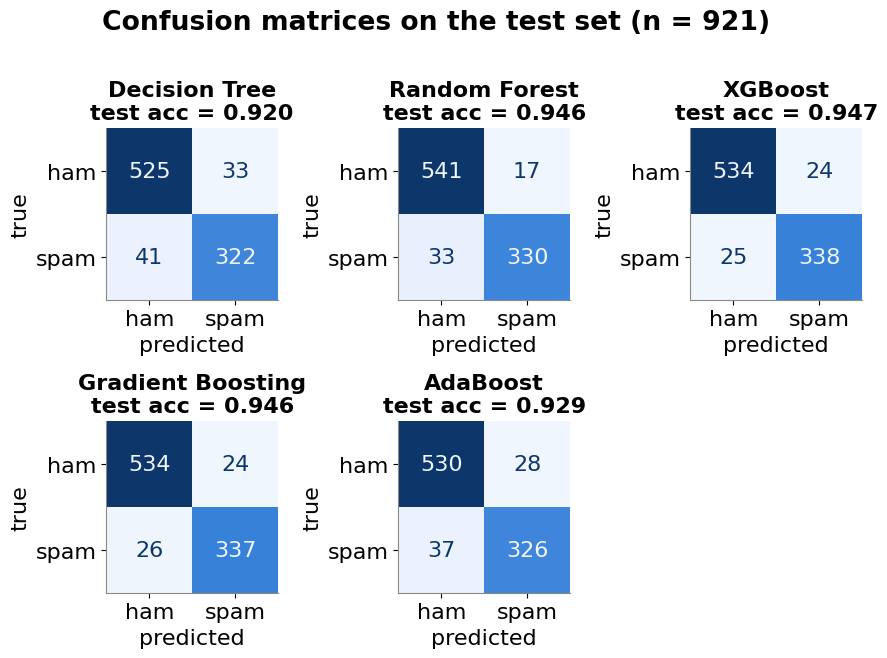

In [24]:
rows, CMS = [], {}
for name, gs in t5_gs.items():
    pred = gs.predict(X_test)
    CMS[name] = confusion_matrix(y_test, pred)
    rows.append({"model": name, "cv_mean_acc": gs.best_score_, **clf_metrics(y_test, pred)})
t5_test = save_table(pd.DataFrame(rows), "t5_test_metrics")
display(t5_test.round(4))
best_model = t5_test.loc[t5_test["cv_mean_acc"].idxmax()]      # chosen by CV accuracy; the test set only reports its scores
for _, r in t5_test.iterrows():
    KEY[f"T5 {r.model} test accuracy"] = r.accuracy
    KEY[f"T5 {r.model} test F1"] = r.f1

with plt.rc_context({"font.size": 16, "axes.titlesize": 16}):    # large enough to read when printed at report width
    fig, axes = plt.subplots(2, 3, figsize=(9, 6.6))
    for ax, (name, cm) in zip(axes.flat, CMS.items()):
        ConfusionMatrixDisplay(cm, display_labels=["ham", "spam"]).plot(ax=ax, cmap=SEQ, colorbar=False, values_format="d")
        acc = np.trace(cm) / cm.sum()
        ax.set_title(f"{name}\ntest acc = {acc:.3f}"); ax.grid(False)
        ax.set_xlabel("predicted"); ax.set_ylabel("true")
    for ax in axes.flat[len(CMS):]:
        ax.axis("off")
    fig.suptitle("Confusion matrices on the test set (n = 921)", fontweight="bold", y=1.0)
    fig.tight_layout(); save_fig(fig, "t5_confusion_matrices"); plt.show()

**Interpretation (Table `t5_test_metrics`, Figure `t5_confusion_matrices`).**
* **XGBoost is the best model, chosen by CV mean accuracy** (0.9576 vs 0.9549 for Gradient Boosting, the runner-up; Table `t5_best_params`). On the test set it scores accuracy 0.9468, precision 0.9337, recall 0.9311, F1 0.9324. Of 921 test e-mails it misclassifies 49: 24 ham flagged as spam and 25 spam missed.
* Random Forest (0.9457, F1 0.9296) and Gradient Boosting (0.9457, F1 0.9309) are within one e-mail-level difference (0.1 point = 1 e-mail). They are statistically indistinguishable from XGBoost on 921 test e-mails.
* RF has the **highest precision** (0.9510, only 17 false alarms) but lower recall (0.9091, 33 missed spam). It is the most "conservative" model, which matters for spam filtering, because losing a real e-mail (false positive) is usually worse than letting a spam through.
* AdaBoost (0.9294) is behind the other ensembles on test accuracy (after Holm correction only XGBoost's lead over it is significant, Section X1b), and the depth-tuned Decision Tree (0.9197; 33 FP, 41 FN) is last. The tree still beats the unrestricted Task 1 tree (0.9110).
* The CV ranking (XGB > GB > RF > Ada > DT) matches the test ranking (RF and GB tie on the test set). Every test score is 0.003–0.013 below its CV estimate. A small drop is expected, because the CV score of the *selected* setting is slightly optimistic: it is the maximum over many settings. Model selection on the training set transferred well to unseen data.

### 5.4 Over- and under-fitting vs model complexity
Left: Decision Tree vs `max_depth` — training accuracy and test accuracy of a tree fitted on the full training set, plus the 5-fold CV validation curve (which is what we select with).
Right: XGBoost 5-fold CV train/validation accuracy vs `max_depth`, with `n_estimators` and `learning_rate` fixed at the CV-best values from 5.2 (reused). The test-accuracy line (one model per depth, fitted on the full training set) is an illustration only and is not used to choose `max_depth`.

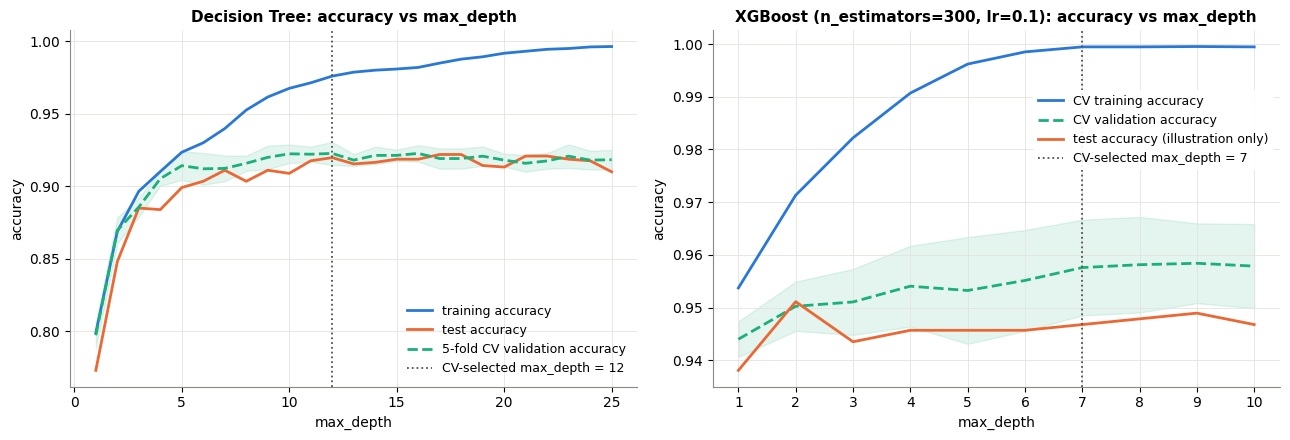

,max_depth,train_acc,test_acc,cv_train_acc,cv_val_acc,cv_val_std
0,1,0.7989,0.7731,0.7999,0.7973,0.0098
1,2,0.8688,0.8480,0.8698,0.8696,0.0099
2,3,0.8965,0.8849,0.8937,0.8856,0.0073
4,5,0.9234,0.8990,0.9265,0.9141,0.0110
7,8,0.9524,0.9034,0.9537,0.9158,0.0058
9,10,0.9674,0.9088,0.9677,0.9223,0.0071
14,15,0.9807,0.9186,0.9828,0.9212,0.0044
19,20,0.9916,0.9131,0.9918,0.9179,0.0050
24,25,0.9962,0.9099,0.9962,0.9182,0.0076


,max_depth,cv_train_acc,cv_val_acc,cv_val_std,test_acc
0,1,0.9537,0.9440,0.0038,0.9381
1,2,0.9713,0.9503,0.0052,0.9511
2,3,0.9822,0.9511,0.0070,0.9435
3,4,0.9907,0.9541,0.0086,0.9457
4,5,0.9962,0.9533,0.0113,0.9457
5,6,0.9985,0.9552,0.0107,0.9457
6,7,0.9995,0.9576,0.0101,0.9468
7,8,0.9995,0.9582,0.0101,0.9479
8,9,0.9995,0.9584,0.0085,0.9490
9,10,0.9995,0.9579,0.0089,0.9468


In [25]:
depths = list(range(1, 26))
tr_acc, te_acc = [], []
for d in depths:
    m = dt(max_depth=d).fit(X_train, y_train)
    tr_acc.append(m.score(X_train, y_train)); te_acc.append(m.score(X_test, y_test))
vc_tr, vc_va = validation_curve(dt(), X_train, y_train, param_name="max_depth", param_range=depths, cv=skf(5), n_jobs=N_JOBS)
t5_cx_dt = save_table(pd.DataFrame({"max_depth": depths, "train_acc": tr_acc, "test_acc": te_acc,
                                    "cv_train_acc": vc_tr.mean(1), "cv_val_acc": vc_va.mean(1), "cv_val_std": vc_va.std(1, ddof=1)}),
                      "t5_complexity_decision_tree")
bx = t5_gs["XGBoost"].best_params_
xd = list(range(1, 11))
xtr, xva = validation_curve(xgb(n_estimators=bx["n_estimators"], learning_rate=bx["learning_rate"]), X_train, y_train,
                            param_name="max_depth", param_range=xd, cv=skf(5), n_jobs=N_JOBS)
xte = [xgb(n_estimators=bx["n_estimators"], learning_rate=bx["learning_rate"], max_depth=d).fit(X_train, y_train)
       .score(X_test, y_test) for d in xd]       # illustration only: max_depth is chosen by CV, never by these values
t5_cx_xgb = save_table(pd.DataFrame({"max_depth": xd, "cv_train_acc": xtr.mean(1), "cv_val_acc": xva.mean(1),
                                     "cv_val_std": xva.std(1, ddof=1), "test_acc": xte}), "t5_complexity_xgboost")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.plot(depths, tr_acc, color=PALETTE[0], label="training accuracy")
ax.plot(depths, te_acc, color=PALETTE[1], label="test accuracy")
ax.plot(depths, vc_va.mean(1), color=PALETTE[2], ls="--", label="5-fold CV validation accuracy")
ax.fill_between(depths, vc_va.mean(1) - vc_va.std(1), vc_va.mean(1) + vc_va.std(1), color=PALETTE[2], alpha=0.12)
bd = t5_gs["Decision Tree"].best_params_["max_depth"]
if bd is not None:
    ax.axvline(bd, ls=":", color=GRAY, lw=1.3, label=f"CV-selected max_depth = {bd}")
ax.set(xlabel="max_depth", ylabel="accuracy", title="Decision Tree: accuracy vs max_depth")
ax.legend(loc="lower right", fontsize=9)
ax = axes[1]
ax.plot(xd, xtr.mean(1), color=PALETTE[0], label="CV training accuracy")
ax.plot(xd, xva.mean(1), color=PALETTE[2], ls="--", label="CV validation accuracy")
ax.fill_between(xd, xva.mean(1) - xva.std(1), xva.mean(1) + xva.std(1), color=PALETTE[2], alpha=0.12)
ax.plot(xd, xte, color=PALETTE[1], label="test accuracy (illustration only)")
ax.axvline(bx["max_depth"], ls=":", color=GRAY, lw=1.3, label=f"CV-selected max_depth = {bx['max_depth']}")
ax.set(xlabel="max_depth", ylabel="accuracy", xticks=xd,
       title=f"XGBoost (n_estimators={bx['n_estimators']}, lr={bx['learning_rate']}): accuracy vs max_depth")
ax.legend(loc="center right", bbox_to_anchor=(1, 0.72), fontsize=9, frameon=True, framealpha=0.9, edgecolor="none")
fig.tight_layout(); save_fig(fig, "t5_complexity_curves"); plt.show()
display(t5_cx_dt.iloc[[0, 1, 2, 4, 7, 9, 14, 19, 24]].round(4)); display(t5_cx_xgb.round(4))

**Interpretation (Figure `t5_complexity_curves`, Tables `t5_complexity_decision_tree`, `t5_complexity_xgboost`).**
* **Decision Tree.**
  * *Under-fitting at depth 1–4:* training, CV and test accuracy are all low and close together (depth 1: 0.80 / 0.80 / 0.77; depth 3: 0.90 / 0.89 / 0.88). The model is too simple.
  * *Sweet spot:* CV accuracy rises until about depth 9–12 (0.920–0.923) and then plateaus.
  * *Over-fitting:* training accuracy keeps climbing to 0.996 at depth 25, while CV and test accuracy flatten and slowly decline (CV 0.918, test 0.910 at depth 25). The train–validation gap widens from 0.01 (depth 3) to 0.05 (depth 12) to 0.08 (depth 25). The extra depth only memorises training e-mails. The CV-selected depth 12 sits at the start of the plateau.
* **XGBoost.**
  * *Under-fitting:* depth-1 stumps give the lowest validation accuracy (0.944) because they cannot model feature interactions.
  * *No real over-fitting:* validation accuracy improves up to depth 7–9 (0.958) and then stays flat. Training accuracy reaches 0.9995 at depth ≥ 7, yet validation does not drop. With shrinkage (lr 0.1) each tree contributes only a small correction, so the boosted ensemble is far more robust to complexity than a single tree. The ±1 std band is wide (about ±0.01), so depths 4–10 are statistically similar.
  * *Test accuracy (orange line, column `test_acc` of `t5_complexity_xgboost`; illustration only, not used to choose max_depth):* it stays within 0.938–0.951 and is flat from depth 4 on (0.946–0.949), so the test set shows no over-fitting either.

### 5.5 Random Forest and XGBoost: baseline vs (a) feature selection vs (b) PCA
The tuned hyper-parameters of RF and XGBoost are **reused from 5.2**; baselines are **reused from 5.3**. Feature selection: `SelectKBest(MI)` (scorer reused from Task 2), k ∈ {10, 20, 30, 40}. PCA: `StandardScaler → PCA(n)`, n ∈ {10, 20, 30, 40}. Both are pipeline steps, so they are refit in every CV fold; k / n are chosen by 5-fold CV on the training set.

,model,variant,setting,cv_mean_acc,accuracy,precision,recall,f1
0,Random Forest,baseline (all 57 features),-,0.9527,0.9457,0.9510,0.9091,0.9296
1,Random Forest,(a) MI feature selection,{'fs__k': 40},0.9514,0.9446,0.9457,0.9118,0.9285
2,Random Forest,(b) PCA,{'pca__n_components': 40},0.9323,0.9164,0.9062,0.8788,0.8923
3,XGBoost,baseline (all 57 features),-,0.9576,0.9468,0.9337,0.9311,0.9324
4,XGBoost,(a) MI feature selection,{'fs__k': 40},0.9549,0.9479,0.9387,0.9284,0.9335
5,XGBoost,(b) PCA,{'pca__n_components': 30},0.9383,0.9240,0.9058,0.9008,0.9033


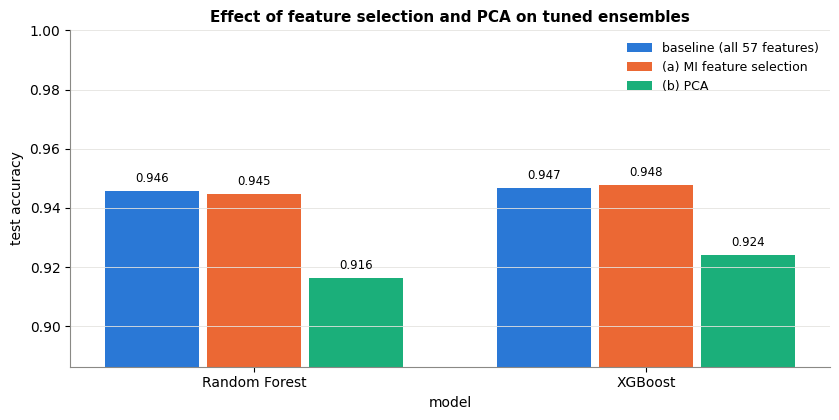

In [26]:
rows = []
for name in ["Random Forest", "XGBoost"]:
    gsb = t5_gs[name]; clf = clone(gsb.best_estimator_)
    rows.append({"model": name, "variant": "baseline (all 57 features)", "setting": "-", "cv_mean_acc": gsb.best_score_,
                 **clf_metrics(y_test, gsb.predict(X_test))})
    for variant, pipe, grid in [
        ("(a) MI feature selection", Pipeline([("fs", SelectKBest(mi_score)), ("clf", clone(clf))]), {"fs__k": [10, 20, 30, 40]}),
        ("(b) PCA", Pipeline([("sc", StandardScaler()), ("pca", PCA(random_state=SEED)), ("clf", clone(clf))]), {"pca__n_components": [10, 20, 30, 40]})]:
        g = GridSearchCV(pipe, grid, cv=skf(5), scoring="accuracy", n_jobs=N_JOBS).fit(X_train, y_train)
        rows.append({"model": name, "variant": variant, "setting": str(g.best_params_), "cv_mean_acc": g.best_score_,
                     **clf_metrics(y_test, g.predict(X_test))})
t5_fp = save_table(pd.DataFrame(rows), "t5_fs_pca_comparison")
display(t5_fp.round(4))

fig, ax = plt.subplots(figsize=(8.5, 4.3))
variants_ = t5_fp.variant.unique(); w = 0.26
for i, v in enumerate(variants_):
    d = t5_fp[t5_fp.variant == v]
    xs = np.arange(2) + (i - 1) * w
    bars = ax.bar(xs, d.accuracy, width=w - 0.02, color=PALETTE[i], label=v)
    for xx, val in zip(xs, d.accuracy):
        ax.text(xx, val + 0.002, f"{val:.3f}", ha="center", va="bottom", fontsize=8.5)
ax.set_xticks(range(2), ["Random Forest", "XGBoost"])
lo = t5_fp.accuracy.min() - 0.03
ax.set(ylim=(lo, 1.0), ylabel="test accuracy", xlabel="model", title="Effect of feature selection and PCA on tuned ensembles")
ax.grid(axis="x", visible=False); ax.legend(loc="upper right", fontsize=9)
fig.tight_layout(); save_fig(fig, "t5_fs_pca_comparison"); plt.show()

**Interpretation (Table `t5_fs_pca_comparison`, Figure `t5_fs_pca_comparison`).**
* **(a) MI feature selection** is **neutral** for both ensembles. CV picks the largest k offered (40), and test accuracy changes by −0.1 points (RF 0.9457 → 0.9446) and +0.1 points (XGB 0.9468 → 0.9479), i.e. one e-mail. Ensembles already ignore uninformative features (random feature subsets in RF, gain-based splits in XGBoost), so removing the 17 weakest features neither helps nor hurts. It does make the models smaller and faster.
* **(b) PCA clearly hurts both.** RF drops to 0.9164 (−2.9 points) and XGBoost to 0.9240 (−2.3 points), with CV losses of the same size (−2.0 and −1.9 points). This is the same effect seen for the single tree in Task 3: tree ensembles exploit sparse, axis-aligned, "is this word present?" splits, and PCA replaces them with dense linear mixtures of all words.
* Both pre-processing steps were fitted inside pipelines, so they were refit on each CV fold and on the training set only.

### 5.6 Why the models differ
* **Single tree vs ensembles (variance).** A single deep tree has low bias but high variance: small changes in the training data change its splits, which explains the large train–test gap and the 0.91–0.92 accuracy. **Bagging (Random Forest)** averages 300 de-correlated trees grown on bootstrap samples with random feature subsets. Averaging cancels much of the variance while keeping the low bias, which gives +2.6 points over the tuned tree.
* **Boosting (bias and variance).** XGBoost and Gradient Boosting add trees sequentially, each fitted to the residual errors of the current ensemble. This reduces bias step by step, and with shrinkage (lr 0.1) plus moderate depth (5–7) the variance stays controlled. XGBoost additionally has L2 regularisation on leaf weights and second-order optimisation, which may explain its small edge (CV 0.9576 vs 0.9549 for GB). **AdaBoost** with depth-1 stumps cannot model interactions (e.g. "*free* AND many capitals"), so it under-fits relative to the depth-5–7 boosters.
* **Depth.** The optimal depth depends on the method: 12 for a single tree (more depth over-fits), unlimited for RF (averaging absorbs the over-fitting), 5–7 for boosting (each tree only needs to model a correction).
* **Noisy features.** Many word frequencies are almost always zero. A single tree can split on them by chance, while ensembles dilute such accidental splits. That is why feature selection helped the single tree a little (Task 2) but was neutral for ensembles (5.5).
* **Class imbalance (61/39)** is mild. All models keep precision and recall within about 4 points of each other (largest gap 4.2 points, Random Forest), so no re-weighting was needed. Where they differ, RF trades recall for precision, which would be the preferred operating point for a real spam filter.
* The differences between XGB, GB and RF (≤ 0.1 point) are within test noise (SE ≈ 0.7 points). The robust conclusion is "RF, GB and XGBoost beat the single tree (AdaBoost not significantly, Section X1b), and boosting ≈ bagging here", not a strict ranking among the top three.

### 5.7 Cost-complexity pruning (`ccp_alpha`)
The pruning path is computed on the training set. Its last alpha prunes the tree to its root, so we leave it out; the remaining path has 106 distinct alphas. We take 30 evenly spaced quantiles of the remaining path with its repeated alphas included, the first being α = 0 (30 values). For each α we record 5-fold CV accuracy on the training set (used for the choice), and — for the plot only — training accuracy, test accuracy and number of leaves of the tree fitted on the full training set.

distinct alphas on the path: 106 | alphas evaluated: 30


,ccp_alpha,cv_mean_acc,cv_std_acc,train_acc,test_acc,n_leaves,depth
0,0.00000,0.91359,0.01090,0.99973,0.91097,237,32
1,0.00023,0.91413,0.01059,0.99891,0.91205,223,30
2,0.00026,0.91495,0.00983,0.99674,0.91314,206,30
3,0.00027,0.91495,0.00983,0.99484,0.91640,192,28
4,0.00027,0.91495,0.00983,0.99239,0.91640,174,28
5,0.00028,0.91522,0.01028,0.99130,0.91857,169,28
6,0.00036,0.91821,0.00747,0.98886,0.91857,158,28
7,0.00038,0.91821,0.00747,0.98560,0.91748,139,22
8,0.00041,0.91875,0.00812,0.98207,0.91965,126,22
9,0.00041,0.91875,0.00812,0.98207,0.91965,126,22


CV-best alpha = 0.000884 | 1-SE alpha (simplest tree within 1 SE) = 0.001118


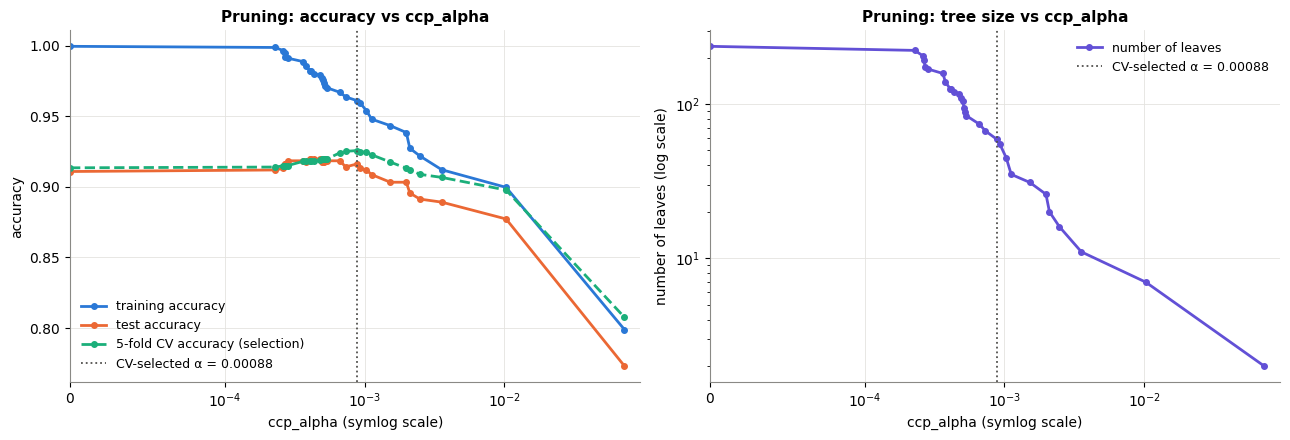

,tree,leaves,accuracy,precision,recall,f1
0,"unpruned (Task 1 baseline, reused)",237,0.9110,0.8828,0.8926,0.8877
1,"max_depth tuned (5.2, reused) = 12",120,0.9197,0.9070,0.8871,0.8969
2,ccp_alpha CV-best = 0.00088,59,0.9164,0.9040,0.8815,0.8926
3,ccp_alpha 1-SE rule = 0.00112 (extra),35,0.9088,0.9043,0.8595,0.8814


In [27]:
path = dt().cost_complexity_pruning_path(X_train, y_train)
path_alphas = path.ccp_alphas[:-1]                     # the last alpha prunes the tree to its root
alphas = np.unique(np.r_[0.0, np.quantile(path_alphas, np.linspace(0, 1, 30))])
print("distinct alphas on the path:", len(np.unique(path_alphas)), "| alphas evaluated:", len(alphas))
rows = []
for a in alphas:
    s = cross_val_score(dt(ccp_alpha=a), X_train, y_train, cv=skf(5), n_jobs=N_JOBS)
    m = dt(ccp_alpha=a).fit(X_train, y_train)
    rows.append({"ccp_alpha": a, "cv_mean_acc": s.mean(), "cv_std_acc": s.std(ddof=1), "train_acc": m.score(X_train, y_train),
                 "test_acc": m.score(X_test, y_test), "n_leaves": m.get_n_leaves(), "depth": m.get_depth()})
t5_ccp = save_table(pd.DataFrame(rows), "t5_ccp_alpha")
ib = t5_ccp.cv_mean_acc.idxmax(); best_alpha = t5_ccp.loc[ib, "ccp_alpha"]
se = t5_ccp.loc[ib, "cv_std_acc"] / np.sqrt(5)
alpha_1se = t5_ccp.loc[t5_ccp.cv_mean_acc >= t5_ccp.loc[ib, "cv_mean_acc"] - se, "ccp_alpha"].max()
display(t5_ccp.round(5))
print(f"CV-best alpha = {best_alpha:.6f} | 1-SE alpha (simplest tree within 1 SE) = {alpha_1se:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.plot(t5_ccp.ccp_alpha, t5_ccp.train_acc, marker="o", ms=4, color=PALETTE[0], label="training accuracy")
ax.plot(t5_ccp.ccp_alpha, t5_ccp.test_acc, marker="o", ms=4, color=PALETTE[1], label="test accuracy")
ax.plot(t5_ccp.ccp_alpha, t5_ccp.cv_mean_acc, marker="o", ms=4, ls="--", color=PALETTE[2], label="5-fold CV accuracy (selection)")
ax.axvline(best_alpha, ls=":", color=GRAY, lw=1.3, label=f"CV-selected α = {best_alpha:.5f}")
ax.set_xscale("symlog", linthresh=1e-4); ax.set_xlim(0, t5_ccp.ccp_alpha.max() * 1.3)
ax.set(xlabel="ccp_alpha (symlog scale)", ylabel="accuracy", title="Pruning: accuracy vs ccp_alpha")
ax.legend(loc="lower left", fontsize=9)
ax = axes[1]
ax.plot(t5_ccp.ccp_alpha, t5_ccp.n_leaves, marker="o", ms=4, color=PALETTE[6], label="number of leaves")
ax.axvline(best_alpha, ls=":", color=GRAY, lw=1.3, label=f"CV-selected α = {best_alpha:.5f}")
ax.set_xscale("symlog", linthresh=1e-4); ax.set_xlim(0, t5_ccp.ccp_alpha.max() * 1.3); ax.set_yscale("log")
ax.set(xlabel="ccp_alpha (symlog scale)", ylabel="number of leaves (log scale)", title="Pruning: tree size vs ccp_alpha")
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout(); save_fig(fig, "t5_ccp_pruning"); plt.show()

pruned = dt(ccp_alpha=best_alpha).fit(X_train, y_train)
pruned_1se = dt(ccp_alpha=alpha_1se).fit(X_train, y_train)
t5_prune = save_table(pd.DataFrame([
    {"tree": "unpruned (Task 1 baseline, reused)", "leaves": dt_base.get_n_leaves(), **clf_metrics(y_test, dt_base.predict(X_test))},
    {"tree": f"max_depth tuned (5.2, reused) = {t5_gs['Decision Tree'].best_params_['max_depth']}",
     "leaves": t5_gs["Decision Tree"].best_estimator_.get_n_leaves(), **clf_metrics(y_test, t5_gs["Decision Tree"].predict(X_test))},
    {"tree": f"ccp_alpha CV-best = {best_alpha:.5f}", "leaves": pruned.get_n_leaves(), **clf_metrics(y_test, pruned.predict(X_test))},
    {"tree": f"ccp_alpha 1-SE rule = {alpha_1se:.5f} (extra)", "leaves": pruned_1se.get_n_leaves(), **clf_metrics(y_test, pruned_1se.predict(X_test))}]),
    "t5_pruning_summary")
display(t5_prune.round(4))
KEY["T5 ccp-pruned DT test accuracy"] = t5_prune.loc[2, "accuracy"]

**Interpretation (Figure `t5_ccp_pruning`, Tables `t5_ccp_alpha`, `t5_pruning_summary`).**
* **Path.** Without its last α (which prunes the tree to its root), the pruning path computed on the training set has 106 distinct α values, from 0 (the full tree with 237 leaves) to 0.072 (2 leaves).
* **Training accuracy** falls monotonically as α grows. **CV accuracy** first *rises*, from 0.9136 at α = 0 to a maximum of **0.9258 at α = 0.00088** (59 leaves, depth 18), and then falls sharply once the tree becomes too small (α ≥ 0.00198, 26 leaves or fewer; 0.81 at 2 leaves). This is the over-fitting → good fit → under-fitting transition seen with max_depth, now controlled by a cost on the number of leaves.
* **Number of leaves** falls from 237 to 59 at the chosen α, a **75% smaller tree**. Test accuracy rises from 0.9110 to 0.9164.
* Test accuracy peaks slightly earlier (0.9197 at α ≈ 0.0004–0.0005, 89–126 leaves). We did *not* choose α from the test curve; that would be leakage. The CV-chosen α is 0.33 points (3 e-mails) below that peak.
* **Comparison (Table `t5_pruning_summary`).** The ccp-pruned tree (59 leaves, test 0.9164) and the depth-limited tree from 5.2 (120 leaves, 0.9197) perform similarly and both beat the unpruned tree (237 leaves, 0.9110). Pruning gives comparable accuracy (test 3 e-mails lower, CV 0.9258 vs 0.9226) with half the leaves of the depth-limited tree.
* **Extra: the 1-SE rule** (largest α within one standard error of the best CV score, α = 0.00112) gives an even smaller tree (35 leaves) at test 0.9088. That is the usual trade-off between simplicity and accuracy.

---
# Beyond the requirements (extra analyses)
Everything below is **additional** to the five required tasks. It uses the same libraries, the same split and the same fitted Task 5 models (**reused from 5.2–5.3**). Every *selection* (thresholds, k) is still made on the training set only. The test set is used only to *evaluate* and *explain* the final models.

## X1. Are the differences between models statistically meaningful?
**X1a — Bootstrap 95% confidence intervals.** The 921 test e-mails are resampled with replacement 2,000 times (seeded). The *same* resamples are used for every model (paired bootstrap), so differences between models can also be given an interval.

metric,accuracy,f1,precision,recall
model,,,,
AdaBoost,0.9294,0.9093,0.9209,0.8981
Decision Tree,0.9197,0.8969,0.9070,0.8871
Gradient Boosting,0.9457,0.9309,0.9335,0.9284
Random Forest,0.9457,0.9296,0.9510,0.9091
XGBoost,0.9468,0.9324,0.9337,0.9311


,model,metric,point,ci_low,ci_high
0,Decision Tree,accuracy,0.9197,0.9012,0.9359
3,Decision Tree,f1,0.8969,0.8734,0.9194
4,Random Forest,accuracy,0.9457,0.9305,0.9598
7,Random Forest,f1,0.9296,0.9099,0.9482
8,XGBoost,accuracy,0.9468,0.9316,0.9609
11,XGBoost,f1,0.9324,0.9132,0.9507
12,Gradient Boosting,accuracy,0.9457,0.9305,0.9598
15,Gradient Boosting,f1,0.9309,0.9106,0.9489
16,AdaBoost,accuracy,0.9294,0.9131,0.9446
19,AdaBoost,f1,0.9093,0.8868,0.9298


,comparison,accuracy_diff,ci_low,ci_high,share_of_resamples_best_wins
0,XGBoost − Decision Tree,0.0271,0.0109,0.0445,0.999
1,XGBoost − Random Forest,0.0011,-0.0098,0.0109,0.538
2,XGBoost − Gradient Boosting,0.0011,-0.0076,0.0098,0.559
3,XGBoost − AdaBoost,0.0174,0.0054,0.0293,0.998


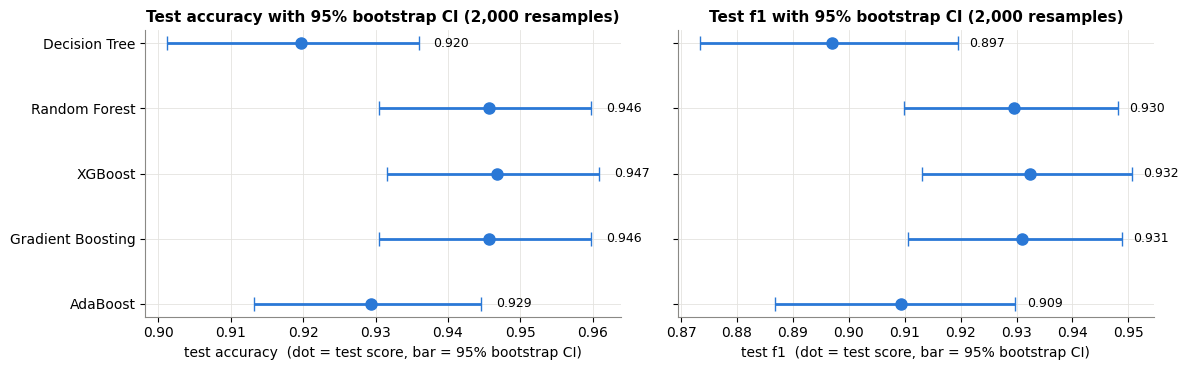

In [28]:
from math import comb

B_BOOT = 2000
rng = np.random.default_rng(SEED)
yt = y_test.values
boot_idx = rng.integers(0, len(yt), size=(B_BOOT, len(yt)))
PRED = {n: gs.predict(X_test) for n, gs in t5_gs.items()}                 # reused fitted models from 5.2
PROBA = {n: gs.predict_proba(X_test)[:, 1] for n, gs in t5_gs.items()}

def boot_metrics(p):
    P, T = p[boot_idx], yt[boot_idx]
    tp = ((P == 1) & (T == 1)).sum(1); fp = ((P == 1) & (T == 0)).sum(1); fn = ((P == 0) & (T == 1)).sum(1)
    return {"accuracy": (P == T).mean(1), "precision": tp / (tp + fp), "recall": tp / (tp + fn), "f1": 2 * tp / (2 * tp + fp + fn)}

rows, BOOT = [], {}
for n, p in PRED.items():
    BOOT[n] = boot_metrics(p); point = clf_metrics(y_test, p)
    for m in ["accuracy", "precision", "recall", "f1"]:
        rows.append({"model": n, "metric": m, "point": point[m],
                     "ci_low": np.percentile(BOOT[n][m], 2.5), "ci_high": np.percentile(BOOT[n][m], 97.5)})
x1_ci = save_table(pd.DataFrame(rows), "x1_bootstrap_ci")
display(x1_ci.pivot(index="model", columns="metric", values="point").round(4))
display(x1_ci[x1_ci.metric.isin(["accuracy", "f1"])].round(4))

best_name = best_model.model                                              # best model from 5.3 (reused)
rows = []
for n in PRED:
    if n == best_name:
        continue
    d = BOOT[best_name]["accuracy"] - BOOT[n]["accuracy"]
    rows.append({"comparison": f"{best_name} − {n}", "accuracy_diff": clf_metrics(y_test, PRED[best_name])["accuracy"] - clf_metrics(y_test, PRED[n])["accuracy"],
                 "ci_low": np.percentile(d, 2.5), "ci_high": np.percentile(d, 97.5), "share_of_resamples_best_wins": (d > 0).mean()})
x1_diff = save_table(pd.DataFrame(rows), "x1_bootstrap_accuracy_difference")
display(x1_diff.round(4))
KEY["X1 XGBoost test accuracy 95% CI low"] = x1_ci.query("model == @best_name and metric == 'accuracy'").ci_low.item()
KEY["X1 XGBoost test accuracy 95% CI high"] = x1_ci.query("model == @best_name and metric == 'accuracy'").ci_high.item()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
order = list(PRED)[::-1]
for ax, m in zip(axes, ["accuracy", "f1"]):
    d = x1_ci[x1_ci.metric == m].set_index("model").loc[order]
    ax.errorbar(d.point, range(len(d)), xerr=[d.point - d.ci_low, d.ci_high - d.point], fmt="o", ms=8, capsize=5, color=PALETTE[0])
    for i, (pt, hi) in enumerate(zip(d.point, d.ci_high)):
        ax.text(hi + 0.002, i, f"{pt:.3f}", va="center", fontsize=9)
    ax.set_yticks(range(len(d)), d.index)
    ax.set(xlabel=f"test {m}  (dot = test score, bar = 95% bootstrap CI)", title=f"Test {m} with 95% bootstrap CI (2,000 resamples)")
fig.tight_layout(); save_fig(fig, "x1_bootstrap_ci"); plt.show()

**Interpretation (Tables `x1_bootstrap_ci`, `x1_bootstrap_accuracy_difference`, Figure `x1_bootstrap_ci`).**
* **The test set measures each model only to about ±1.5 points.** XGBoost scores 0.947 [95% CI 0.932, 0.961] and F1 0.932 [0.913, 0.951]. Random Forest and Gradient Boosting score 0.946 [0.931, 0.960], AdaBoost 0.929 [0.913, 0.945] and the Decision Tree 0.920 [0.901, 0.936]. These intervals are what 921 test e-mails can resolve, so a difference of 0.1 point (one e-mail) means nothing on its own.
* **The paired bootstrap of differences is sharper than comparing intervals by eye**, because every resample uses the same e-mails for both models:
  * XGBoost − Decision Tree = +2.7 points [+1.1, +4.5]. XGBoost wins in 99.9% of resamples.
  * XGBoost − AdaBoost = +1.7 points [+0.5, +2.9]. XGBoost wins in 99.8% of resamples.
  * XGBoost − Random Forest = +0.1 [−1.0, +1.1] and XGBoost − Gradient Boosting = +0.1 [−0.8, +1.0]. XGBoost "wins" in only 54% and 56% of resamples, a coin flip.
* **Conclusion:** XGBoost clearly beats the single tree and, more narrowly, AdaBoost (McNemar's test in X1b finds this lead just significant after Holm, p = 0.049), but it is *not* distinguishable from Random Forest or Gradient Boosting. Section 5.3 claimed this on the basis of the standard error; the paired bootstrap now quantifies it.

**X1b — McNemar's exact test.** For each pair of models, only the test e-mails on which they *disagree* carry information: b = model A right, B wrong; c = A wrong, B right. Under H0 (equal error rates) b ~ Binomial(b+c, 0.5). The test is computed exactly with `math.comb` (no extra library). p-values are Holm-corrected for the 10 comparisons.

In [29]:
def mcnemar_exact(b, c):
    n, k = b + c, min(b, c)
    return 1.0 if n == 0 else min(1.0, 2 * sum(comb(n, i) for i in range(k + 1)) / 2 ** n)

names_ = list(PRED); rows = []
for i in range(len(names_)):
    for j in range(i + 1, len(names_)):
        a, b_ = names_[i], names_[j]
        ra, rb = PRED[a] == yt, PRED[b_] == yt
        b, c = int((ra & ~rb).sum()), int((~ra & rb).sum())
        rows.append({"model_A": a, "model_B": b_, "A_right_B_wrong": b, "A_wrong_B_right": c, "p_exact": mcnemar_exact(b, c)})
x1_mc = pd.DataFrame(rows).sort_values("p_exact").reset_index(drop=True)
m_ = len(x1_mc)                                                            # Holm step-down correction
x1_mc["p_holm"] = np.minimum(1, np.maximum.accumulate([(m_ - r) * p for r, p in enumerate(x1_mc.p_exact)]))
x1_mc["significant_5pct"] = x1_mc.p_holm < 0.05
save_table(x1_mc, "x1_mcnemar")
display(x1_mc.round(4))

,model_A,model_B,A_right_B_wrong,A_wrong_B_right,p_exact,p_holm,significant_5pct
0,Decision Tree,Random Forest,14,38,0.0012,0.0120,True
1,Decision Tree,XGBoost,18,43,0.0019,0.0168,True
2,Decision Tree,Gradient Boosting,18,42,0.0027,0.0214,True
3,XGBoost,AdaBoost,24,8,0.0070,0.0490,True
4,Random Forest,AdaBoost,23,8,0.0107,0.0640,False
5,Gradient Boosting,AdaBoost,25,10,0.0167,0.0834,False
6,Decision Tree,AdaBoost,30,39,0.3356,1.0000,False
7,Random Forest,XGBoost,11,12,1.0000,1.0000,False
8,XGBoost,Gradient Boosting,9,8,1.0000,1.0000,False
9,Random Forest,Gradient Boosting,12,12,1.0000,1.0000,False


**Interpretation (Table `x1_mcnemar`).** McNemar's test looks only at the e-mails on which two models disagree.
* **The top three ensembles disagree very rarely and evenly:** RF vs XGBoost 11 vs 12 e-mails, XGBoost vs GB 9 vs 8, RF vs GB 12 vs 12, all with p = 1.0. They make almost the same mistakes, so there is no evidence of any difference between them.
* **Every ensemble except AdaBoost is significantly better than the Decision Tree** after Holm correction for 10 tests (e.g. DT vs RF: the tree is right where RF is wrong on 14 e-mails, and wrong where RF is right on 38; Holm p = 0.012).
* **XGBoost vs AdaBoost** is just significant (24 vs 8, Holm p = 0.049). RF vs AdaBoost (Holm p = 0.064) and GB vs AdaBoost (0.083) are not, and neither is DT vs AdaBoost (p = 1.0).
* **Together with X1a this gives a defensible ranking:** {XGBoost ≈ GB ≈ RF} ≥ AdaBoost ≥ Decision Tree. Only XGBoost's lead over AdaBoost is significant after Holm, and RF, GB and XGBoost each beat the tree. The Holm correction matters here. Without it, RF vs AdaBoost (raw p = 0.011) would wrongly be called significant.

**X1c — Nested cross-validation.** `best_score_` from a grid search is the *maximum* over many settings, so it is optimistically biased. Nested CV wraps the whole tuning procedure (inner 5-fold `GridSearchCV`, the same grids as 5.2) inside an outer 5-fold CV on the training set. It gives an unbiased estimate of "tune, then predict" without touching the test set.

In [30]:
rows = []
for name in ["Decision Tree", "Random Forest", "XGBoost"]:
    est, grid = SEARCH[name]                                              # same grids as 5.2
    t0 = time.perf_counter()
    inner = GridSearchCV(clone(est), grid, cv=skf(5), scoring="accuracy", n_jobs=N_JOBS)
    outer = cross_val_score(inner, X_train, y_train, cv=skf(5), n_jobs=1)
    rows.append({"model": name, "non_nested_cv_best_score": t5_gs[name].best_score_, "nested_cv_mean": outer.mean(),
                 "nested_cv_std": outer.std(ddof=1), "optimism": t5_gs[name].best_score_ - outer.mean(),
                 "test_accuracy": clf_metrics(y_test, PRED[name])["accuracy"], "time_s": time.perf_counter() - t0})
x1_nested = save_table(pd.DataFrame(rows), "x1_nested_cv")
display(x1_nested.round(4))
KEY["X1 XGBoost nested CV accuracy"] = x1_nested.loc[x1_nested.model == "XGBoost", "nested_cv_mean"].item()

,model,non_nested_cv_best_score,nested_cv_mean,nested_cv_std,optimism,test_accuracy,time_s
0,Decision Tree,0.9226,0.9215,0.0101,0.0011,0.9197,3.4906
1,Random Forest,0.9527,0.9500,0.0063,0.0027,0.9457,100.5049
2,XGBoost,0.9576,0.9524,0.0112,0.0052,0.9468,183.5033


**Interpretation (Table `x1_nested_cv`).** Nested CV is consistent with the explanation given in 5.3: the CV score of the *selected* setting is optimistic, because it is the maximum over the grid.
* **The optimism is small:** +0.11 points for the Decision Tree (11 settings), +0.27 for Random Forest (12 settings, but very similar ones) and +0.52 for XGBoost (36 settings). The order is consistent with optimism growing with grid size, but each value is below the nested-CV standard deviation (0.6–1.1 points), so it does not establish that trend.
* **The nested estimates sit between the non-nested CV score and the test score:** XGBoost 0.9576 (non-nested) → 0.9524 ± 0.011 (nested) → 0.9468 (test), and RF 0.9527 → 0.9500 → 0.9457. The remaining gap to the test score is within one nested-CV standard deviation, i.e. ordinary sampling noise.
* **The ranking of the three models is unchanged** under nested CV (XGBoost > RF > DT), so the *selection* in 5.2 was sound even though its reported scores were slightly optimistic.
* **Cost:** nested CV repeats the 5-fold grid search in each of 5 outer folds (25 fits per setting instead of 5; 184 s for XGBoost in this run), which is why it is used as a check and not for every experiment.

## X2. Treating the model as a real spam filter
**X2a — ROC and precision–recall curves** of the five tuned models on the test set.

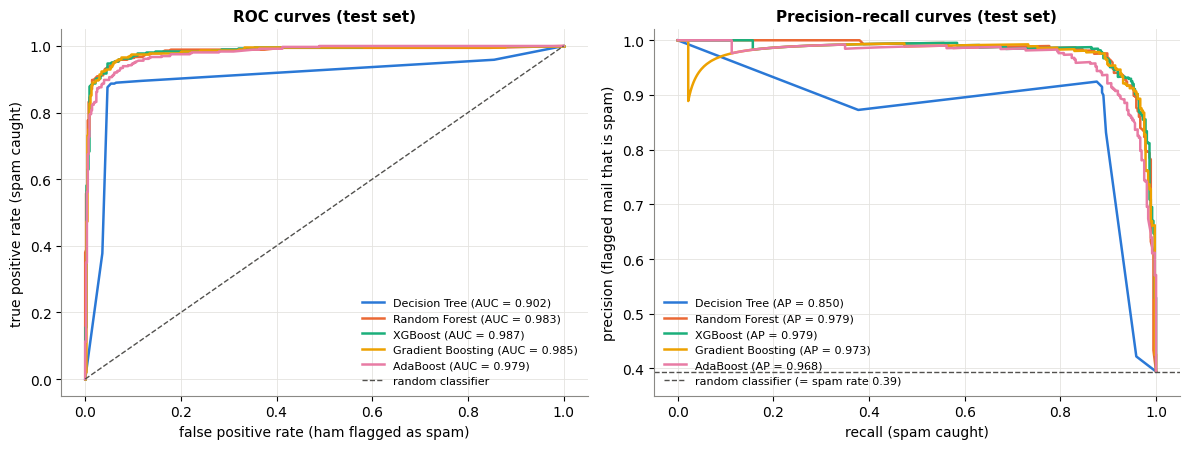

,model,roc_auc,average_precision
0,Decision Tree,0.9023,0.8504
1,Random Forest,0.9835,0.9794
2,XGBoost,0.9866,0.9795
3,Gradient Boosting,0.9848,0.9732
4,AdaBoost,0.9793,0.9683


In [31]:
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
rows = []
for i, (n, pr) in enumerate(PROBA.items()):
    fpr, tpr, _ = roc_curve(y_test, pr); prec, rec, _ = precision_recall_curve(y_test, pr)
    auc, ap = roc_auc_score(y_test, pr), average_precision_score(y_test, pr)
    rows.append({"model": n, "roc_auc": auc, "average_precision": ap})
    axes[0].plot(fpr, tpr, color=PALETTE[i], lw=1.8, label=f"{n} (AUC = {auc:.3f})")
    axes[1].plot(rec, prec, color=PALETTE[i], lw=1.8, label=f"{n} (AP = {ap:.3f})")
axes[0].plot([0, 1], [0, 1], ls="--", color=GRAY, lw=1, label="random classifier")
axes[0].set(xlabel="false positive rate (ham flagged as spam)", ylabel="true positive rate (spam caught)", title="ROC curves (test set)")
axes[1].axhline(y_test.mean(), ls="--", color=GRAY, lw=1, label=f"random classifier (= spam rate {y_test.mean():.2f})")
axes[1].set(xlabel="recall (spam caught)", ylabel="precision (flagged mail that is spam)", title="Precision–recall curves (test set)", ylim=(0.35, 1.02))
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "lower left", fontsize=8)
fig.tight_layout(); save_fig(fig, "x2_roc_pr_curves"); plt.show()
x2_auc = save_table(pd.DataFrame(rows), "x2_auc")
display(x2_auc.round(4))

**Interpretation (Figure `x2_roc_pr_curves`, Table `x2_auc`).** ROC AUC and average precision (AP) measure how well each model *ranks* e-mails by spam probability, independent of the 0.5 threshold.
* **The four ensembles are excellent rankers:** XGBoost ROC AUC 0.987 / AP 0.979, RF 0.983 / 0.979, GB 0.985 / 0.973, AdaBoost 0.979 / 0.968.
* **The Decision Tree is clearly worse** (AUC 0.902, AP 0.850). Its probabilities come from the class proportions in about 120 leaves, so it can only output a few distinct values, and its curves are made of a few straight segments.
* **The PR curves show the practical difference.** To catch 90% of the spam, RF and XGBoost still have precision of about 0.965 (about 1 false alarm per 28 flagged e-mails). The tree's best precision at that recall is only 0.42, because its coarse probabilities cannot separate the hardest cases.
* Because the ensembles rank so well, the *threshold* (X2b), not the model, decides the trade-off between false alarms and missed spam.

**X2b — Cost-sensitive decision threshold.** In a real mailbox, losing a legitimate e-mail in the spam folder (false positive) is much worse than seeing one extra spam (false negative). We assume **one false positive costs as much as 10 false negatives**. For each model the threshold is chosen to minimise this cost on **out-of-fold predicted probabilities on the training set** (`cross_val_predict`, 5 folds, with the tuned settings from 5.2). The test set is then scored once at the default 0.5 and once at the chosen threshold.

,model,threshold_rule,threshold,test_FP,test_FN,test_cost,test_cost_per_1000_emails,test_accuracy
0,Decision Tree,default 0.5,0.50,34,41,381,413.6808,0.9186
1,Decision Tree,cost-optimal (chosen on training OOF),0.98,26,45,305,331.1618,0.9229
2,Random Forest,default 0.5,0.50,17,33,203,220.4126,0.9457
3,Random Forest,cost-optimal (chosen on training OOF),0.74,4,65,105,114.0065,0.9251
4,XGBoost,default 0.5,0.50,24,25,265,287.7307,0.9468
5,XGBoost,cost-optimal (chosen on training OOF),0.95,4,58,98,106.4061,0.9327
6,Gradient Boosting,default 0.5,0.50,24,26,266,288.8165,0.9457
7,Gradient Boosting,cost-optimal (chosen on training OOF),0.94,5,65,115,124.8643,0.9240
8,AdaBoost,default 0.5,0.50,28,37,317,344.1911,0.9294
9,AdaBoost,cost-optimal (chosen on training OOF),0.52,13,61,191,207.3833,0.9197


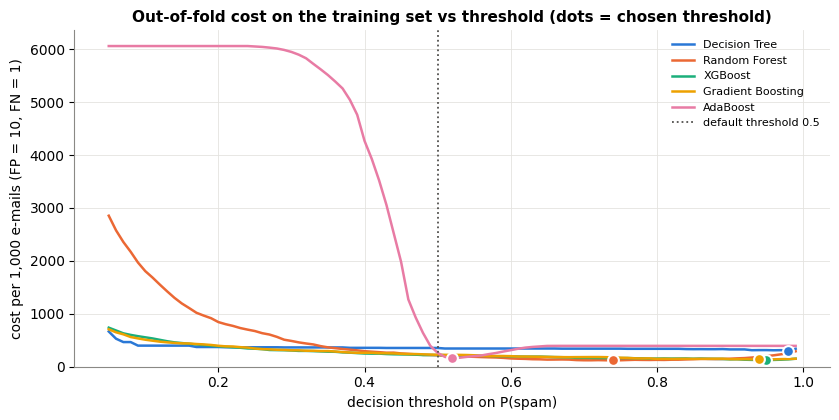

In [32]:
from sklearn.model_selection import cross_val_predict

COST_FP, COST_FN = 10, 1
THR = np.round(np.linspace(0.05, 0.99, 95), 2)
def cost_of(y_true, proba, t):
    p = (proba >= t).astype(int)
    fp = int(((p == 1) & (y_true == 0)).sum()); fn = int(((p == 0) & (y_true == 1)).sum())
    return COST_FP * fp + COST_FN * fn, fp, fn

rows, OOF_COST = [], {}
for n, gs in t5_gs.items():
    oof = cross_val_predict(clone(gs.best_estimator_), X_train, y_train, cv=skf(5), method="predict_proba", n_jobs=N_JOBS)[:, 1]
    costs = np.array([cost_of(y_train.values, oof, t)[0] for t in THR]) / len(y_train)
    OOF_COST[n] = costs; t_star = float(THR[costs.argmin()])
    for label, t in [("default 0.5", 0.5), ("cost-optimal (chosen on training OOF)", t_star)]:
        c, fp, fn = cost_of(yt, PROBA[n], t)
        rows.append({"model": n, "threshold_rule": label, "threshold": t, "test_FP": fp, "test_FN": fn, "test_cost": c,
                     "test_cost_per_1000_emails": 1000 * c / len(yt), "test_accuracy": ((PROBA[n] >= t) == yt).mean()})
x2_cost = save_table(pd.DataFrame(rows), "x2_cost_threshold")
display(x2_cost.round(4))
best_cost_row = x2_cost[x2_cost.threshold_rule.str.startswith("cost")].sort_values("test_cost").iloc[0]
KEY["X2 lowest test cost per 1000 e-mails (cost-optimal threshold)"] = best_cost_row.test_cost_per_1000_emails

fig, ax = plt.subplots(figsize=(8.5, 4.3))
for i, (n, c) in enumerate(OOF_COST.items()):
    ax.plot(THR, 1000 * c, color=PALETTE[i], lw=1.8, label=n)
    ax.scatter(THR[c.argmin()], 1000 * c.min(), color=PALETTE[i], s=60, zorder=4, edgecolor="white", linewidth=1.5)
ax.axvline(0.5, ls=":", color=GRAY, lw=1.3, label="default threshold 0.5")
ax.set(xlabel="decision threshold on P(spam)", ylabel="cost per 1,000 e-mails (FP = 10, FN = 1)",
       title="Out-of-fold cost on the training set vs threshold (dots = chosen threshold)", ylim=(0, None))
ax.legend(fontsize=8, loc="upper right")
fig.tight_layout(); save_fig(fig, "x2_cost_vs_threshold"); plt.show()

**Interpretation (Table `x2_cost_threshold`, Figure `x2_cost_vs_threshold`).** With a false positive costing 10× a false negative, the default threshold 0.5 is far from optimal for every model.
* **The thresholds are chosen on the training set's out-of-fold predictions**, so the test set is still only used for evaluation. The out-of-fold cost curves (figure) are flat-bottomed at high thresholds: 0.95 for XGBoost, 0.94 for GB, 0.74 for RF.
* **XGBoost:** cost falls from 265 at threshold 0.5 (24 FP, 25 FN; 288 per 1,000 e-mails) to **98 at threshold 0.95** (4 FP, 58 FN; 106 per 1,000), a **63% reduction**. Only 4 legitimate e-mails out of 558 end up in the spam folder.
* **The price is accuracy, which falls from 0.947 to 0.933.** That is the point: *accuracy treats both errors as equal, so the cost-optimal filter has lower accuracy but is the better filter.*
* **Random Forest** reaches almost the same cost (105; 4 FP) at a lower threshold (0.74). RF's probabilities are averages of 300 votes and are less extreme than XGBoost's, so its threshold sits lower.
* **AdaBoost's** probabilities are squeezed around 0.5 (a sum of many weighted stumps), so the threshold barely moves (0.52) and the cost stays high (191).
* **The Decision Tree** is still the most expensive (305).
* **Ranking by cost** gives XGBoost (106 per 1,000) ≈ RF (114) < GB (125) < AdaBoost (207) < DT (331). The cost view confirms the accuracy view at the top, but it separates the models more clearly than accuracy does.
* **Why the Decision Tree's 0.5 row differs by one e-mail from `t5_test_metrics`** (34 vs 33 FP): one test e-mail falls in a leaf with P(spam) exactly 0.5. `predict` assigns such ties to class 0, while the threshold rule here uses P ≥ 0.5 and calls it spam. It is a legitimate e-mail, so it adds one false positive.

**X2c — Error analysis of the best model.** What do the e-mails that XGBoost gets wrong look like? Below are the mean values of the eight strongest features (Task 2 RF ranking, reused) for each confusion-matrix cell, and the distribution of predicted spam probabilities.

,n_emails,char_freq_excl,char_freq_dollar,word_freq_remove,word_freq_free,capital_run_length_average,capital_run_length_longest,word_freq_your,capital_run_length_total,mean_P(spam)
cell,,,,,,,,,,
TP (spam caught),338,0.594,0.168,0.280,0.585,8.882,110.559,1.377,557.678,0.977
FN (spam missed),25,0.291,0.015,0.010,0.451,2.220,11.920,1.550,61.000,0.182
TN (ham kept),534,0.069,0.012,0.004,0.050,2.650,19.843,0.481,160.755,0.019
FP (ham flagged),24,0.473,0.040,0.090,0.391,2.932,32.792,0.734,167.792,0.799


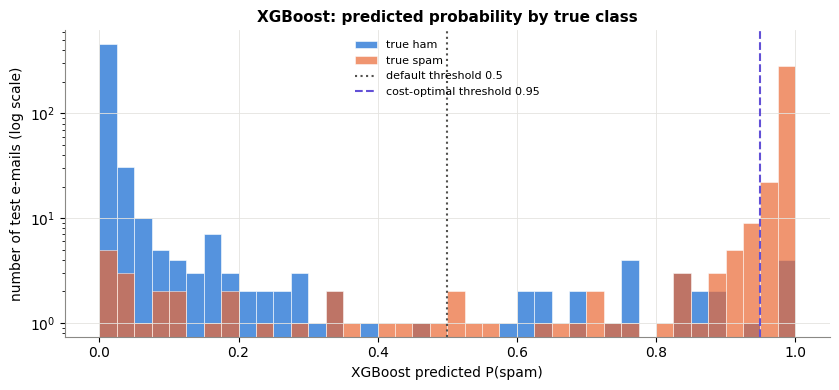

In [33]:
p_best = PRED[best_name]; pr_best = PROBA[best_name]
cell = np.select([(p_best == 1) & (yt == 1), (p_best == 0) & (yt == 0), (p_best == 1) & (yt == 0), (p_best == 0) & (yt == 1)],
                 ["TP (spam caught)", "TN (ham kept)", "FP (ham flagged)", "FN (spam missed)"], default="")
top8 = list(rf_imp.index[:8])                                                    # reused from Task 2
x2_err = X_test[top8].groupby(cell).mean()
x2_err.insert(0, "n_emails", pd.Series(cell).value_counts())
x2_err["mean_P(spam)"] = pd.Series(pr_best).groupby(cell).mean()
x2_err = x2_err.loc[["TP (spam caught)", "FN (spam missed)", "TN (ham kept)", "FP (ham flagged)"]]
x2_err.index.name = "cell"
save_table(x2_err.reset_index(), "x2_error_analysis")
display(x2_err.round(3))

fig, ax = plt.subplots(figsize=(8.5, 4))
bins = np.linspace(0, 1, 41)
ax.hist(pr_best[yt == 0], bins=bins, color=PALETTE[0], alpha=0.8, label="true ham", edgecolor="white", linewidth=0.5)
ax.hist(pr_best[yt == 1], bins=bins, color=PALETTE[1], alpha=0.7, label="true spam", edgecolor="white", linewidth=0.5)
ax.axvline(0.5, ls=":", color=GRAY, lw=1.5, label="default threshold 0.5")
t_best = x2_cost.query("model == @best_name and threshold_rule != 'default 0.5'").threshold.item()
ax.axvline(t_best, ls="--", color=PALETTE[6], lw=1.5, label=f"cost-optimal threshold {t_best:.2f}")
ax.set_yscale("log")
ax.set(xlabel=f"{best_name} predicted P(spam)", ylabel="number of test e-mails (log scale)", title=f"{best_name}: predicted probability by true class")
ax.legend(fontsize=8, loc="upper center")
fig.tight_layout(); save_fig(fig, "x2_probability_histogram"); plt.show()

**Interpretation (Table `x2_error_analysis`, Figure `x2_probability_histogram`).**
* **Missed spam (FN, 25 e-mails) looks like ham.** Compared with caught spam it has 11× fewer `$` (0.015 vs 0.168), almost no *remove* (0.010 vs 0.280) and much shorter capital runs (average 2.2 vs 8.9, longest 12 vs 111). These are "quiet" spam messages without shouting or money talk. The model gives them a mean P(spam) of only 0.18, so with these 57 features they are essentially undetectable.
* **False alarms (FP, 24 e-mails) are ham that sounds like spam.** They contain far more `!` (0.47 vs 0.07 in correctly kept ham), *free* (0.39 vs 0.05) and *remove* (0.09 vs 0.004) than normal ham, while their capital-run lengths are typical of ham. Examples would be newsletters or promotions the user actually wanted. Their mean P(spam) is 0.80, so they are confident mistakes.
* **The histogram (log scale)** shows that most e-mails get probabilities very close to 0 or 1. The errors live in the sparse middle band, plus a handful of ham e-mails with P(spam) > 0.95. Those are the 4 false positives that remain even at the cost-optimal threshold.
* **Implication:** better performance would need *new information* (sender, headers, links, full text) rather than a better model, which is consistent with the flat learning curves in X3c.

## X3. Explaining the best model
**X3a — Permutation importance on the test set** (10 repeats, seeded): the drop in test accuracy when one feature's values are shuffled. Unlike impurity importance, it measures what the *final* model actually relies on for unseen data. We use it for explanation only; nothing is selected with it.

,feature,importance_mean,importance_std,rank_permutation,rank_mi_task2,rank_rf_importance_task2
0,word_freq_george,0.0300,0.0043,1.0,14.0,14.0
1,word_freq_edu,0.0215,0.0046,2.5,34.0,16.0
2,word_freq_remove,0.0215,0.0034,2.5,7.0,3.0
3,word_freq_hp,0.0168,0.0031,4.0,9.0,9.0
4,capital_run_length_total,0.0128,0.0037,5.0,8.0,8.0
5,char_freq_excl,0.0107,0.0045,6.0,2.0,1.0
6,char_freq_dollar,0.0072,0.0038,7.0,1.0,2.0
7,word_freq_free,0.0058,0.0016,8.0,6.0,4.0
8,word_freq_our,0.0051,0.0022,9.0,13.0,11.0
9,word_freq_re,0.0043,0.0031,10.0,30.0,23.0


Spearman rank correlation (all 57 features): permutation vs MI = 0.47, permutation vs RF importance = 0.60
features whose permutation importance is <= 0: 20


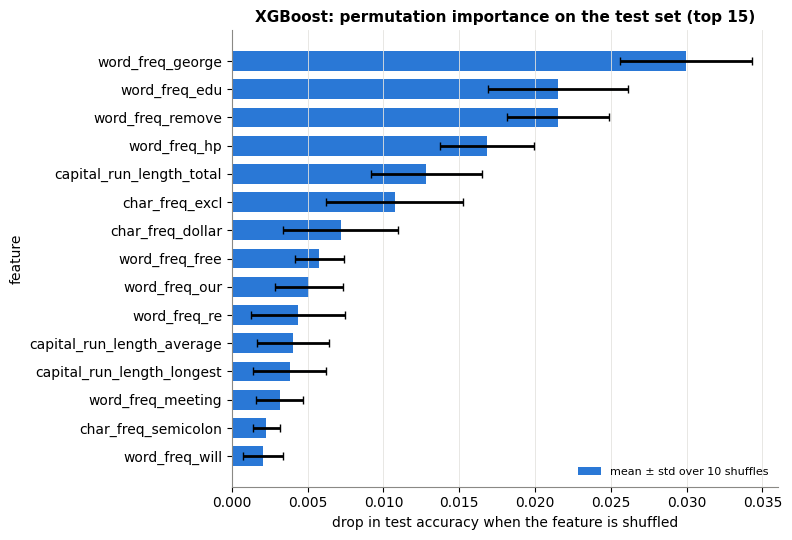

In [34]:
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

best_est = t5_gs[best_name].best_estimator_
pi = permutation_importance(best_est, X_test, y_test, n_repeats=10, random_state=SEED, scoring="accuracy", n_jobs=N_JOBS)
x3_pi = pd.DataFrame({"feature": X_test.columns, "importance_mean": pi.importances_mean, "importance_std": pi.importances_std})
x3_pi["rank_permutation"] = x3_pi.importance_mean.rank(ascending=False)
x3_pi["rank_mi_task2"] = x3_pi.feature.map(mi_vals.rank(ascending=False))               # reused from Task 2
x3_pi["rank_rf_importance_task2"] = x3_pi.feature.map(rf_imp.rank(ascending=False))     # reused from Task 2
x3_pi = x3_pi.sort_values("importance_mean", ascending=False).reset_index(drop=True)
save_table(x3_pi, "x3_permutation_importance")
display(x3_pi.head(15).round(4))
print("Spearman rank correlation (all 57 features): permutation vs MI = %.2f, permutation vs RF importance = %.2f"
      % (x3_pi[["rank_permutation", "rank_mi_task2"]].corr(method="spearman").iloc[0, 1],
         x3_pi[["rank_permutation", "rank_rf_importance_task2"]].corr(method="spearman").iloc[0, 1]))
print("features whose permutation importance is <= 0:", int((x3_pi.importance_mean <= 0).sum()))

top = x3_pi.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.feature, top.importance_mean, xerr=top.importance_std, color=PALETTE[0], height=0.7, capsize=3, label="mean ± std over 10 shuffles")
ax.set(xlabel="drop in test accuracy when the feature is shuffled", ylabel="feature",
       title=f"{best_name}: permutation importance on the test set (top 15)")
ax.grid(axis="y", visible=False); ax.legend(loc="lower right", fontsize=8)
fig.tight_layout(); save_fig(fig, "x3_permutation_importance"); plt.show()

**Interpretation (Table `x3_permutation_importance`, Figure `x3_permutation_importance`).** This is the most surprising extra result.
* **Three of the four features the tuned XGBoost relies on most are *ham* markers:** *george* (test accuracy drops by 3.0 points when shuffled), *edu* (2.1), *remove* (2.1, a spam marker) and *hp* (1.7). They are followed by `capital_run_length_total`, `!`, `$` and *free*.
* The Task 2 rankings were built from *univariate* (MI) or *impurity* (RF) scores, which favour the frequent spam markers `$` and `!`. The rank correlation with permutation importance over all 57 features is only moderate (Spearman 0.47 with MI, 0.60 with RF importance). *edu* ranks 34th by MI but joint 2nd here (tied with *remove*).
* **Why:** once `$`, `!` and capital runs have flagged most spam, the remaining hard decisions are about which spammy-looking e-mails are actually legitimate. The model resolves them with the mailbox owner's personal vocabulary: George Forman at HP Labs, with university (.edu) contacts.
* **Consequence:** the classifier is partly *personalised* to this one mailbox and would likely lose accuracy on someone else's mail. That is a dataset-shift risk invisible in the test score, because the test set comes from the same mailbox.
* **20 features have zero or negative importance.** XGBoost could drop them without loss, which is consistent with the neutral feature-selection result in 5.5.
* **Caveat:** for correlated features (the three capital-run statistics) permutation importance *understates* each one, because shuffling one leaves the others intact.

**X3b — Partial dependence** of the predicted spam probability on the four most important features (averaged over the training e-mails). Grid from the 0th to the 99th percentile, because most word features are zero for most e-mails.

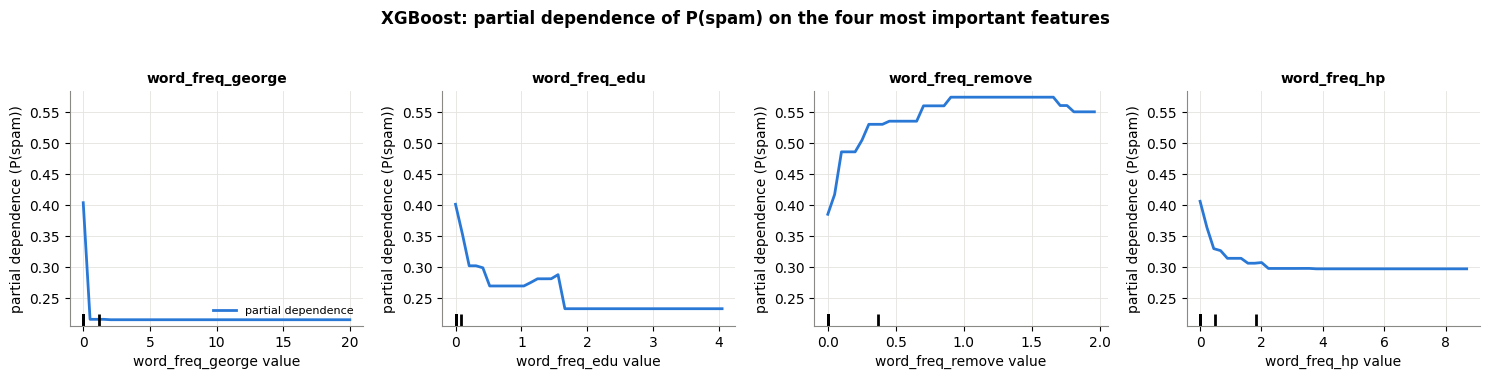

In [35]:
pd_feats = list(x3_pi.feature[:4])
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
PartialDependenceDisplay.from_estimator(best_est, X_train, pd_feats, kind="average", percentiles=(0.0, 0.99),
                                        grid_resolution=40, ax=axes, line_kw={"color": PALETTE[0], "lw": 2, "label": "partial dependence"})
for ax, f in zip(axes, pd_feats):
    ax.set_title(f, fontsize=10); ax.set_xlabel(f"{f} value"); ax.set_ylabel("partial dependence (P(spam))")
    if ax.get_legend():
        ax.get_legend().remove()
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle(f"{best_name}: partial dependence of P(spam) on the four most important features", fontweight="bold", y=1.04)
fig.tight_layout(); save_fig(fig, "x3_partial_dependence"); plt.show()

**Interpretation (Figure `x3_partial_dependence`).** The partial-dependence curves show *how* the four most important features move the predicted spam probability, averaged over the training e-mails.
* **george:** a single occurrence drops P(spam) from about 0.40 to 0.22, and more occurrences change nothing. It is a pure presence/absence switch.
* **edu:** a mostly decreasing step function, from 0.40 to about 0.23 above a frequency of about 1.6%, with a small rise just before that final drop.
* **remove:** the only spam marker of the four. P(spam) rises steeply from 0.39 to about 0.49 already at frequency 0.1%, and then saturates around 0.57, falling back slightly at the top of its range.
* **hp:** decreases from 0.41 to about 0.30 and then flattens.
* **All four effects are nearly monotone, strongly non-linear and saturating.** That is exactly what tree ensembles model easily (step functions) and what the linear logistic regression of Task 3 cannot represent without transformed inputs. It is part of the reason the ensembles beat logistic regression (0.947 vs 0.929 test accuracy).
* The rug marks show the deciles. Most e-mails sit at 0 for these words, so the shape at high values rests on few e-mails.

**X3c — Learning curves.** Would more training data help? 5-fold CV on the training set with 10%–100% of each training fold, using the tuned settings from 5.2.

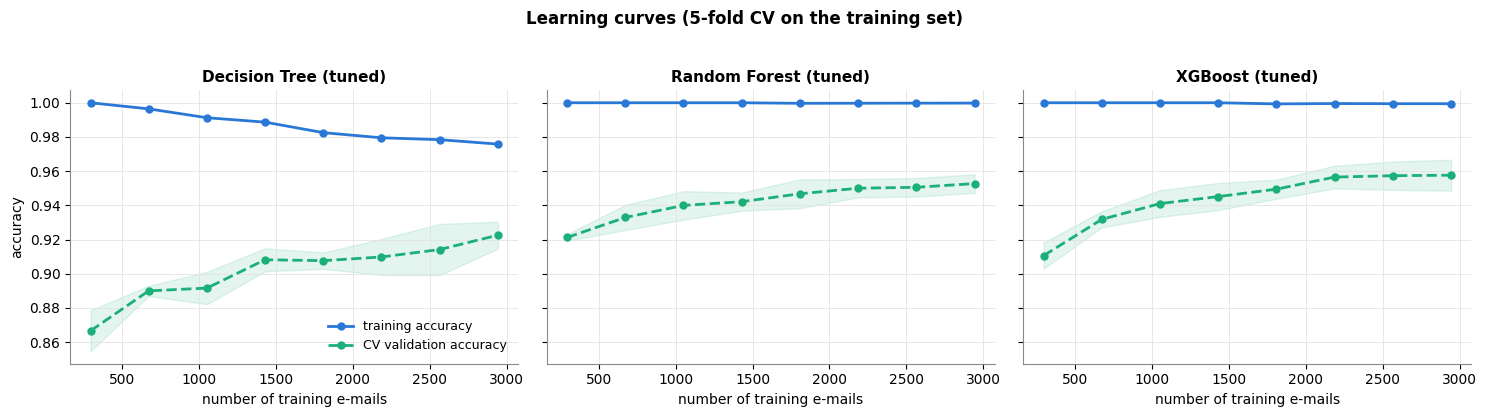

model,Decision Tree,Random Forest,XGBoost
train_size,,,
294,0.8666,0.9212,0.9106
672,0.8899,0.9329,0.9318
1051,0.8916,0.9399,0.9410
1429,0.9082,0.9421,0.9451
1808,0.9076,0.9467,0.9495
2186,0.9098,0.9500,0.9565
2565,0.9141,0.9505,0.9573
2944,0.9226,0.9527,0.9576


In [36]:
from sklearn.model_selection import learning_curve

sizes = np.linspace(0.1, 1.0, 8); rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, name in zip(axes, ["Decision Tree", "Random Forest", "XGBoost"]):
    n_tr, tr, va = learning_curve(clone(t5_gs[name].best_estimator_), X_train, y_train, train_sizes=sizes, cv=skf(5), n_jobs=N_JOBS)
    ax.plot(n_tr, tr.mean(1), marker="o", ms=5, color=PALETTE[0], label="training accuracy")
    ax.plot(n_tr, va.mean(1), marker="o", ms=5, ls="--", color=PALETTE[2], label="CV validation accuracy")
    ax.fill_between(n_tr, va.mean(1) - va.std(1), va.mean(1) + va.std(1), color=PALETTE[2], alpha=0.12)
    ax.set(xlabel="number of training e-mails", title=f"{name} (tuned)")
    rows += [{"model": name, "train_size": int(a), "train_acc": b, "cv_val_acc": c, "cv_val_std": d}
             for a, b, c, d in zip(n_tr, tr.mean(1), va.mean(1), va.std(1, ddof=1))]
axes[0].set_ylabel("accuracy"); axes[0].legend(loc="lower right", fontsize=9)
fig.suptitle("Learning curves (5-fold CV on the training set)", fontweight="bold", y=1.03)
fig.tight_layout(); save_fig(fig, "x3_learning_curves"); plt.show()
x3_lc = save_table(pd.DataFrame(rows), "x3_learning_curves")
display(x3_lc.pivot(index="train_size", columns="model", values="cv_val_acc").round(4))

**Interpretation (Figure `x3_learning_curves`, Table `x3_learning_curves`).**
* **Decision Tree:** validation accuracy is still climbing at full size (0.867 at 294 e-mails → 0.923 at 2,944), and its gap to training accuracy shrinks from 13 to 5 points but does not close. It is a high-variance model that would still profit from more data.
* **Random Forest** (0.921 → 0.953) and **XGBoost** (0.911 → 0.958) improve quickly up to about 1,800–2,200 e-mails and then flatten. XGBoost gains only +0.1 point over the last 750 e-mails (0.9565 → 0.9576), and RF +0.3 points.
* **Training accuracy stays near 1.0** for both ensembles at every size, so the train–validation gap is closing slowly *from below* (validation rising), not from above.
* **Conclusion:** for the ensembles, more e-mails of the same kind would buy little. The remaining errors come from the limits of the 57 hand-crafted features (see the error analysis), not from too little data. More data would help the single tree most, but ensembling already solves its variance problem far more cheaply.

## X4. How reliable is the clustering? (Wholesale)
**X4a — Bootstrap stability.** For each k, K-Means is refitted on 50 bootstrap samples of the 440 customers (standardized features, `n_init=10`). Each refit then labels all 440 customers, and we compare those labels with the full-data clustering using ARI. A real structure is reproduced on resampled data (ARI near 1); an artefact is not.

**X4b — Gap statistic** (Tibshirani, Walther & Hastie, 2001), implemented directly with NumPy: compare log(inertia) with its expectation under a structure-free reference. The reference is uniform in the PCA-aligned bounding box of the standardized data, with B = 20 reference sets. Rule: choose the smallest k with Gap(k) ≥ Gap(k+1) − s(k+1).

,k,mean_ARI,std_ARI,min_ARI,share_of_resamples_ARI_above_0.8,share_of_refits_with_tiny_cluster,mean_ARI_when_no_tiny_cluster
0,2,0.564,0.269,0.021,0.26,0.34,0.726
1,3,0.557,0.202,0.087,0.16,0.96,0.409
2,4,0.614,0.251,0.185,0.28,1.00,NaN
3,5,0.755,0.124,0.464,0.44,1.00,NaN
4,6,0.728,0.145,0.432,0.34,1.00,NaN


,k,log_W,expected_log_W_reference,gap,s_k,gap_rule_satisfied
0,1,7.8785,10.4381,2.5596,0.0200,False
1,2,7.5787,10.1604,2.5817,0.0188,False
2,3,7.3830,10.0237,2.6407,0.0177,False
3,4,7.1837,9.9097,2.7260,0.0199,False
4,5,6.9649,9.8196,2.8548,0.0213,False
5,6,6.8197,9.7356,2.9158,0.0199,False
6,7,6.7159,9.6662,2.9503,0.0207,False
7,8,6.6031,9.6005,2.9974,0.0201,False
8,9,6.4944,9.5440,3.0496,0.0210,False
9,10,6.4067,9.4933,3.0865,0.0225,False


gap-statistic choice (smallest k satisfying the rule): None | k with maximum gap: 10


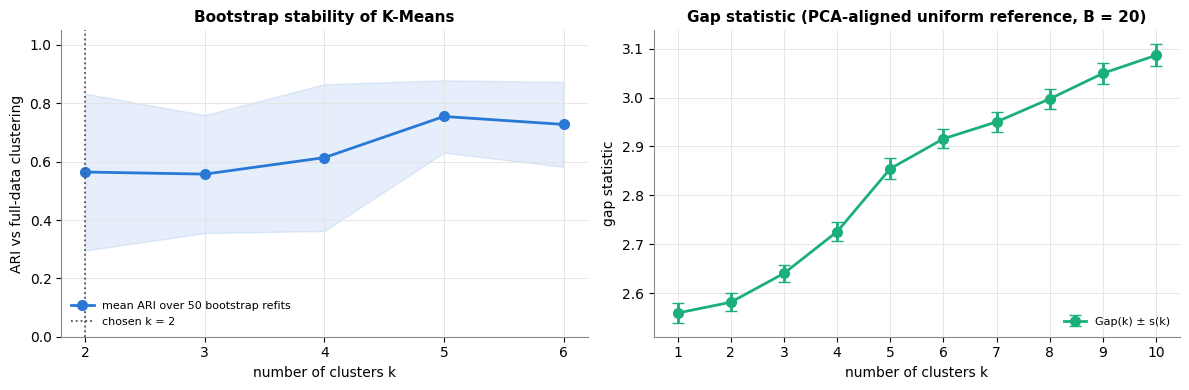

In [37]:
rng = np.random.default_rng(SEED); B_STAB = 50; rows = []
for k in range(2, 7):
    ref_k = km(k).fit_predict(Z_std)
    aris, small = [], []
    for _ in range(B_STAB):
        lab_b = km(k).fit(Z_std[rng.integers(0, len(Z_std), len(Z_std))]).predict(Z_std)
        aris.append(adjusted_rand_score(ref_k, lab_b))
        small.append(np.bincount(lab_b, minlength=k).min() / len(lab_b) < 0.05)   # a cluster spent on < 5% of customers
    rows.append({"k": k, "mean_ARI": np.mean(aris), "std_ARI": np.std(aris, ddof=1), "min_ARI": np.min(aris),
                 "share_of_resamples_ARI_above_0.8": np.mean(np.array(aris) > 0.8),
                 "share_of_refits_with_tiny_cluster": np.mean(small),
                 "mean_ARI_when_no_tiny_cluster": np.mean(np.array(aris)[~np.array(small)]) if (~np.array(small)).any() else np.nan})
x4_stab = save_table(pd.DataFrame(rows), "x4_bootstrap_stability")
display(x4_stab.round(3))
KEY["X4 bootstrap ARI at chosen k"] = x4_stab.loc[x4_stab.k == CHOSEN_K, "mean_ARI"].item()

rng = np.random.default_rng(SEED); B_GAP = 20
Zc = Z_std - Z_std.mean(0)
_, _, Vt = np.linalg.svd(Zc, full_matrices=False)
Zr = Zc @ Vt.T; lo_, hi_ = Zr.min(0), Zr.max(0)
refs = [rng.uniform(lo_, hi_, size=Zr.shape) @ Vt for _ in range(B_GAP)]
rows = []
for k in range(1, 11):
    logw = np.log(km(k).fit(Z_std).inertia_)
    ref_logw = np.array([np.log(km(k).fit(R).inertia_) for R in refs])
    rows.append({"k": k, "log_W": logw, "expected_log_W_reference": ref_logw.mean(), "gap": ref_logw.mean() - logw,
                 "s_k": ref_logw.std() * np.sqrt(1 + 1 / B_GAP)})
x4_gap = pd.DataFrame(rows)
x4_gap["gap_rule_satisfied"] = [bool(i < len(x4_gap) - 1 and x4_gap.gap[i] >= x4_gap.gap[i + 1] - x4_gap.s_k[i + 1]) for i in range(len(x4_gap))]
save_table(x4_gap, "x4_gap_statistic")
display(x4_gap.round(4))
gap_k = int(x4_gap.loc[x4_gap.gap_rule_satisfied, "k"].iloc[0]) if x4_gap.gap_rule_satisfied.any() else None
print("gap-statistic choice (smallest k satisfying the rule):", gap_k, "| k with maximum gap:", int(x4_gap.loc[x4_gap.gap.idxmax(), "k"]))
KEY["X4 gap-statistic k"] = gap_k if gap_k is not None else np.nan

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(x4_stab.k, x4_stab.mean_ARI, marker="o", ms=7, color=PALETTE[0], label="mean ARI over 50 bootstrap refits")
axes[0].fill_between(x4_stab.k, x4_stab.mean_ARI - x4_stab.std_ARI, np.minimum(1, x4_stab.mean_ARI + x4_stab.std_ARI), color=PALETTE[0], alpha=0.12)
axes[0].axvline(CHOSEN_K, ls=":", color=GRAY, lw=1.3, label=f"chosen k = {CHOSEN_K}")
axes[0].set(xlabel="number of clusters k", ylabel="ARI vs full-data clustering", title="Bootstrap stability of K-Means", ylim=(0, 1.05), xticks=range(2, 7))
axes[0].legend(fontsize=8, loc="lower left")
axes[1].errorbar(x4_gap.k, x4_gap.gap, yerr=x4_gap.s_k, marker="o", ms=7, capsize=4, color=PALETTE[2], label="Gap(k) ± s(k)")
if gap_k is not None:
    axes[1].axvline(gap_k, ls=":", color=GRAY, lw=1.3, label=f"gap rule → k = {gap_k}")
axes[1].set(xlabel="number of clusters k", ylabel="gap statistic", title="Gap statistic (PCA-aligned uniform reference, B = 20)", xticks=range(1, 11))
axes[1].legend(fontsize=8, loc="lower right")
fig.tight_layout(); save_fig(fig, "x4_stability_and_gap"); plt.show()

**Interpretation (Tables `x4_bootstrap_stability`, `x4_gap_statistic`, Figure `x4_stability_and_gap`).** These two checks are less flattering for Task 4, and we report them as they are.

**Stability.**
* **k=2 is only moderately stable:** mean ARI 0.56 (std 0.27), and only 26% of the 50 bootstrap refits reproduce the full-data partition with ARI > 0.8.
* **The added diagnostic shows why.** In **34% of refits** at k=2, K-Means spends one of its two centroids on a tiny group (< 5% of customers). A bootstrap sample that happens to duplicate the extreme spenders pulls a centroid onto them. In the other 66% of refits the familiar retail-vs-rest split re-appears, with mean ARI 0.73.
* **The instability therefore comes from the outliers, not from the main split.** It is the same weakness of K-Means on heavy-tailed data that Section 4.6 discussed.
* **k=3 is no more stable** (mean ARI also 0.56, and only 16% of refits reach ARI > 0.8 vs 26% at k=2), with a tiny cluster in 96% of refits (on the full data, too, its third cluster has only 2 customers).
* **k=5 has the highest mean ARI (0.75)**, because with five centroids the outliers reliably get clusters of their own and the large clusters stop moving. But the k=5 partition contains a one-customer cluster (`t4_k_sweep`), so its "stability" is stability of outlier flags, not of segments. We keep k=2.
* **Lesson:** k=2 should be read as a *soft* boundary in a continuum. A production segmentation should first cap or remove the extreme spenders, or use a log scale; the log scale is balanced but weakly separated, as shown in 4.1.

**Gap statistic (unsuccessful as a selection tool).**
* Gap(k) rises monotonically from k=1 (2.56) to k=10 (3.09), so the rule "smallest k with Gap(k) ≥ Gap(k+1) − s(k+1)" is **never satisfied**.
* **Reason:** the reference distribution is uniform over the bounding box of the data, and that box is stretched by a few customers 8–16 standard deviations from the centre. Compared with that almost empty box, the dense core looks "highly clustered" at every k. Each extra centroid spent on outliers keeps increasing the gap.
* The gap statistic assumes compact clusters without extreme tails, so it is uninformative here. We keep it as a documented negative result. Elbow (no sharp knee), silhouette (k = 2–3) and gap (no answer) together show that this dataset has no strong, unambiguous cluster structure.

## X5. One-figure overview of the project

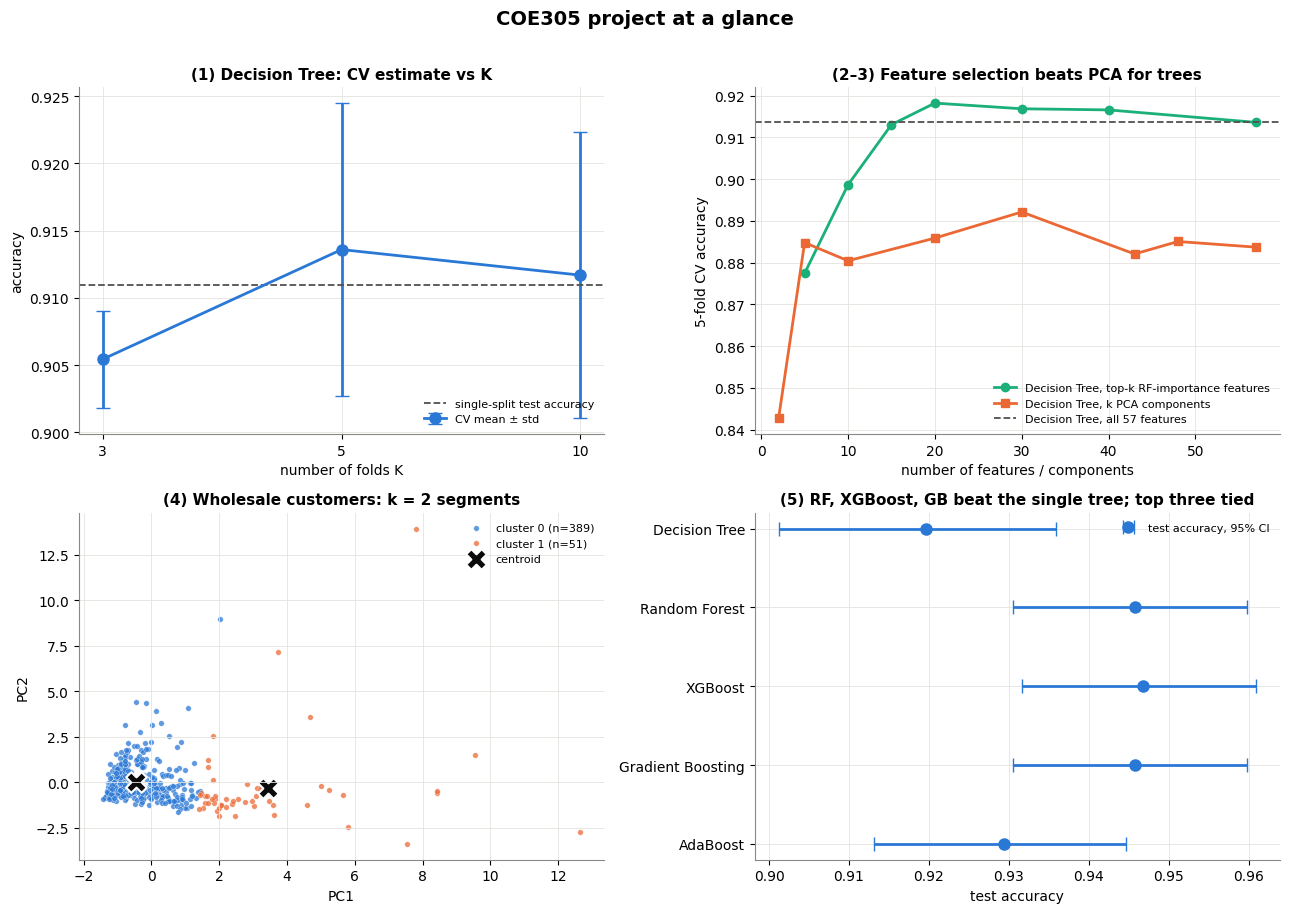

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
ax = axes[0, 0]                                                                    # Task 1 (reused)
ax.errorbar(t1_cv.K.astype(str), t1_cv.mean_accuracy, yerr=t1_cv.std_accuracy, marker="o", ms=8, capsize=5, color=PALETTE[0], label="CV mean ± std")
ax.axhline(t1_base.loc[1, "accuracy"], ls="--", color=GRAY, lw=1.3, label="single-split test accuracy")
ax.set(xlabel="number of folds K", ylabel="accuracy", title="(1) Decision Tree: CV estimate vs K"); ax.legend(fontsize=8, loc="lower right")
ax = axes[0, 1]                                                                    # Tasks 2-3 (reused)
ax.plot(t2_curve[t2_curve.method == "SelectFromModel (RF importance)"].k, t2_curve[t2_curve.method == "SelectFromModel (RF importance)"].cv_mean_acc,
        marker="o", color=PALETTE[2], label="Decision Tree, top-k RF-importance features")
ax.plot(t3_ncurve.n_components, t3_ncurve.cv_mean_acc_dtree, marker="s", color=PALETTE[1], label="Decision Tree, k PCA components")
ax.axhline(base_cv5, ls="--", color=GRAY, lw=1.3, label="Decision Tree, all 57 features")
ax.set(xlabel="number of features / components", ylabel="5-fold CV accuracy", title="(2–3) Feature selection beats PCA for trees"); ax.legend(fontsize=8, loc="lower right")
ax = axes[1, 0]                                                                    # Task 4 (reused)
for c in range(CHOSEN_K):
    msk = labels == c
    ax.scatter(P[msk, 0], P[msk, 1], s=16, alpha=0.75, color=PALETTE[c], edgecolor="white", linewidth=0.3, label=f"cluster {c} (n={msk.sum()})")
Cf = pca2.transform(final.cluster_centers_)
ax.scatter(Cf[:, 0], Cf[:, 1], marker="X", s=220, color="#0b0b0b", edgecolor="white", linewidth=1.5, label="centroid")
ax.set(xlabel="PC1", ylabel="PC2", title=f"(4) Wholesale customers: k = {CHOSEN_K} segments"); ax.legend(fontsize=8, loc="upper right")
ax = axes[1, 1]                                                                    # Task 5 + X1
d = x1_ci[x1_ci.metric == "accuracy"].set_index("model").loc[list(PRED)[::-1]]
ax.errorbar(d.point, range(len(d)), xerr=[d.point - d.ci_low, d.ci_high - d.point], fmt="o", ms=8, capsize=5, color=PALETTE[0], label="test accuracy, 95% CI")
ax.set_yticks(range(len(d)), d.index)
ax.set(xlabel="test accuracy", title="(5) RF, XGBoost, GB beat the single tree; top three tied"); ax.legend(fontsize=8, loc="upper right")
fig.suptitle("COE305 project at a glance", fontweight="bold", fontsize=14, y=1.01)
fig.tight_layout(); save_fig(fig, "x5_overview"); plt.show()

**Interpretation (Figure `x5_overview`).** One figure summarises the project:
* **(1)** 3-fold CV underestimates the tree's accuracy, while 5- and 10-fold agree with the single-split test score.
* **(2–3)** About 15–20 features chosen by RF importance match or beat all 57, while every PCA representation stays at least 2 points below for trees.
* **(4)** The Wholesale customers split into a large fresh-oriented group and a high-volume retail-basket group along PC1.
* **(5)** On the test set RF, XGBoost and GB each beat the single tree significantly and do not differ significantly from each other (McNemar's test with Holm correction, Section X1b); AdaBoost's lead over the tree is not significant. The 95% CIs show why claims finer than about ±1.5 points cannot be made from 921 test e-mails.

The figure is also used as the overview figure at the start of the report.

---
# Summary of key results
This table collects the headline numbers from all tasks (it is also used to check that a second clean run reproduces the same values).

In [39]:
t_key = save_table(pd.DataFrame({"quantity": list(KEY), "value": [float(v) for v in KEY.values()]}), "summary_key_results")
display(t_key.round(4))
print("Best Task 5 model (chosen by CV accuracy):", best_model.model, "| CV accuracy", round(best_model.cv_mean_acc, 4),
      "| test accuracy", round(best_model.accuracy, 4),
      "| precision", round(best_model.precision, 4), "| recall", round(best_model.recall, 4), "| F1", round(best_model.f1, 4))

,quantity,value
0,T1 baseline DT test accuracy,0.9110
1,T1 CV K=3 mean accuracy,0.9054
2,T1 CV K=5 mean accuracy,0.9136
3,T1 CV K=10 mean accuracy,0.9117
4,"T2 All features (Task 1 baseline, reused) test accuracy (k=57)",0.9110
5,T2 MI (SelectKBest) test accuracy (k=20),0.9099
6,T2 RFE (Decision Tree) test accuracy (k=40),0.9164
7,T2 SelectFromModel (RF importance) test accuracy (k=20),0.9229
8,T3 components for 90% variance,43.0000
9,T3 components for 95% variance,48.0000


Best Task 5 model (chosen by CV accuracy): XGBoost | CV accuracy 0.9576 | test accuracy 0.9468 | precision 0.9337 | recall 0.9311 | F1 0.9324


**Interpretation (Table `summary_key_results`).** CV estimates and test scores agree throughout: the Decision Tree is about 0.91–0.92 in Tasks 1, 2 and 5. Feature selection kept accuracy with about 20 of 57 features. PCA needed 43–48 components for 90–95% variance and never improved accuracy. K-Means on standardized spending found two segments (silhouette 0.547). Tree ensembles were the strongest models, and **XGBoost**, chosen by CV accuracy, also had the best test accuracy (0.9468) and F1 (0.9324). **The extra analyses add three findings:**
* XGBoost's test accuracy is 0.947 [95% CI 0.932, 0.961], and it is not significantly different from RF and GB.
* Its nested-CV accuracy (0.952) is consistent with a small optimism (about 0.5 points) in the tuned CV score.
* A cost-aware threshold cuts the cost of errors by 63%.

The k=2 clustering is only moderately stable under resampling (bootstrap ARI 0.56), because of outliers, and the gap statistic gives no answer. Its value in the table is empty (NaN) because no k satisfied the rule.

With the pinned packages this table is identical on Windows (Python 3.12 and 3.13), on Linux (Python 3.12) and with the uv install route. The other tables reproduce exactly only on the same platform: on Linux, `t5_search_gradient_boosting` (up to 10% relative on one entry), the `cv_std_acc` column of `t5_best_params` (2.2%), `x2_auc` (about 1e-4) and `x2_cost_threshold` (3.1%) differ slightly. The committed outputs and the report's numbers come from the Windows Python 3.12 run.

# Challenges, unsuccessful experiments and fixes
* **XGBoost rejected the original column names.** Spambase names six features `char_freq_;`, `char_freq_(`, `char_freq_[`, `char_freq_!`, `char_freq_$` and `char_freq_#`. XGBoost raises `ValueError: feature_names must be string, and may not contain [, ] or <`, and the first full run of the notebook failed in Task 5. *Fix:* `load_spambase` (data-loading cell) renames them to `char_freq_semicolon`, `char_freq_paren`, `char_freq_bracket`, `char_freq_excl`, `char_freq_dollar` and `char_freq_hash`. The text of this notebook still refers to them as `char_freq_!`/`$` where that is clearer.
* **Environment.** No Python was installed system-wide. We created a virtual environment with `uv` (Python 3.12) and pinned the versions in `requirements.txt`. The first install pulled pandas 3.x / scikit-learn 1.9 builds that failed to import (a pandas C-extension error). We pinned stable versions (pandas 2.2.3, scikit-learn 1.5.2, XGBoost 2.1.3). The `jupyter.exe` launcher was blocked by the Windows application-control policy, so the notebook is executed with `python -m jupyter nbconvert …`. On Windows, joblib prints a harmless `KeyError` while cleaning its temporary memmap folder *after* execution. It does not affect any result. The setup cell also ignores `FutureWarning`s and, after we checked they are harmless, two library warnings: SciPy's "Unknown solver options: iprint", raised because scikit-learn 1.5 still passes that option to L-BFGS, and a NumPy masked-array cast warning that `GridSearchCV` raises when a grid contains `max_depth=None`. The data-loading cell ignores the warnings of `sklearn.datasets._openml`, the module behind the OpenML download fallback.
* **Task 4: first choice of k.** Our first draft hard-coded k=3 because it had the highest silhouette. The resulting third cluster contained just **2 customers**, and its silhouette was only 0.001 above k=2. We then wrote an explicit rule (silhouette within 0.01 of the best plus at least 5% of customers in the smallest cluster), which selects k=2. Because the rule was written after seeing the result, we added a robustness check (4.7: capping the extreme spenders) instead of relying on it alone. The k=3 result is kept and shown as the alternative.
* **Task 3: unequal grids in the first version.** Set-up (c) was first searched only over n ≤ 20 components while (b) could use up to 57, which handicapped (c). *Fix:* (c) now uses every n of the (b) grid up to its input size k, plus n = k. With the fair grid CV chose no compression at all.
* **Task 5: unequal tuning budgets.** XGBoost's grid (36 settings) is larger than the others'. Rather than re-tune everything, we added the equal-budget check in 5.2b.
* **Task 3: PCA "won" by not reducing anything.** CV selected all 57 components for logistic regression, which is mathematically the same model as no PCA. To still report a real reduced representation we added the 95%-variance rule (48 components, fixed from training variance), which was slightly *worse* (test 0.9273 vs 0.9294).
* **Unsuccessful or worse settings (kept, not hidden):**
  * the unrestricted Decision Tree (test 0.9110) was worse than the depth-tuned and CV-pruned trees;
  * K=3 CV under-estimates accuracy;
  * k ≤ 10 selected features under-fit (0.86–0.90 CV);
  * MI selection did not beat the baseline on the test set (0.9099);
  * MI → PCA (test 0.9262; CV chose no compression, and every compressed setting was worse) was below both (a) and (b);
  * PCA lowered the Decision Tree (0.8817), Random Forest (0.9164) and XGBoost (0.9240);
  * AdaBoost with stumps trailed the other ensembles;
  * XGBoost with lr 0.01 / 100 trees under-fit (CV 0.915–0.930);
  * RF with depth 5 under-fit (0.928);
  * the correlation-based feature subset and the log1p transform in Task 4 gave less useful clusterings;
  * the 1-SE pruning rule produced a simpler but less accurate tree (0.9088).
* **Problems in the extra analyses.**
  * The first error-analysis cell crashed because `np.select` was given string choices with its default integer fallback value (`TypeError: Choicelist and default value do not have a common dtype`). *Fix:* `default=""`.
  * The gap statistic failed to select any k (see X4).
  * The bootstrap stability of k=2 turned out lower than expected. Instead of hiding it, we added a diagnostic column showing that the instability comes from refits that capture outliers.
  * After the `.venv` was deleted on Windows, the notebook is executed with the uv-managed Python directly.
* **Test-set discipline.** In 5.4 and 5.7 the task asks for test-accuracy curves. They are plotted for illustration only. Every choice (max_depth, α, k, number of components) was made from the CV columns, and in 5.7 the test curve peaks at a different α than the one we selected.

# Results reused across tasks
* **Task 1 → Task 2:** the all-feature Decision Tree baseline (Task 1 CV K=5 mean accuracy 0.9136 and the Task 1 test metrics) is the horizontal reference line and the first row of `t2_test_results`.
* **Task 2 → Tasks 3 and 5:** the seeded mutual-information scorer `mi_score` (and the SelectKBest set-up) is reused for (c) in Task 3 and for the feature-selection variant in 5.5.
* **Task 1 → Task 3:** the Decision Tree with original features in the "extra" rows of `t3_setup_comparison` is the Task 1 model (same CV and test numbers).
* **Task 3 → Task 4** (method only): the same StandardScaler → PCA pattern, applied to the Wholesale data.
* **Task 4.3/4.6 → 4.7:** the k-selection rule and the final k=2 labels (ARI reference) are reused in the capping check.
* **Task 5.2 → 5.2b:** the equal-budget check re-uses the CV scores of the grid searches; no model is refitted.
* **Task 4.1 → 4.5:** the standardized and log1p-standardized matrices `Z_std`, `Z_log`. 4.5 refits its ARI reference partition on `Z_std` with the k chosen in 4.3 (k=2).
* **Task 5.2 → 5.4 / 5.5 / 5.7:** the CV-selected XGBoost n_estimators and learning_rate (fixed in the XGBoost validation curve), the tuned RF and XGBoost hyper-parameters (5.5), and the depth-tuned tree (5.7 summary).
* **Task 5.3 → 5.5:** baseline test metrics of RF and XGBoost.
* **Task 1 → 5.7:** the unpruned tree (α = 0) is the Task 1 baseline (identical 237 leaves and test accuracy 0.9110).
* The split itself (`get_split`, stratified, test_size = 0.2, random_state = 42) is created once in Section 0 and used by Tasks 1, 2, 3 and 5.
* **Task 5 → extras X1–X3:** all five fitted, tuned models from 5.2 (`t5_gs`), the same hyper-parameter grids (nested CV), the best model from 5.3 (`best_model`) and the tuned settings for the out-of-fold cost curves and learning curves.
* **Task 2 → X2c, X3a:** the RF-importance and MI rankings (`rf_imp`, `mi_vals`) choose the features in the error analysis and are compared with permutation importance.
* **Task 4 → X4:** `Z_std`, the K-Means settings (`km`) and the chosen k.
* **Tasks 1–5 → X5:** the overview figure re-plots `t1_cv`, `t2_curve`, `t3_ncurve`, the Task 4 PCA projection and the X1 bootstrap intervals.